In [93]:
import xarray as xr
import pandas as pd
import numpy as np
import glob
import os
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

## GOES along trajectories

In [94]:
#with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_with_goes.nc') as ds:
#    bt_with_goes = ds.load()

with xr.open_dataset('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/bt_with_goes_BT14_partial.nc') as ds:
    bt_with_goes = ds.load()

In [95]:
bt_with_goes['goes_cat_at_ec_overpass'] = (bt_with_goes.sel(timestep=0).goes_cats)

In [96]:
bt_with_goes

<xarray.Dataset> Size: 81MB
Dimensions:                  (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 103kB 2024-08-0...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 310kB '01009E' ... '08369E'
Data variables: (12/19)
    lat_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 4MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 4MB N...
    goes_cats                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 4MB nan ... nan
    ...                       ...
    goes_lat_mid             (time_startpoint, timestep) float64 4MB nan ... nan
    goes_BT14                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_ice_flag_2          (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lat_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lon_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cat_at_ec_overpass  (time_startpoint) float64 103kB 1.0 1.0 ... 3.0 3.0

## clean up the dataset

In [97]:
# clean up the bt_with_goes dataset: convert a goes_cats value that is surrounded by goes_cats values of all the same category to that category, even if the middle value is different 
# 1, 1, 1      1, 1, 1
# 1, 3, 1  --> 1, 1, 1
# 1, 1, 1      1, 1, 1

bt_with_goes_cleaned = None
orbits = np.unique(bt_with_goes['orbit'])
for orbit in orbits:
    bt_orbit = bt_with_goes.where(bt_with_goes['orbit'] == orbit, drop=True)
    da = bt_orbit['goes_cats']

    neighbors = [
        da.shift(time_startpoint=-1, timestep=-1), da.shift(time_startpoint=-1, timestep=0), da.shift(time_startpoint=-1, timestep=1),
        da.shift(time_startpoint=0,  timestep=-1),                                           da.shift(time_startpoint=0,  timestep=1),
        da.shift(time_startpoint=1,  timestep=-1), da.shift(time_startpoint=1,  timestep=0), da.shift(time_startpoint=1,  timestep=1),
    ]

    stacked = xr.concat(neighbors, dim="neighbor")

    all_equal = (stacked == stacked.isel(neighbor=0)).all("neighbor")
    no_nan_neighbors = ~stacked.isnull().any("neighbor")
    center_diff = da != stacked.isel(neighbor=0)

    isolated_mask = all_equal & no_nan_neighbors & center_diff
    N_isolated = isolated_mask.sum().values

    surround_val = stacked.isel(neighbor=3)
    corrected = da.where(~isolated_mask, surround_val)
    bt_orbit['goes_cats_original'] = da
    bt_orbit['goes_cats'] = corrected

    if bt_with_goes_cleaned is None:
        bt_with_goes_cleaned = bt_orbit.copy()
    else:
        bt_with_goes_cleaned = xr.concat([bt_with_goes_cleaned, bt_orbit], dim='time_startpoint')
    print(f'Orbit {orbit}: {N_isolated} isolated points corrected')

    #fig, (ax0,ax1) = plt.subplots(1,2, figsize=(10,4))
    #da.T.plot(ax=ax0)
    #corrected.T.plot(ax=ax1)
    #fig.tight_layout()
    #plt.show()


Orbit 01009E: 1 isolated points corrected
Orbit 01024E: 1 isolated points corrected
Orbit 01040E: 0 isolated points corrected
Orbit 01056E: 0 isolated points corrected
Orbit 01071E: 1 isolated points corrected
Orbit 01087E: 0 isolated points corrected
Orbit 01102E: 0 isolated points corrected
Orbit 01133E: 0 isolated points corrected
Orbit 01164E: 1 isolated points corrected
Orbit 01180E: 0 isolated points corrected
Orbit 01195E: 0 isolated points corrected
Orbit 01211E: 0 isolated points corrected
Orbit 01227E: 0 isolated points corrected
Orbit 01242E: 0 isolated points corrected
Orbit 01258E: 0 isolated points corrected
Orbit 01273E: 1 isolated points corrected
Orbit 01289E: 1 isolated points corrected
Orbit 01304E: 0 isolated points corrected
Orbit 01320E: 0 isolated points corrected
Orbit 01335E: 0 isolated points corrected
Orbit 01351E: 1 isolated points corrected
Orbit 01367E: 0 isolated points corrected
Orbit 01382E: 1 isolated points corrected
Orbit 01398E: 0 isolated points co

In [98]:
# manual clean-up for few orbits, where we saw misclassifications of the CNN (some dissipating or forming clouds were classified as open cells):
# '01631E' # patch of dried out clouds? forming clouds?
# '02005E' # misclassification of the CNN
# '05848E' # dissipating clouds (instead of transitioning to open cells)
# '07575E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '07077E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '02518E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '06486E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '02518E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '06486E' # patch of dry clouds? forming clouds? (only at latitudes -19 - -22)
# '06719E' # patch of dry clouds? forming clouds? (only at latitudes -17 - -19)

bt_with_goes_cleaned = bt_with_goes_cleaned.where(
                            (bt_with_goes_cleaned.orbit != '01631E') 
                            & (bt_with_goes_cleaned.orbit != '02005E') 
                            & (bt_with_goes_cleaned.orbit != '05848E') 
                            & ~((bt_with_goes_cleaned.orbit == '07575E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '07077E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '02518E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '06486E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '02518E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '06486E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -19))
                            & ~((bt_with_goes_cleaned.orbit == '06719E') & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj < -17) & (bt_with_goes_cleaned.sel(timestep=0).drop_vars('timestep').lat_traj > -19))
                            ,
                            drop=True)

In [99]:
bt_with_goes_cleaned

<xarray.Dataset> Size: 84MB
Dimensions:                  (time_startpoint: 12813, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 103kB 2024-08-0...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 308kB '01009E' ... '08369E'
Data variables: (12/20)
    lat_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    lon_traj                 (time_startpoint, timestep) float64 4MB nan ... nan
    plev_traj                (time_startpoint, timestep) float64 4MB nan ... nan
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 4MB N...
    goes_cats                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cert                (time_startpoint, timestep) float64 4MB nan ... nan
    ...                       ...
    goes_BT14                (time_startpoint, timestep) float64 4MB nan ... nan
    goes_ice_flag_2          (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lat_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_lon_mid_2           (time_startpoint, timestep) float64 4MB nan ... nan
    goes_cat_at_ec_overpass  (time_startpoint) float64 103kB 1.0 1.0 ... 3.0 3.0
    goes_cats_original       (time_startpoint, timestep) float64 4MB nan ... nan

## retrieve time to/from transitions

In [100]:
def get_transition_properties(bt_dataset, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True):
    """
    Find where trajectories transition from cat0 to cat1 (e.g. open to closed cells)
    going backwards or forwards in time from timestep=0.
    
    Parameters:
    -----------
    bt_dataset : xarray.Dataset
        Dataset with goes_cats, datetime_traj variables
    transition_from_goes_cats : list
        List of MSI categories to transition from (default: [2])
    transition_to_goes_cats : list
        List of GOES categories to transition to (default: [0, 1])
    backward : bool
        Whether to search backwards in time (default: True)

    Returns:
    --------
    xarray.Dataset
        Dataset with added variables:
        - transition_flag: boolean flag indicating if transition occurred
        - transition_timestep: timestep where transition occurs (first stratiform point)
        - transition_datetime: datetime at transition (mean between last non-stratiform and first stratiform)
        - transition_time_diff: time difference from timestep=0 to transition
        - transition_uncertainty: time uncertainty of transition (half the time difference between last non-stratiform and first stratiform)
    """
    
    # Get dimensions
    n_startpoints = len(bt_dataset.time_startpoint)
    
    # Initialize arrays for results
    transition_flag = np.full(n_startpoints, False)
    transition_timestep = np.full(n_startpoints, np.nan)
    transition_datetime = np.full(n_startpoints, np.datetime64('NaT'), dtype='datetime64[ns]')
    transition_time_diff = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    transition_uncertainty = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    
    # Get timesteps sorted from 0 to negative values
    timesteps = bt_dataset.timestep.values
    if backward:
        timesteps_sorted = np.sort(timesteps)[::-1]  # Descending order: 0, -1, -2, ...
    else:
        timesteps_sorted = np.sort(timesteps)  # Ascending order: 0, 1, 2, ...
    
    for i in range(n_startpoints):
        traj = bt_dataset.isel(time_startpoint=i)
        
        # Check if timestep=0 has the correct goes category to start from
        goes_cat_at_zero = float(traj.sel(timestep=0).goes_cats.values)
        if goes_cat_at_zero not in transition_from_goes_cats:
            continue  # Skip if not starting from desired GOES category
        
        # Get the datetime at timestep=0 for reference
        reference_datetime = traj.sel(timestep=0).datetime_traj.values
            
        # Look through timesteps from 0 backwards to find transition
        last_cat0_timestep = None
        last_cat0_datetime = None
        first_cat1_timestep = None
        first_cat1_datetime = None
        
        for timestep in timesteps_sorted:
            if backward and timestep > 0:
                continue  # Only look at timestep=0 and negative values
            elif not backward and timestep < 0:
                continue  # Only look at timestep=0 and positive values
                
            try:
                cats_value = float(traj.sel(timestep=timestep).goes_cats.values)
                
                # Skip if NaN
                if pd.isna(cats_value):
                    continue
                
                # If still in the from category, keep looking
                if cats_value in transition_from_goes_cats:
                    # update last cat0
                    last_cat0_timestep = timestep
                    last_cat0_datetime = traj.sel(timestep=timestep).datetime_traj.values
                # If the cat value has changed (i.e. clouds have transitioned)
                elif cats_value not in transition_from_goes_cats:
                    # Check if the clouds at timestep are cat1
                    if cats_value in transition_to_goes_cats:
                        first_cat1_timestep = timestep
                        first_cat1_datetime = traj.sel(timestep=timestep).datetime_traj.values
                        break
                    else:
                        # Transition to an unexpected category, stop searching
                        break  
                    
            except (KeyError, ValueError):
                continue  # Skip if timestep doesn't exist or other errors
        
        # If we found a transition, calculate the mean time and uncertainty
        if (first_cat1_timestep is not None and 
            last_cat0_timestep is not None and 
            first_cat1_datetime is not None and 
            last_cat0_datetime is not None):
            
            # Convert to pandas datetime for easier arithmetic
            first_strat_dt = pd.to_datetime(first_cat1_datetime)
            last_non_strat_dt = pd.to_datetime(last_cat0_datetime)
            ref_dt = pd.to_datetime(reference_datetime)
            
            # Calculate mean time between last non-stratiform and first stratiform
            mean_transition_time = last_non_strat_dt + (first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate uncertainty (half the time difference between the two points)
            uncertainty = np.abs(first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate time difference from timestep=0 to mean transition time
            time_diff_to_transition = ref_dt - mean_transition_time


            # if transition is during the night (i.e. last cat on day0 is cat0, and first cat on day1 is cat1), BT14 is used as an indicator of the exact transition time
            transition_during_night = (uncertainty > pd.Timedelta(hours=3))
            if transition_during_night and traj.sel(timestep=0).goes_BT14.values is not np.nan:
                # all BT14 values during the night should be between the last cat0 and first cat1 timesteps, so we can use them to find the transition time more precisely
                timesteps_during_night = slice(last_cat0_timestep, first_cat1_timestep) if not backward else slice(first_cat1_timestep, last_cat0_timestep)
                BT14_during_night = traj.sel(timestep=timesteps_during_night).goes_BT14
                # find the timestep where BT14 changes most drastically, which should indicate the transition time
                BT14_diff = np.abs(BT14_during_night.diff(dim='timestep'))
                if len(BT14_diff) > 0 and not np.all(np.isnan(BT14_diff.values)):
                    idx_max_diff = BT14_diff.argmax()
                    last_cat0_timestep = BT14_diff['timestep'][idx_max_diff-1].values
                    first_cat1_timestep = BT14_diff['timestep'][idx_max_diff].values
                    last_cat0_datetime = traj.sel(timestep=last_cat0_timestep).datetime_traj.values
                    first_cat1_datetime = traj.sel(timestep=first_cat1_timestep).datetime_traj.values
                    # update mean_transition_time and time_diff_to_transition to the time corresponding to the max BT14 change
                    mean_transition_time = pd.to_datetime(last_cat0_datetime) + (pd.to_datetime(first_cat1_datetime) - pd.to_datetime(last_cat0_datetime)) / 2
                    time_diff_to_transition = ref_dt - mean_transition_time
                        
                
            
            # Store results
            transition_flag[i] = True
            transition_timestep[i] = first_cat1_timestep
            transition_datetime[i] = mean_transition_time.to_numpy().astype('datetime64[ns]')
            transition_time_diff[i] = time_diff_to_transition.to_numpy().astype('timedelta64[ns]')
            transition_uncertainty[i] = uncertainty.to_numpy().astype('timedelta64[ns]')
    
    # Add results to dataset
    result = bt_dataset.copy()
    result['transition_flag'] = xr.DataArray(transition_flag, dims='time_startpoint')
    result['transition_timestep'] = xr.DataArray(transition_timestep, dims='time_startpoint')
    result['transition_datetime'] = xr.DataArray(transition_datetime, dims='time_startpoint')
    result['transition_time_diff'] = xr.DataArray(transition_time_diff, dims='time_startpoint')
    result['transition_uncertainty'] = xr.DataArray(transition_uncertainty, dims='time_startpoint')
    result['transition_time_diff'] = result.transition_time_diff.dt.total_seconds() / 3600
    result['transition_uncertainty'] = result.transition_uncertainty.dt.total_seconds() / 3600

    # Add attributes
    result['transition_flag'].attrs = {'description': f'Boolean flag indicating if transition from cats = {transition_from_goes_cats} to cats = {transition_to_goes_cats} occurred'}
    result['transition_timestep'].attrs = {'description': 'Timestep where transition from open to stratiform occurs (timestep of first stratiform point)'}
    result['transition_datetime'].attrs = {'description': 'Mean datetime at transition point (mean between last non-stratiform and first stratiform)'}
    result['transition_time_diff'].attrs = {'description': 'Time difference from timestep=0 to mean transition time (positive means transition is earlier)'}
    result['transition_uncertainty'].attrs = {'description': 'Uncertainty in transition time (half the time between last non-stratiform and first stratiform)'}
    
    return result

In [101]:
# Apply to your open cell trajectories
bt_O = bt_with_goes_cleaned.where(bt_with_goes_cleaned.goes_cat_at_ec_overpass == 2, drop=True)
bt_co_back_from_o = get_transition_properties(bt_O, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True)
# Check results
print("Transition statistics C -> O backwards from O:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co_back_from_o.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co_back_from_o.time_startpoint)}")

bt_C = bt_with_goes_cleaned.where(bt_with_goes_cleaned.goes_cat_at_ec_overpass == 1, drop=True)
bt_co_forward_from_c = get_transition_properties(bt_C, transition_from_goes_cats=[1], transition_to_goes_cats=[2], backward=False)
# Check results
print("Transition statistics C -> O forwards from C:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co_forward_from_c.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co_forward_from_c.time_startpoint)}")

Transition statistics C -> O backwards from O:
Trajectories with transitions: 530
Total trajectories: 1181
Transition statistics C -> O forwards from C:
Trajectories with transitions: 455
Total trajectories: 2616


### check transition detection visually

In [10]:
bt_co_back_from_o

<xarray.Dataset> Size: 8MB
Dimensions:                  (time_startpoint: 1181, timestep: 43)
Coordinates:
  * time_startpoint          (time_startpoint) datetime64[ns] 9kB 2024-08-03T...
  * timestep                 (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                    (time_startpoint) <U6 28kB '01040E' ... '08353E'
Data variables: (12/25)
    lat_traj                 (time_startpoint, timestep) float64 406kB -18.36...
    lon_traj                 (time_startpoint, timestep) float64 406kB -77.95...
    plev_traj                (time_startpoint, timestep) float64 406kB 952.3 ...
    datetime_traj            (time_startpoint, timestep) datetime64[ns] 406kB ...
    goes_cats                (time_startpoint, timestep) float64 406kB nan .....
    goes_cert                (time_startpoint, timestep) float64 406kB nan .....
    ...                       ...
    goes_cats_original       (time_startpoint, timestep) float64 406kB nan .....
    transition_flag          (time_startpoint) bool 1kB True True ... True False
    transition_timestep      (time_startpoint) float64 9kB -4.0 -8.0 ... nan
    transition_datetime      (time_startpoint) datetime64[ns] 9kB 2024-08-03T...
    transition_time_diff     (time_startpoint) float64 9kB 5.0 9.0 ... 13.0 nan
    transition_uncertainty   (time_startpoint) float64 9kB 8.0 8.0 ... 8.0 nan

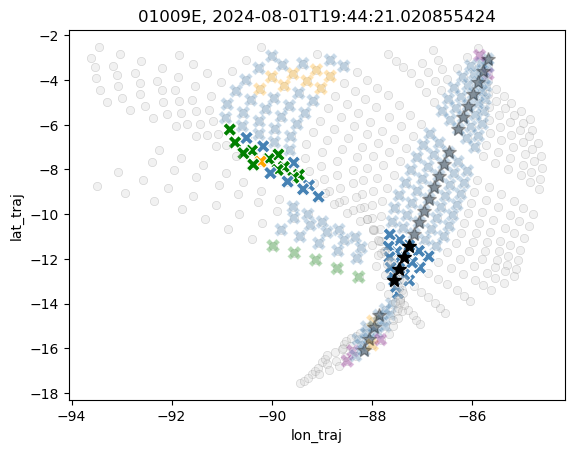

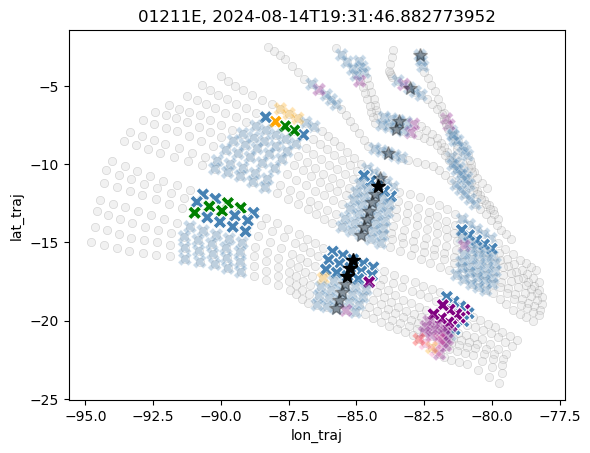

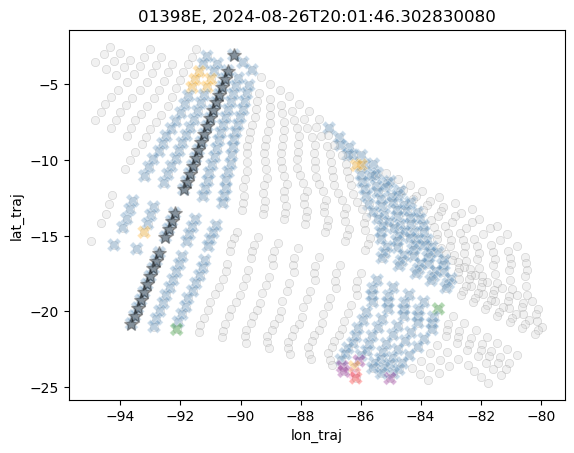

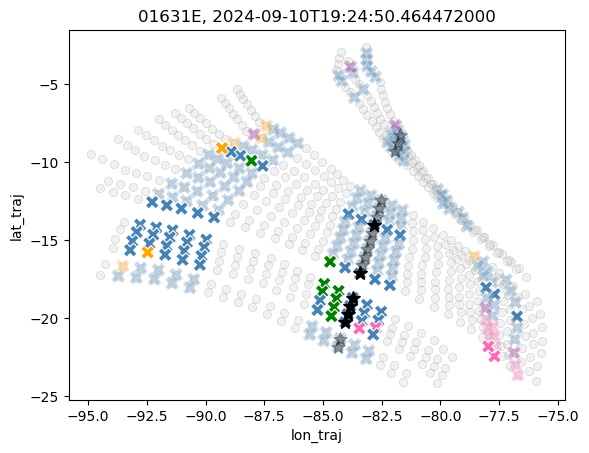

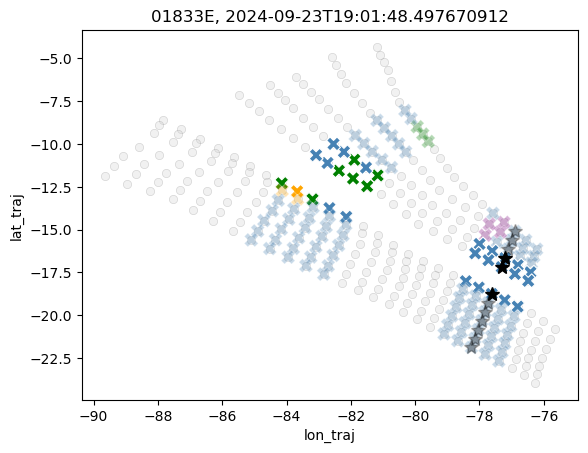

...

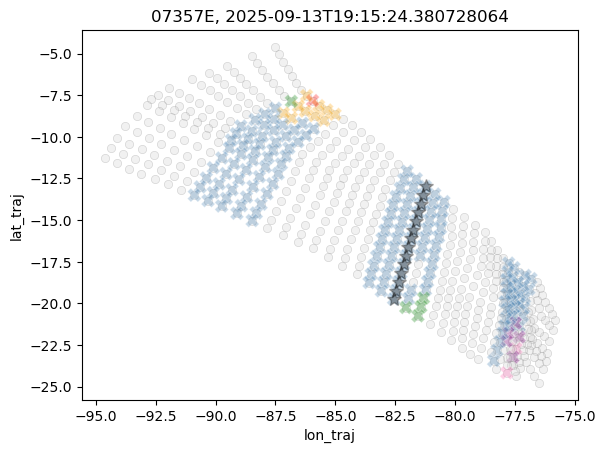

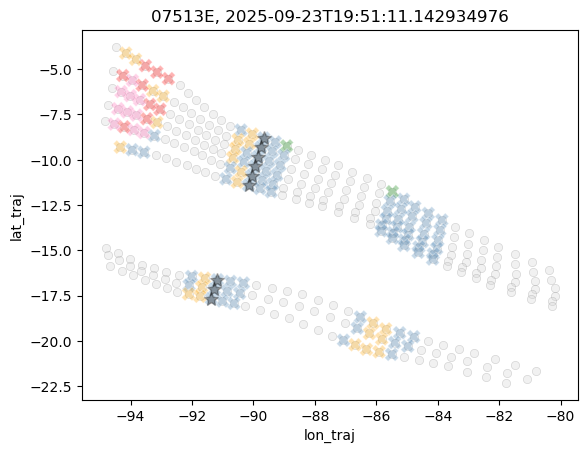

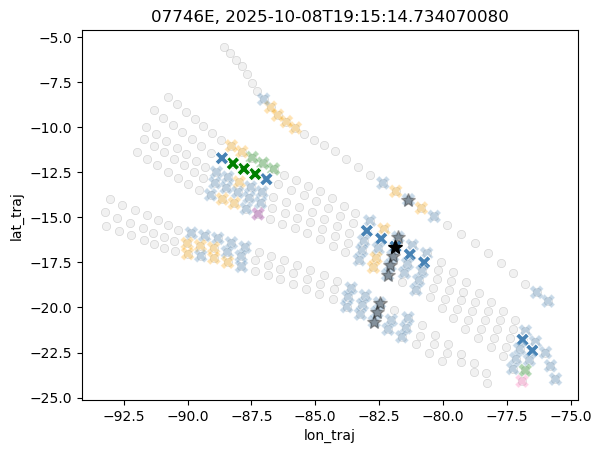

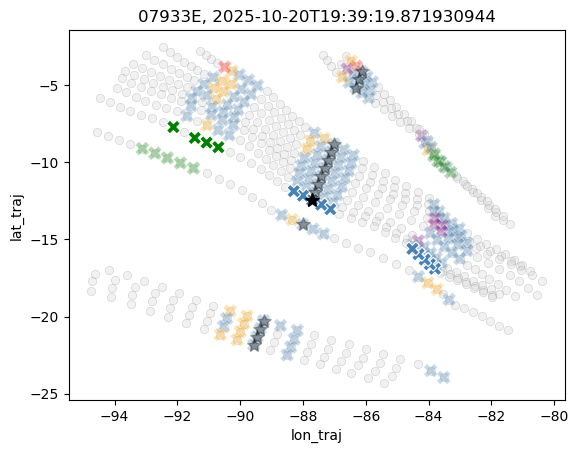

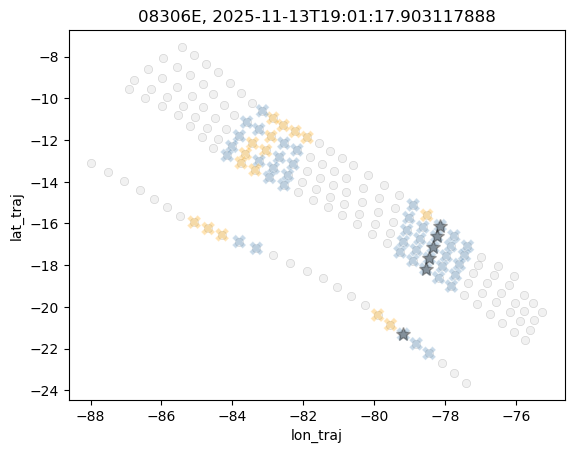

In [14]:
palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

ds_to_check = bt_co_forward_from_c #bt_co_back_from_o

for orbit in np.unique(ds_to_check.orbit)[::10]:
    bt_orbit = ds_to_check.where(ds_to_check.orbit == orbit, drop=True)
    for i in range(len(bt_orbit.time_startpoint)):
        tmp = bt_orbit.isel(time_startpoint=i)
        if tmp.transition_flag == False:
            # no transition detected
            alpha = 0.3
        else:
            # transition detected
            alpha = 1.0
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', color='lightgrey', alpha=0.3, edgecolor='Grey', legend=False)
        plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10, alpha=alpha)
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
    plt.title(f'{orbit}, {bt_orbit.time_startpoint.values[0]}')
    plt.show()

## add ACMCAP information

In [102]:
acmcap_dataset_filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu_1.h5'
acmcap = pd.read_hdf(acmcap_dataset_filename, key='StCu')

# only need SEP data
acmcap = acmcap[acmcap.stratus_region_index == 2]

ds_acmcap = acmcap.to_xarray()
ds_acmcap = ds_acmcap.rename({'time_mid':'time_startpoint'})
ds_acmcap = ds_acmcap.swap_dims({'index':'time_startpoint'})
ds_acmcap = ds_acmcap.assign_coords({
    'time_startpoint': ds_acmcap.time_startpoint.values,
    'orbit': ('time_startpoint', ds_acmcap.orbit.values)})
ds_acmcap = ds_acmcap.drop_vars(['index'])

ds_acmcap['time_startpoint'] = ds_acmcap.time_startpoint.dt.round('0.1s')
ds_acmcap = ds_acmcap.assign_coords({'timestep': ('timestep', [0])})

ds_acmcap

<xarray.Dataset> Size: 11MB
Dimensions:                               (time_startpoint: 12979, timestep: 1)
Coordinates:
    orbit                                 (time_startpoint) object 104kB '010...
  * time_startpoint                       (time_startpoint) datetime64[ns] 104kB ...
  * timestep                              (timestep) int64 8B 0
Data variables: (12/106)
    scene_id                              (time_startpoint) int64 104kB 25868...
    stratus_region_index                  (time_startpoint) int64 104kB 2 ... 2
    along_track_mid                       (time_startpoint) float64 104kB 128...
    lon_mid                               (time_startpoint) float64 104kB -85...
    lat_mid                               (time_startpoint) float64 104kB -3....
    lat_min                               (time_startpoint) float64 104kB -3....
    ...                                    ...
    rwc_cbh_perc75                        (time_startpoint) float64 104kB nan...
    rwc_cbh_perc95                        (time_startpoint) float64 104kB nan...
    rwc_cbh_perc05                        (time_startpoint) float64 104kB nan...
    rain_gini                             (time_startpoint) float64 104kB 0.0...
    rain_lcf                              (time_startpoint) float64 104kB 0.0...
    rain_n_clusters                       (time_startpoint) int64 104kB 0 ... 3

In [103]:
ds_acmcap['rain_fraction_no_zero'] = ds_acmcap['rain_fraction'].where(ds_acmcap['rain_fraction'] != 0, np.nan)
for var in ['cbh_m', 'cth_m', 'lwp', 'ER', 'Nd', 'rwp', 'rain_median_volume_diameter']:
    ds_acmcap[var+'_cv'] = ds_acmcap[var+'_std'] / ds_acmcap[var]
acmcap_climatology_median = ds_acmcap.where(ds_acmcap.cats.isin([1,2]), drop=True).groupby('cats').median()
acmcap_climatology_std = ds_acmcap.where(ds_acmcap.cats.isin([1,2]), drop=True).groupby('cats').std()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension cats because variable cats is not a coordinate. To create an index for cats, please first call `.set_coords('cats')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension cats because variable cats is not a coordinate. To create an index for cats, please first call `.set_coords('cats')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


In [104]:
bt_co_forward_from_c['time_startpoint'] = bt_co_forward_from_c.time_startpoint.dt.round('0.1s')

# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_co_forward_from_c, ds_acmcap, join='left')

# Then merge
bt_co_forward_from_c = bt_aligned.merge(acmcap_aligned)

In [105]:
bt_co_forward_from_c

<xarray.Dataset> Size: 20MB
Dimensions:                               (time_startpoint: 2616, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 21kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 21kB '0100...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 900kB ...
    lon_traj                              (time_startpoint, timestep) float64 900kB ...
    plev_traj                             (time_startpoint, timestep) float64 900kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 900kB ...
    goes_cats                             (time_startpoint, timestep) float64 900kB ...
    goes_cert                             (time_startpoint, timestep) float64 900kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 21kB 0.07...
    lwp_cv                                (time_startpoint) float64 21kB 0.58...
    ER_cv                                 (time_startpoint) float64 21kB 0.30...
    Nd_cv                                 (time_startpoint) float64 21kB 0.39...
    rwp_cv                                (time_startpoint) float64 21kB nan ...
    rain_median_volume_diameter_cv        (time_startpoint) float64 21kB nan ...

In [106]:
bt_co_back_from_o['time_startpoint'] = bt_co_back_from_o.time_startpoint.dt.round('0.1s')

# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_co_back_from_o, ds_acmcap, join='left')

# Then merge
bt_co_back_from_o = bt_aligned.merge(acmcap_aligned)

In [107]:
bt_co_back_from_o

<xarray.Dataset> Size: 9MB
Dimensions:                               (time_startpoint: 1181, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 9kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 9kB '01040...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 406kB ...
    lon_traj                              (time_startpoint, timestep) float64 406kB ...
    plev_traj                             (time_startpoint, timestep) float64 406kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 406kB ...
    goes_cats                             (time_startpoint, timestep) float64 406kB ...
    goes_cert                             (time_startpoint, timestep) float64 406kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 9kB 0.156...
    lwp_cv                                (time_startpoint) float64 9kB 1.328...
    ER_cv                                 (time_startpoint) float64 9kB 0.538...
    Nd_cv                                 (time_startpoint) float64 9kB 0.830...
    rwp_cv                                (time_startpoint) float64 9kB 1.387...
    rain_median_volume_diameter_cv        (time_startpoint) float64 9kB 0.222...

In [108]:
bt_co_concat = xr.concat([bt_co_forward_from_c, bt_co_back_from_o], dim='time_startpoint')

In [109]:
bt_co_concat

<xarray.Dataset> Size: 28MB
Dimensions:                               (time_startpoint: 3797, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 30kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 30kB '0100...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 1MB ...
    lon_traj                              (time_startpoint, timestep) float64 1MB ...
    plev_traj                             (time_startpoint, timestep) float64 1MB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 1MB ...
    goes_cats                             (time_startpoint, timestep) float64 1MB ...
    goes_cert                             (time_startpoint, timestep) float64 1MB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 30kB 0.07...
    lwp_cv                                (time_startpoint) float64 30kB 0.58...
    ER_cv                                 (time_startpoint) float64 30kB 0.30...
    Nd_cv                                 (time_startpoint) float64 30kB 0.39...
    rwp_cv                                (time_startpoint) float64 30kB nan ...
    rain_median_volume_diameter_cv        (time_startpoint) float64 30kB nan ...

### filter trajectories: cat_GOES == cat_MSI

In [111]:
# GOES CNN category at overpass should be the same as MSI category
bt_co_concat = bt_co_concat.where(bt_co_concat.goes_cats.sel(timestep=0).drop('timestep') == bt_co_concat.cats, drop=True)

/tmp/ipykernel_2544272/3320670650.py:2: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  bt_co_concat = bt_co_concat.where(bt_co_concat.goes_cats.sel(timestep=0).drop('timestep') == bt_co_concat.cats, drop=True)


In [112]:
bt_co_concat.to_netcdf('/home/jmayer/ACI_research/Code/resources_mesoscale_structure/CO_transitions_EC_GOES.nc')

In [113]:
bt_co_concat

<xarray.Dataset> Size: 20MB
Dimensions:                               (time_startpoint: 2700, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 22kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 22kB '0100...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 929kB ...
    lon_traj                              (time_startpoint, timestep) float64 929kB ...
    plev_traj                             (time_startpoint, timestep) float64 929kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 929kB ...
    goes_cats                             (time_startpoint, timestep) float64 929kB ...
    goes_cert                             (time_startpoint, timestep) float64 929kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 22kB 0.09...
    lwp_cv                                (time_startpoint) float64 22kB 0.53...
    ER_cv                                 (time_startpoint) float64 22kB 0.22...
    Nd_cv                                 (time_startpoint) float64 22kB 0.30...
    rwp_cv                                (time_startpoint) float64 22kB 8.77...
    rain_median_volume_diameter_cv        (time_startpoint) float64 22kB 0.19...

In [114]:
bt_co_concat.where(bt_co_concat.transition_flag == True, drop=True)

<xarray.Dataset> Size: 6MB
Dimensions:                               (time_startpoint: 807, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 6kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 6kB '01009...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 278kB ...
    lon_traj                              (time_startpoint, timestep) float64 278kB ...
    plev_traj                             (time_startpoint, timestep) float64 278kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 278kB ...
    goes_cats                             (time_startpoint, timestep) float64 278kB ...
    goes_cert                             (time_startpoint, timestep) float64 278kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 6kB 0.201...
    lwp_cv                                (time_startpoint) float64 6kB 1.009...
    ER_cv                                 (time_startpoint) float64 6kB 0.481...
    Nd_cv                                 (time_startpoint) float64 6kB 1.087...
    rwp_cv                                (time_startpoint) float64 6kB 20.38...
    rain_median_volume_diameter_cv        (time_startpoint) float64 6kB 0.442...

In [115]:
bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.cats == 1), drop=True)

<xarray.Dataset> Size: 3MB
Dimensions:                               (time_startpoint: 336, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 3kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 3kB '01009...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 116kB ...
    lon_traj                              (time_startpoint, timestep) float64 116kB ...
    plev_traj                             (time_startpoint, timestep) float64 116kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 116kB ...
    goes_cats                             (time_startpoint, timestep) float64 116kB ...
    goes_cert                             (time_startpoint, timestep) float64 116kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 3kB 0.201...
    lwp_cv                                (time_startpoint) float64 3kB 1.009...
    ER_cv                                 (time_startpoint) float64 3kB 0.481...
    Nd_cv                                 (time_startpoint) float64 3kB 1.087...
    rwp_cv                                (time_startpoint) float64 3kB 20.38...
    rain_median_volume_diameter_cv        (time_startpoint) float64 3kB 0.442...

In [116]:
bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.cats == 2), drop=True)

<xarray.Dataset> Size: 4MB
Dimensions:                               (time_startpoint: 471, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 4kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 4kB '01040...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 162kB ...
    lon_traj                              (time_startpoint, timestep) float64 162kB ...
    plev_traj                             (time_startpoint, timestep) float64 162kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 162kB ...
    goes_cats                             (time_startpoint, timestep) float64 162kB ...
    goes_cert                             (time_startpoint, timestep) float64 162kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 4kB 0.156...
    lwp_cv                                (time_startpoint) float64 4kB 1.328...
    ER_cv                                 (time_startpoint) float64 4kB 0.538...
    Nd_cv                                 (time_startpoint) float64 4kB 0.830...
    rwp_cv                                (time_startpoint) float64 4kB 1.387...
    rain_median_volume_diameter_cv        (time_startpoint) float64 4kB 0.222...

### plots: occurrence of transitions

/tmp/ipykernel_1048858/1158907473.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)


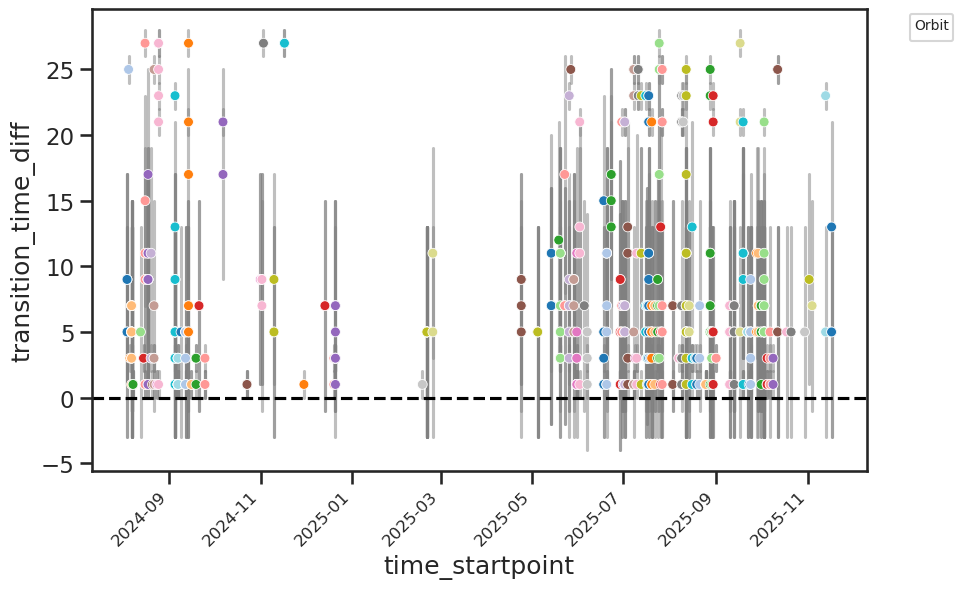

In [56]:
plt.figure(figsize=(10,6))
sns.scatterplot(data = bt_co_back_from_o, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=False, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_co_back_from_o.time_startpoint)):
    if not pd.isna(bt_co_back_from_o.transition_time_diff.values[i]):
        plt.plot([bt_co_back_from_o.time_startpoint.values[i], bt_co_back_from_o.time_startpoint.values[i]], 
                 [bt_co_back_from_o.transition_time_diff.values[i] - bt_co_back_from_o.transition_uncertainty.values[i],
                  bt_co_back_from_o.transition_time_diff.values[i] + bt_co_back_from_o.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5, zorder=0)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

/tmp/ipykernel_1048858/986066155.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)


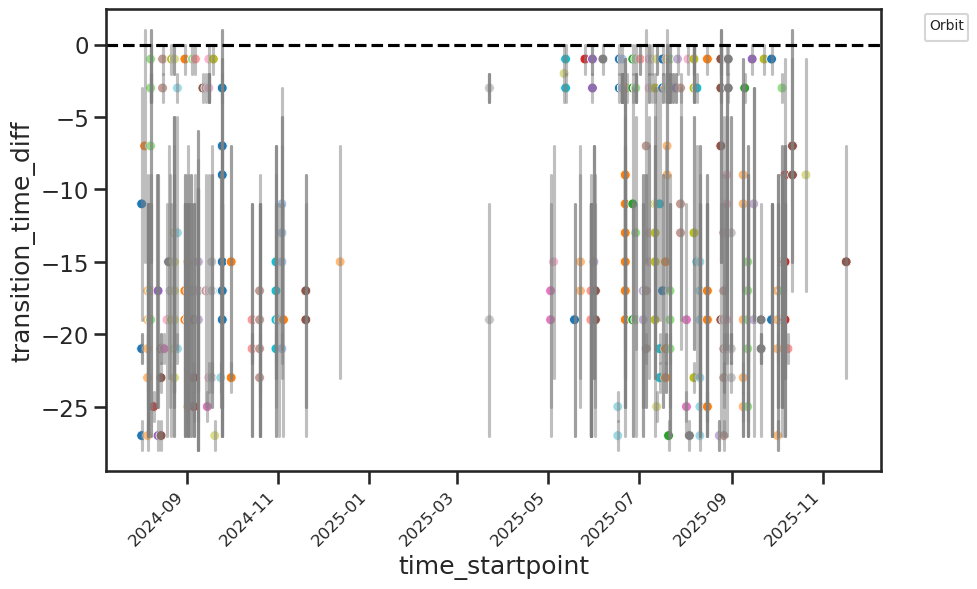

In [57]:
plt.figure(figsize=(10,6))
sns.scatterplot(data = bt_co_forward_from_c, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=False, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_co_forward_from_c.time_startpoint)):
    if not pd.isna(bt_co_forward_from_c.transition_time_diff.values[i]):
        plt.plot([bt_co_forward_from_c.time_startpoint.values[i], bt_co_forward_from_c.time_startpoint.values[i]], 
                 [bt_co_forward_from_c.transition_time_diff.values[i] - bt_co_forward_from_c.transition_uncertainty.values[i],
                  bt_co_forward_from_c.transition_time_diff.values[i] + bt_co_forward_from_c.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

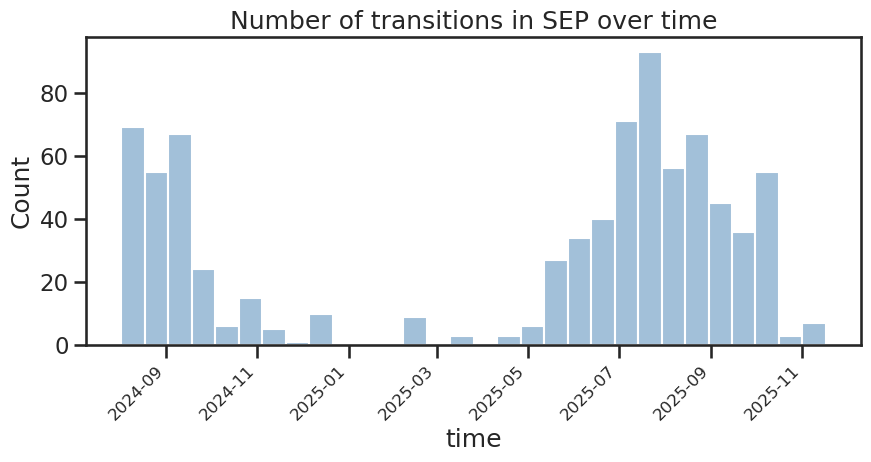

In [58]:
plt.figure(figsize=(10,4))
sns.histplot(data = bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True), x='time_startpoint', bins=30, color='steelblue', alpha=0.5)
plt.xticks(rotation=45, fontsize=12, ha='right')
plt.title('Number of transitions in SEP over time')
plt.xlabel('time')
plt.savefig('./figures/transition_count_over_time.png', bbox_inches='tight')

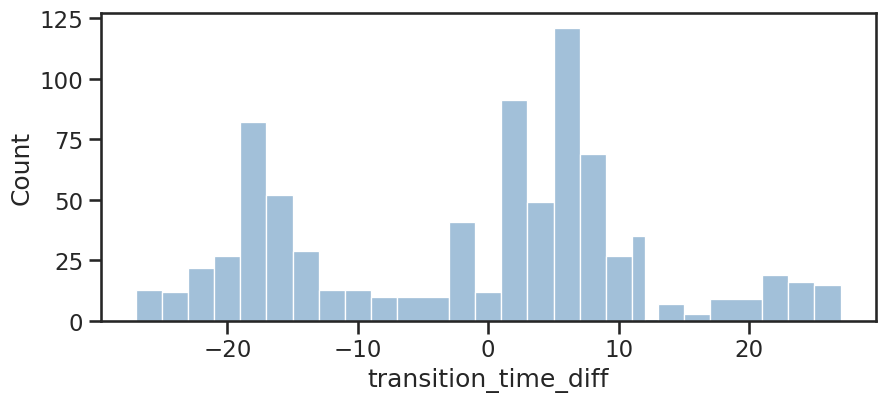

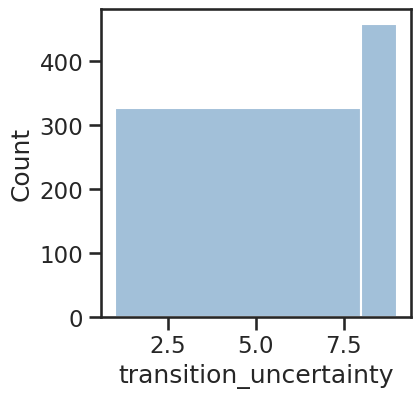

fraction of daytime transitions:  0.40396530359355637
transition_time_diff for daytime transitions:  [-27. -25. -23. -21.  -3.  -1.   1.   3.  21.  23.  25.  27.]
transition_time_diff for nighttime transitions:  [-19. -17. -15. -13. -11.  -9.  -7.   5.   7.   9.  11.  12.  13.  15.
  17.]


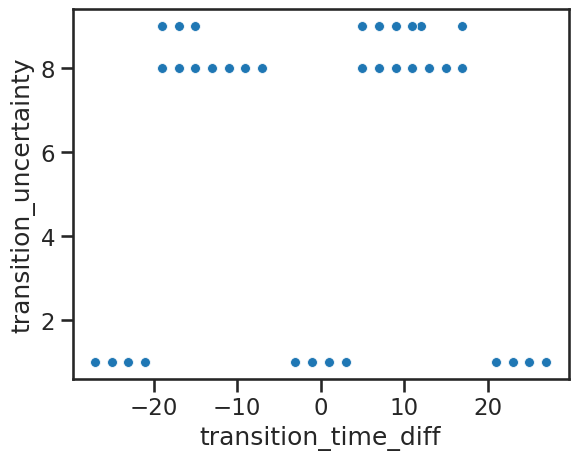

In [59]:
plt.figure(figsize=(10,4))
sns.histplot(data = bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True), x='transition_time_diff', 
             bins=np.unique(bt_co_concat.transition_time_diff), color='steelblue', alpha=0.5)
plt.show()
plt.figure(figsize=(4,4))
sns.histplot(data = bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True), x='transition_uncertainty', 
             bins=np.unique(bt_co_concat.transition_uncertainty), color='steelblue', alpha=0.5)
plt.show()
daytime_trans = (bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True)['transition_uncertainty'] < 3)
nighttime_trans = (bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True)['transition_uncertainty'] >= 3)
print("fraction of daytime transitions: ", (daytime_trans.sum() / (daytime_trans.sum() + nighttime_trans.sum())).values)


sns.scatterplot(data = bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True), x='transition_time_diff', y='transition_uncertainty', legend=False, s=50)
print('transition_time_diff for daytime transitions: ', np.unique(bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.transition_uncertainty < 3), drop=True)['transition_time_diff'].values))
print('transition_time_diff for nighttime transitions: ', np.unique(bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.transition_uncertainty > 3), drop=True)['transition_time_diff'].values))
plt.show()

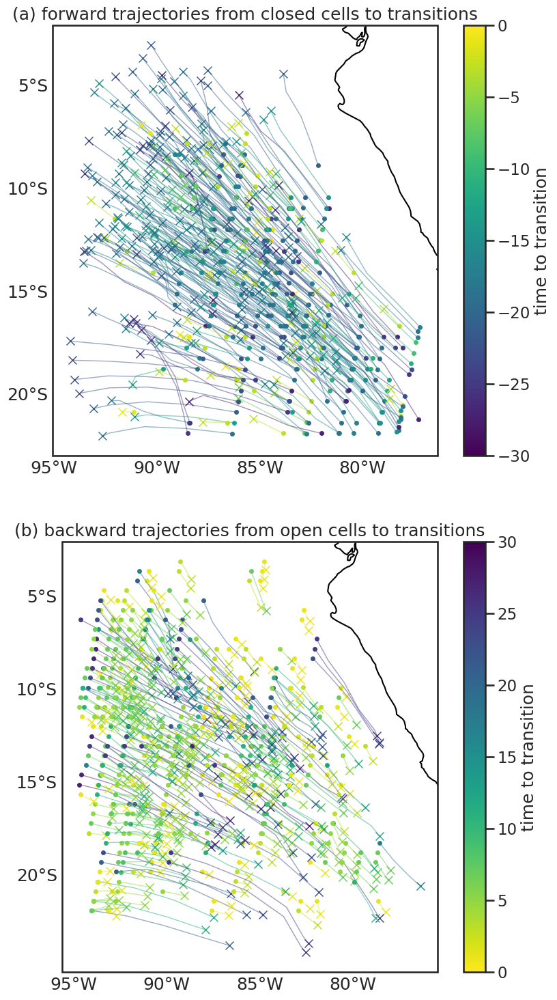

In [60]:
import matplotlib as mpl
import matplotlib.ticker as mticker
import cartopy.crs as ccrs

fig, (ax1,ax2) = plt.subplots(2,1, figsize=(10, 18), subplot_kw={'projection': ccrs.PlateCarree()})
for ax in [ax1, ax2]:
    ax.coastlines()
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlines = False
    gl.ylines = False
    gl.xlocator = mticker.FixedLocator([-95, -90, -85, -80, -75])
    gl.ylocator = mticker.FixedLocator([-25, -20, -15, -10, -5])

ax=ax1
bt_co_forward_from_c_with_trans = bt_co_concat.where((bt_co_concat.transition_flag==True) & (bt_co_concat.cats == 1), drop=True)
for startpoint in bt_co_forward_from_c_with_trans.time_startpoint.values:
    tmp = bt_co_forward_from_c_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(0,50)).sortby('timestep')
    #orbit = tmp.orbit_startpoint.values
    transition_timestep = tmp.transition_timestep.values
    tmp = tmp.sel(timestep=slice(0,transition_timestep+1))
    
    x_0 = tmp.sel(timestep=0).lon_traj.values.item()
    y_0 = tmp.sel(timestep=0).lat_traj.values.item()
    x_t = tmp.sel(timestep=transition_timestep).lon_traj.values.item()
    y_t = tmp.sel(timestep=transition_timestep).lat_traj.values.item()

    val = float(tmp.transition_time_diff.values) 
    norm = mpl.colors.Normalize(vmin=-30, vmax=0)
    cmap = plt.get_cmap("viridis")
    rgba = cmap(norm(val))

    sns.lineplot(ax=ax,x=tmp.lon_traj, y=tmp.lat_traj, color=rgba, alpha=0.5, lw=1)
    ax.plot(x_0, y_0, marker='o',  ms=4, lw=0, color=rgba)
    ax.plot(x_t, y_t, marker='x', ms=8, lw=0, color=rgba)
    
    # sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    # plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=4)
    #plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=7, color='black')
    #sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=50, marker='o')
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=ax, label="time to transition")
ax.set_title('(a) forward trajectories from closed cells to transitions')

ax=ax2
bt_co_back_from_o_with_trans = bt_co_concat.where((bt_co_concat.transition_flag==True) & (bt_co_concat.cats == 2), drop=True)
for startpoint in bt_co_back_from_o_with_trans.time_startpoint.values:
    tmp = bt_co_back_from_o_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(-50,1)).sortby('timestep')
    #orbit = tmp.orbit_startpoint.values
    transition_timestep = tmp.transition_timestep.values
    tmp = tmp.sel(timestep=slice(transition_timestep,0))

    x_0 = tmp.sel(timestep=0).lon_traj.values.item()
    y_0 = tmp.sel(timestep=0).lat_traj.values.item()
    x_t = tmp.sel(timestep=transition_timestep).lon_traj.values.item()
    y_t = tmp.sel(timestep=transition_timestep).lat_traj.values.item()

    val = float(tmp.transition_time_diff.values) 
    norm = mpl.colors.Normalize(vmin=0, vmax=30)
    cmap = plt.get_cmap("viridis_r")
    rgba = cmap(norm(val))

    sns.lineplot(ax=ax, x=tmp.lon_traj, y=tmp.lat_traj, color=rgba, alpha=0.5, lw=1)
    ax.plot(x_0, y_0, marker='o',  ms=4, lw=0, color=rgba)
    ax.plot(x_t, y_t, marker='x', ms=8, lw=0, color=rgba)
    
    #sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    #plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=4)
    #plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=7, color='black')
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=ax, label="time to transition")
ax.set_title('(b) backward trajectories from open cells to transitions')
plt.savefig('./figures/trajectories_of_transitions.png', bbox_inches='tight')

### CO transitions

#### ACMCAP variables as function of time-to-transition

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


(-30.0, 30.0)

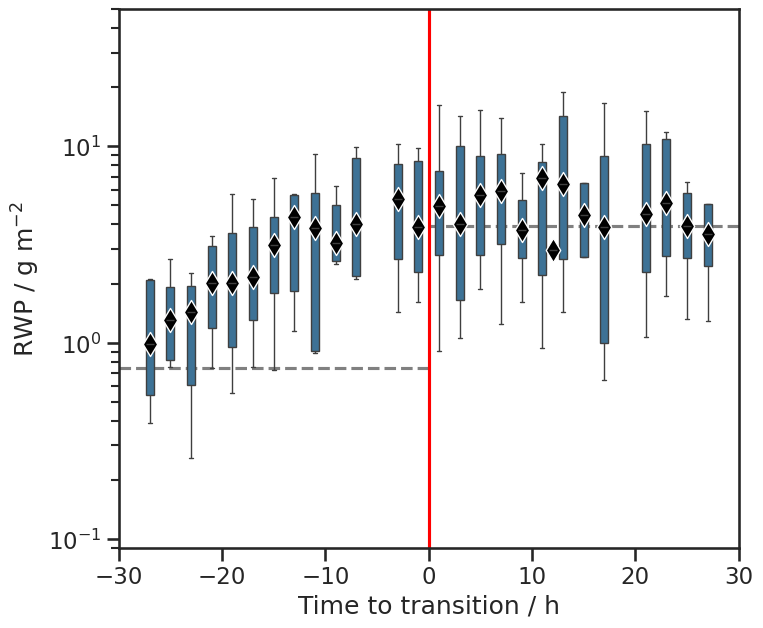

In [77]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

plt.figure(figsize=(8, 7))
plt.hlines(acmcap_climatology_median['rwp'].sel(cats=1)*1e3, xmin=-30, xmax=0, color='grey', linestyle='--')
plt.hlines(acmcap_climatology_median['rwp'].sel(cats=2)*1e3, xmin=0, xmax=30, color='grey', linestyle='--')
#plt.hlines(y=bt_non_trans_c['rwp'].median()*1e3, xmin=-30, xmax=0, color='orange', linestyle='-')
#plt.hlines(y=bt_non_trans_c['rwp'].quantile(0.25)*1e3, xmin=-30, xmax=0, color='orange', linestyle='-', alpha=0.5)
#plt.hlines(y=bt_non_trans_c['rwp'].quantile(0.75)*1e3, xmin=-30, xmax=0, color='orange', linestyle='-', alpha=0.5)

sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp']*1e3, whis=(10, 90), native_scale=True, showfliers=False, saturation=0.6)
tmp = bt_co_concat[['transition_time_diff', 'rwp']].groupby('transition_time_diff').median()
sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp['rwp']*1e3, color='black', marker='d', s=150, zorder=2)

plt.yscale('log')
plt.ylim(9e-2, 5e1)
#plt.ylim(0, 15)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')
plt.xlim(-30, 30)

<Axes: xlabel='transition_time_diff', ylabel='Count'>

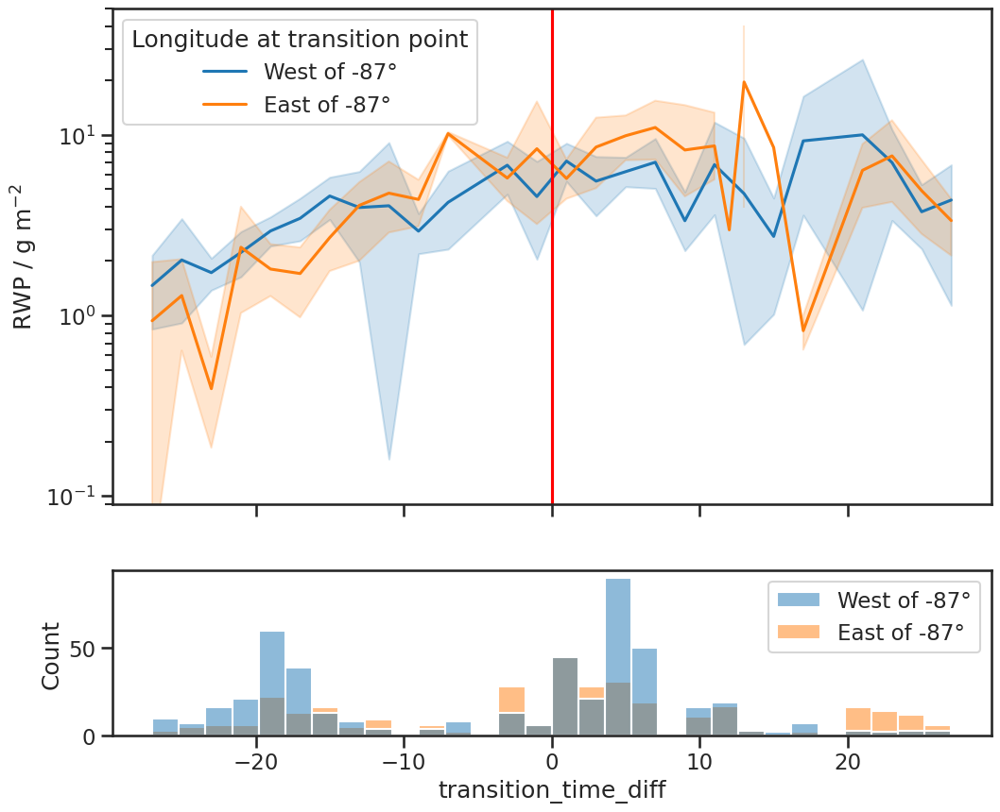

In [79]:
fig, (ax0, ax1) = plt.subplots(2,1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
tmp = bt_co_concat.where(bt_co_concat.transition_flag==1, drop=True)
lon_at_transition = (tmp.sel(timestep=tmp.transition_timestep).lon_traj < -87)
lon_at_transition = np.where(lon_at_transition.values==True, 'West of -87°', 'East of -87°')
sns.lineplot(ax=ax0, data = tmp, x='transition_time_diff', y=tmp['rwp']*1e3, hue=lon_at_transition)
ax0.set_yscale('log')
ax0.set_ylim(9e-2, 5e1)
ax0.legend(title='Longitude at transition point')
ax0.set_xlabel('Time to transition / h')
ax0.set_ylabel('RWP / g m$^{-2}$')
ax0.axvline(0, color='red', linestyle='-')

sns.histplot(ax=ax1, data = tmp, x='transition_time_diff', hue=lon_at_transition, bins=30, color='steelblue', alpha=0.5)

<Axes: xlabel='transition_time_diff', ylabel='Count'>

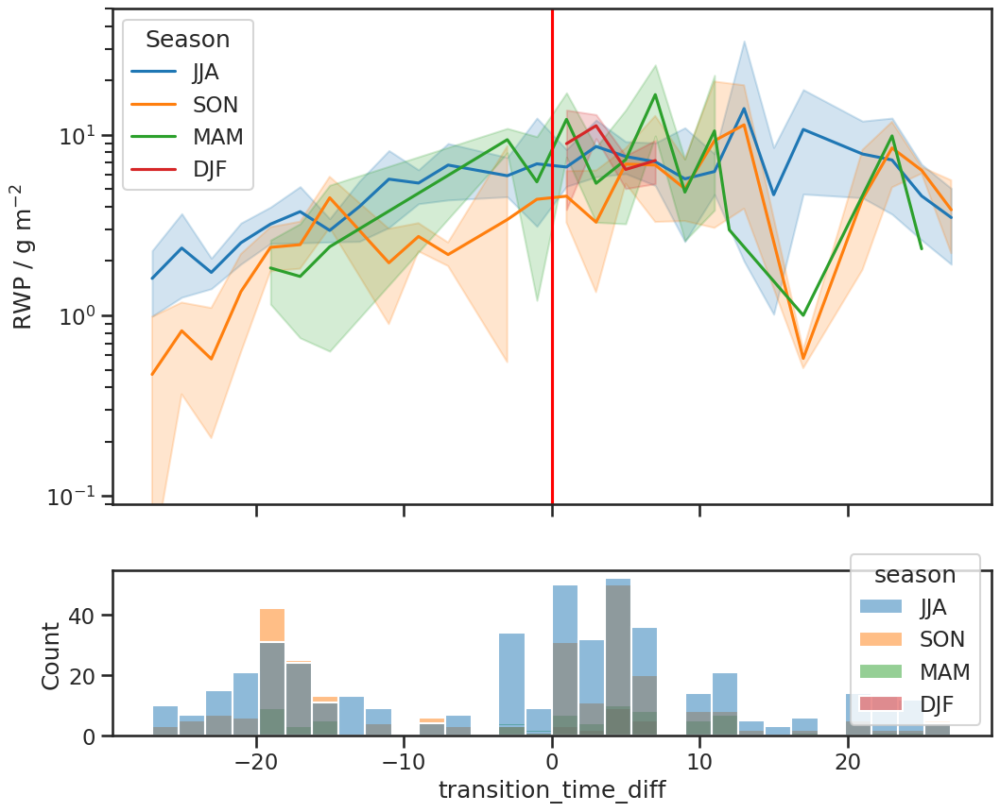

In [80]:
fig, (ax0, ax1) = plt.subplots(2,1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
tmp = bt_co_concat.where(bt_co_concat.transition_flag==1, drop=True)
tmp['season'] = tmp.time_startpoint.dt.season
sns.lineplot(ax=ax0, data = tmp, x='transition_time_diff', y=tmp['rwp']*1e3, hue='season')
ax0.set_yscale('log')
ax0.set_ylim(9e-2, 5e1)
ax0.legend(title='Season')
ax0.set_xlabel('Time to transition / h')
ax0.set_ylabel('RWP / g m$^{-2}$')
ax0.axvline(0, color='red', linestyle='-')

sns.histplot(ax=ax1, data = tmp, x='transition_time_diff', hue='season', bins=30, color='steelblue', alpha=0.5)

<Axes: xlabel='transition_time_diff', ylabel='Count'>

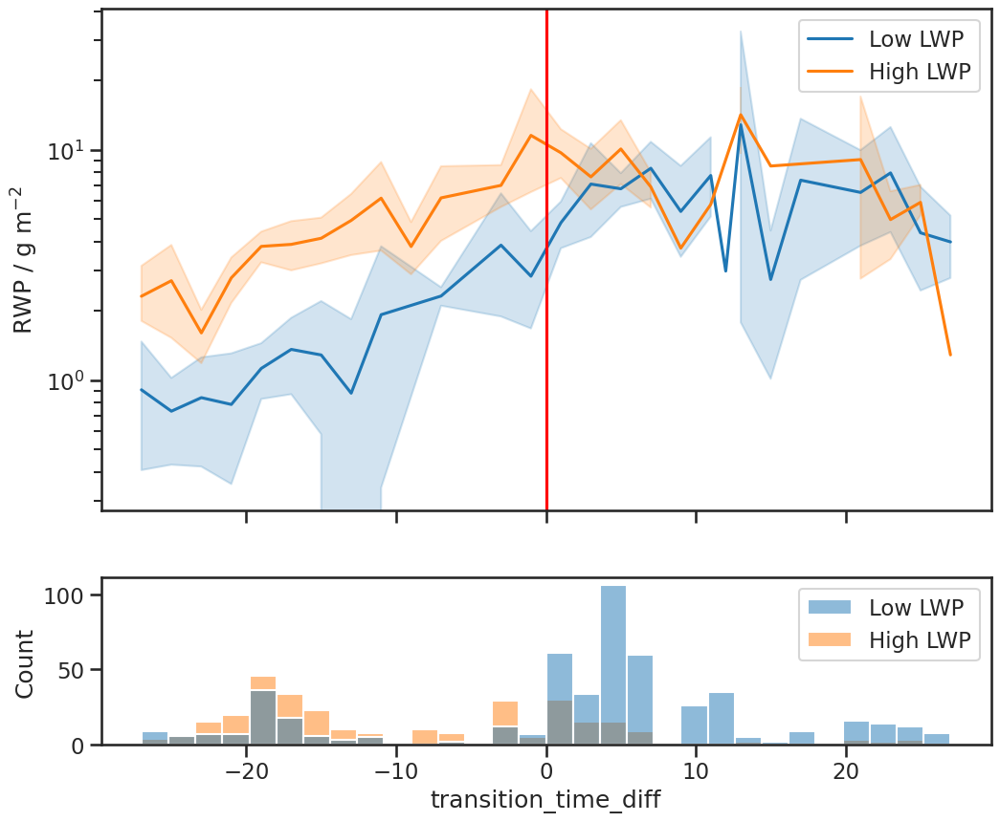

In [81]:
fig, (ax0, ax1) = plt.subplots(2,1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
lwp_bins = (bt_co_concat.lwp > 5e-2)
lwp_bins = np.where(lwp_bins.values==True, 'High LWP', 'Low LWP')
sns.lineplot(ax=ax0, data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp']*1e3, hue=lwp_bins)
ax0.set_yscale('log')
#ax0.legend(title='LWP category')
ax0.set_xlabel('Time to transition / h')
ax0.set_ylabel('RWP / g m$^{-2}$')
ax0.axvline(0, color='red', linestyle='-')

sns.histplot(ax=ax1, data = bt_co_concat, x='transition_time_diff', hue=lwp_bins, bins=30, color='steelblue', alpha=0.5)

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2544272/3106481172.py:4: SyntaxWarning: invalid escape sequence '\m'
  'ER': {'factor':1e6, 'y_label': 'ER / $\mu$m', 'y_lim': (4, 12), 'y_scale': 'linear'},
/tmp/ipykernel_2544272/3106481172.py:6: SyntaxWarning: invalid escape sequence '\m'
  'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'RVD / $\mu$m', 'y_lim': (6e1, 1.8e2), 'y_scale': 'linear'},
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


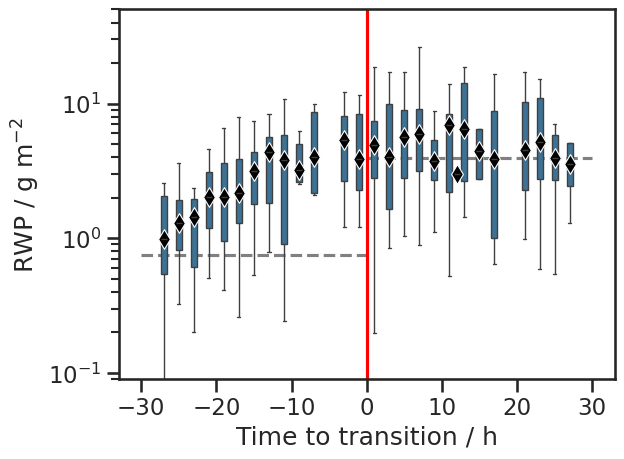

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


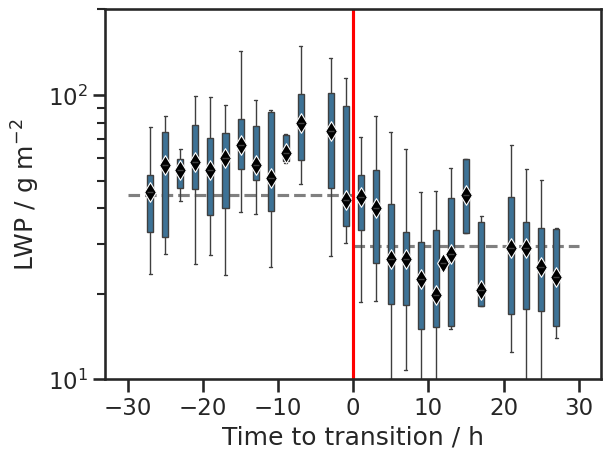

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


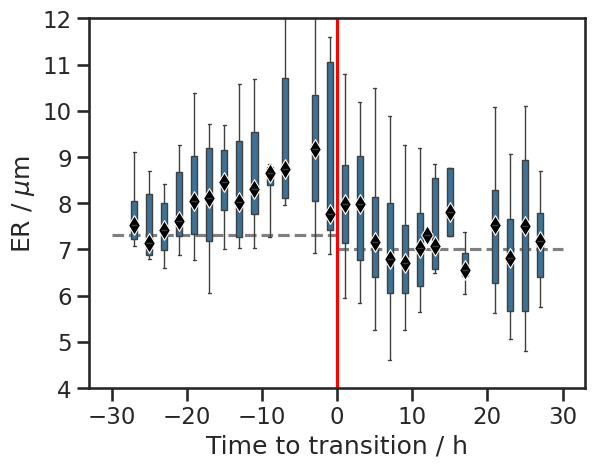

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


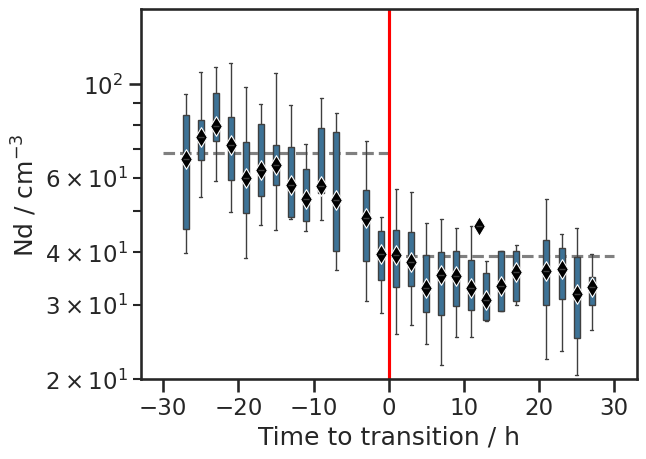

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


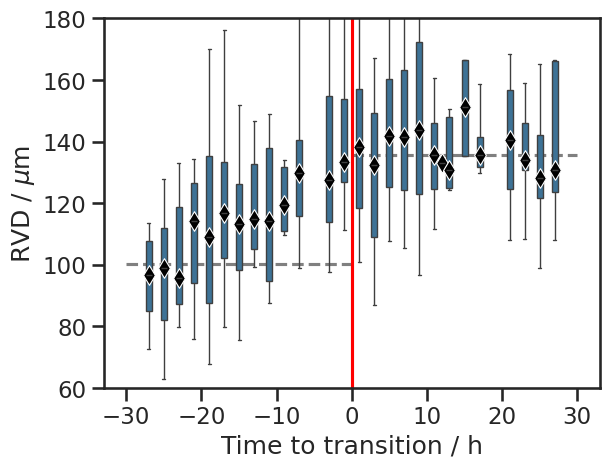

In [82]:
plot_params = {
    'rwp': {'factor': 1e3, 'y_label': 'RWP / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'lwp': {'factor': 1e3, 'y_label': 'LWP / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'ER': {'factor':1e6, 'y_label': 'ER / $\mu$m', 'y_lim': (4, 12), 'y_scale': 'linear'},
    'Nd': {'factor': 1e-6, 'y_label': 'Nd / cm$^{-3}$', 'y_lim': (2e1, 1.5e2), 'y_scale': 'log'},
    'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'RVD / $\mu$m', 'y_lim': (6e1, 1.8e2), 'y_scale': 'linear'},
}

for var, params in plot_params.items():
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')
    plt.show()


/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

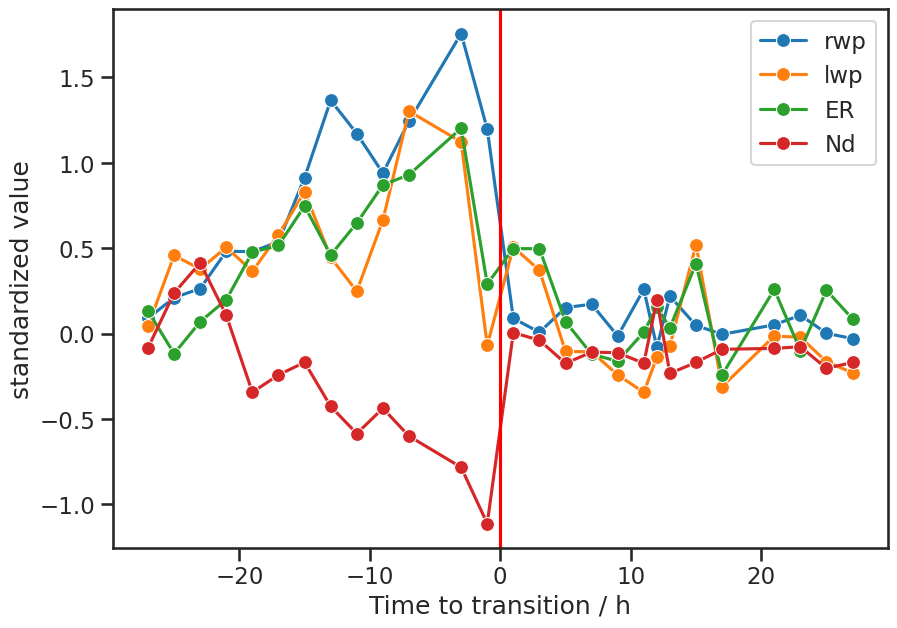

In [117]:
vars = ['rwp', 'lwp', 'ER', 'Nd']


plt.figure(figsize=(10, 7))
for var in vars:
    tmp_1 = bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.cats == 1), drop=True)[['transition_time_diff', var]]
    tmp_2 = bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.cats == 2), drop=True)[['transition_time_diff', var]]
    rwp_1_standardized = (tmp_1[var] - acmcap_climatology_median[var].sel(cats=1)) / acmcap_climatology_std[var].sel(cats=1)
    rwp_2_standardized = (tmp_2[var] - acmcap_climatology_median[var].sel(cats=2)) / acmcap_climatology_std[var].sel(cats=2)
    tmp_1[var + '_standardized'] = rwp_1_standardized.drop_vars('cats') 
    tmp_2[var + '_standardized'] = rwp_2_standardized.drop_vars('cats')
    tmp = xr.concat([tmp_1, tmp_2], dim='time_startpoint')

    #sns.boxplot(x= tmp['transition_time_diff'], y=tmp[var + '_standardized'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp_median = tmp.groupby('transition_time_diff').median()
    sns.lineplot(data=tmp_median, x='transition_time_diff', y=tmp_median[var + '_standardized'], marker='o', markersize=10, label=var)

plt.xlabel('Time to transition / h')
plt.ylabel('standardized value')
plt.axvline(0, color='red', linestyle='-')
plt.legend()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

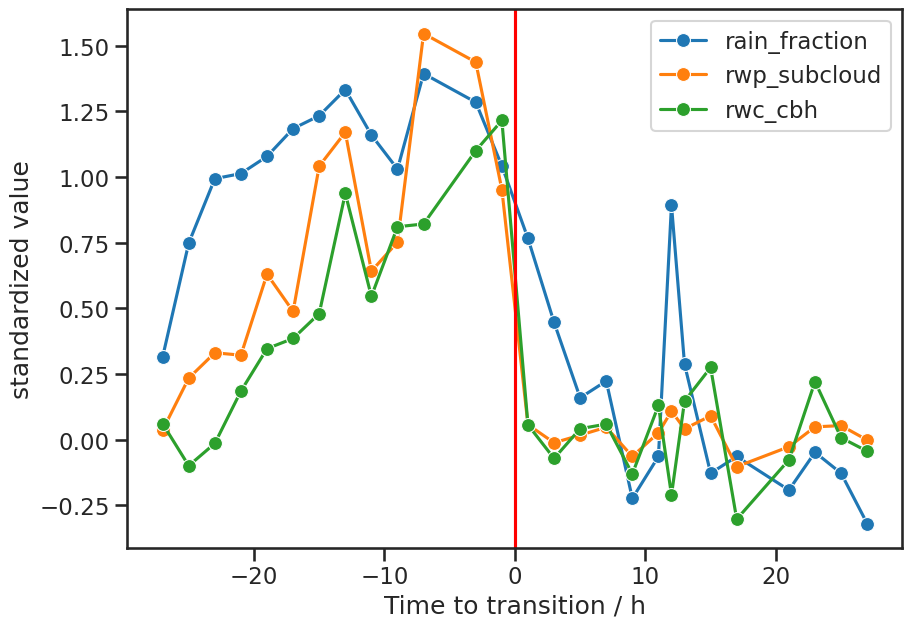

In [84]:
vars = ['rain_fraction', 'rwp_subcloud', 'rwc_cbh'] # 'rain_median_volume_diameter',

plt.figure(figsize=(10, 7))
for var in vars:
    tmp_1 = bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.cats == 1), drop=True)[['transition_time_diff', var]]
    tmp_2 = bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.cats == 2), drop=True)[['transition_time_diff', var]]
    rwp_1_standardized = (tmp_1[var] - acmcap_climatology_median[var].sel(cats=1)) / acmcap_climatology_std[var].sel(cats=1)
    rwp_2_standardized = (tmp_2[var] - acmcap_climatology_median[var].sel(cats=2)) / acmcap_climatology_std[var].sel(cats=2)
    tmp_1[var + '_standardized'] = rwp_1_standardized.drop_vars('cats') 
    tmp_2[var + '_standardized'] = rwp_2_standardized.drop_vars('cats')
    tmp = xr.concat([tmp_1, tmp_2], dim='time_startpoint')

    #sns.boxplot(x= tmp['transition_time_diff'], y=tmp[var + '_standardized'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp_median = tmp.groupby('transition_time_diff').median()
    sns.lineplot(data=tmp_median, x='transition_time_diff', y=tmp_median[var + '_standardized'], marker='o', markersize=10, label=var)

plt.xlabel('Time to transition / h')
plt.ylabel('standardized value')
plt.axvline(0, color='red', linestyle='-')
plt.legend()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


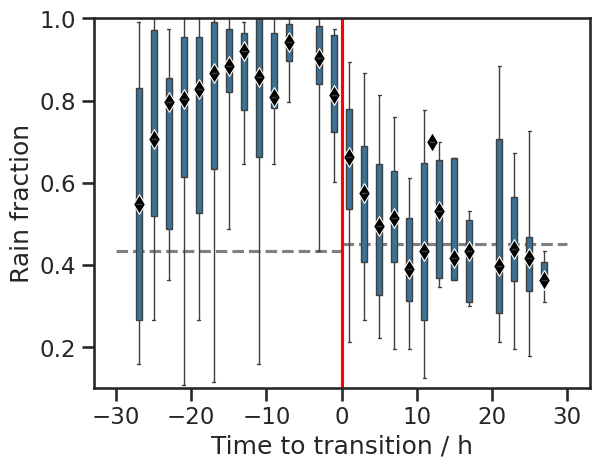

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


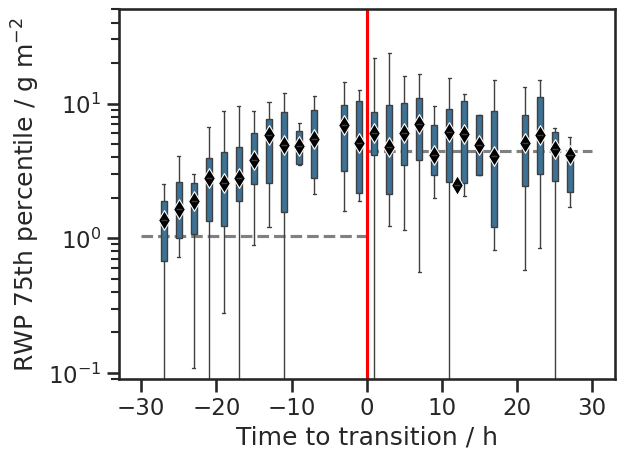

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


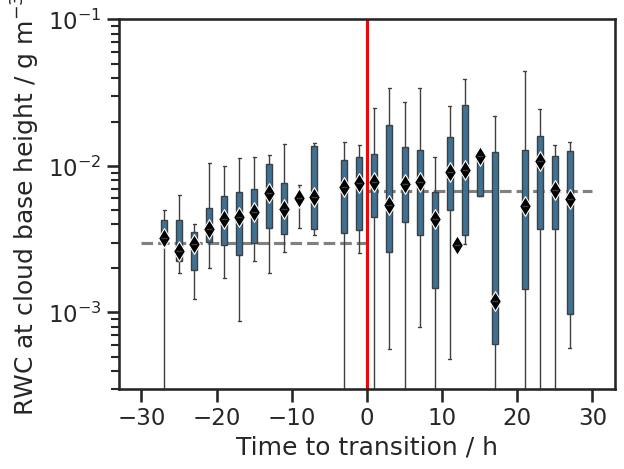

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


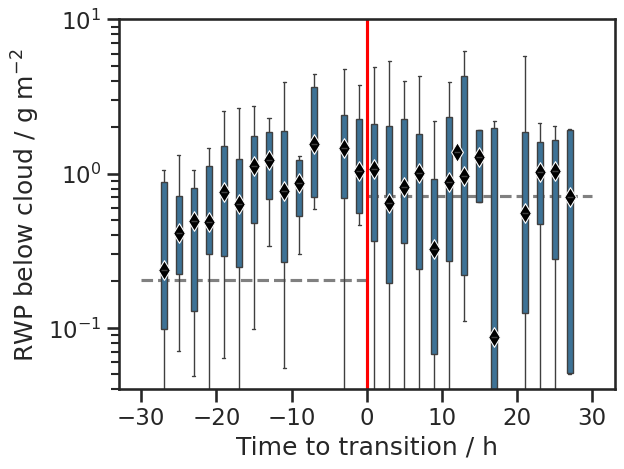

In [85]:
plot_params = {
    'rain_fraction': {'factor': 1, 'y_label': 'Rain fraction', 'y_lim': (0.1,1), 'y_scale': 'linear'},
    'rwp_perc75': {'factor': 1e3, 'y_label': 'RWP 75th percentile / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rwc_cbh': {'factor': 1e3, 'y_label': 'RWC at cloud base height / g m$^{-3}$', 'y_lim': (3e-4, 1e-1), 'y_scale': 'log'},
    'rwp_subcloud': {'factor': 1e3, 'y_label': 'RWP below cloud / g m$^{-2}$', 'y_lim': (4e-2, 1e1), 'y_scale': 'log'},
}

for var, params in plot_params.items():
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')
    plt.show()

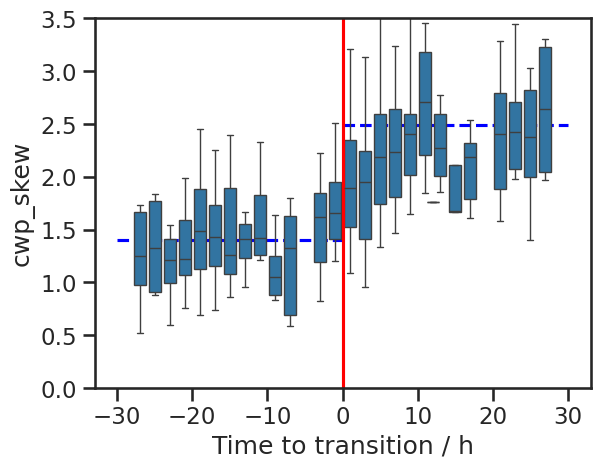

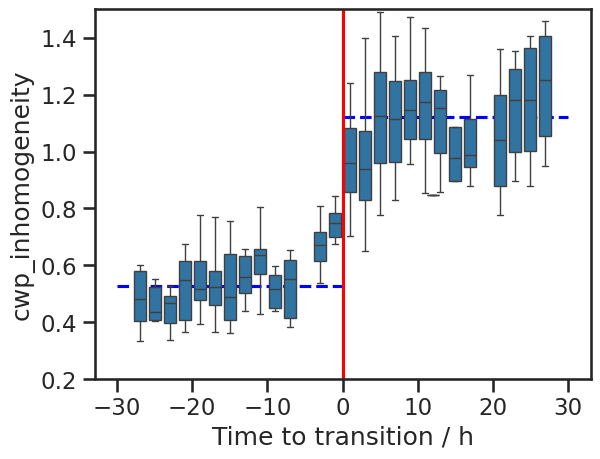

In [87]:
var = 'cwp_skew'
ylim = (0, 3.5)
yscale = 'linear'
plt.hlines(acmcap_climatology_median[var].sel(cats=1), xmin=-30, xmax=0, color='blue', linestyle='--')
plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=0, xmax=30, color='blue', linestyle='--')
#plt.hlines(y=bt_non_trans_c[var].median(), xmin=-30, xmax=0, color='blue', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=3, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.yscale(yscale)
plt.ylim(ylim)
plt.xlabel('Time to transition / h')
plt.show()

var = 'cwp_inhomogeneity'
ylim = (0.2, 1.5)
yscale = 'linear'
plt.hlines(acmcap_climatology_median[var].sel(cats=1), xmin=-30, xmax=0, color='blue', linestyle='--')
plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=0, xmax=30, color='blue', linestyle='--')
#plt.hlines(y=bt_non_trans_c[var].median(), xmin=-30, xmax=0, color='blue', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=3, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.yscale(yscale)
plt.ylim(ylim)
plt.xlabel('Time to transition / h')
plt.show()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


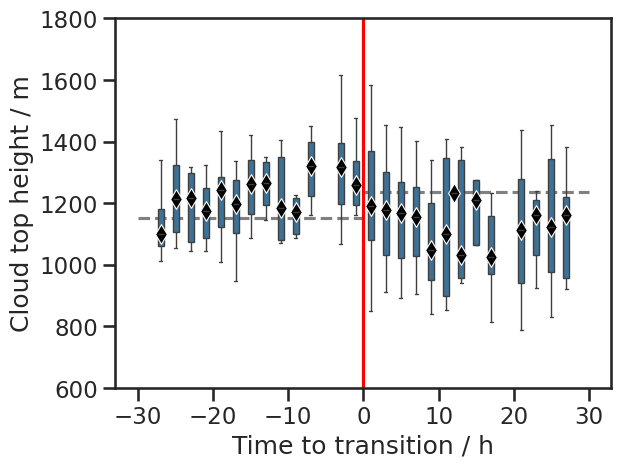

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


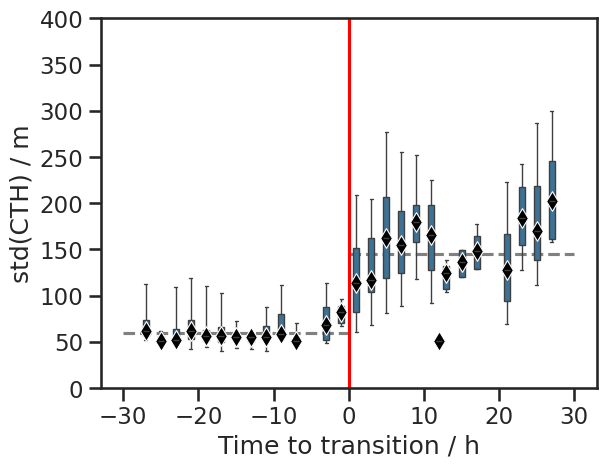

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


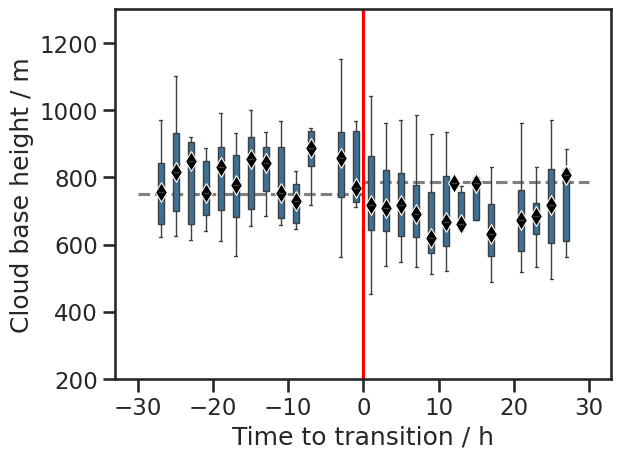

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


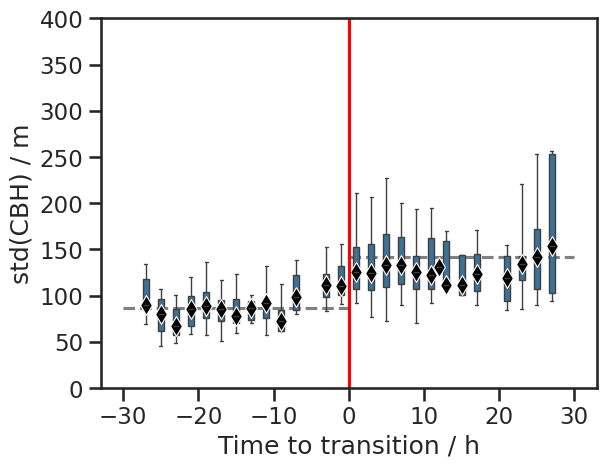

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


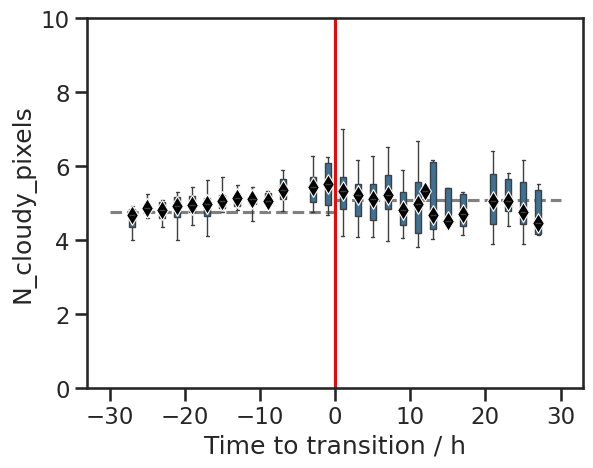

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


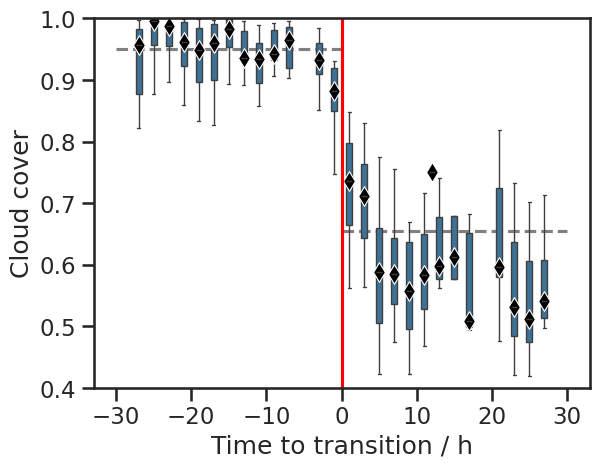

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


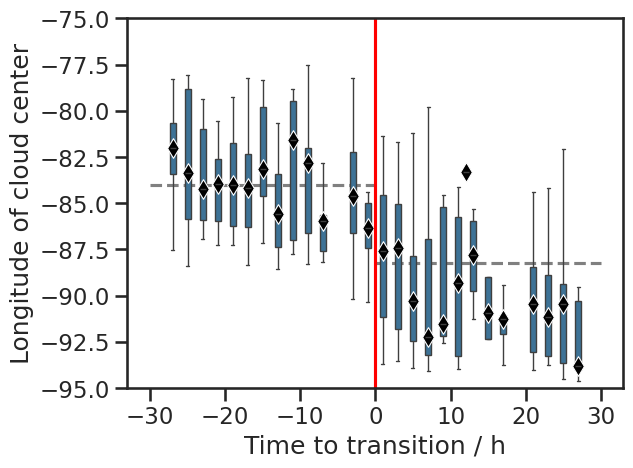

In [88]:
plot_params = {
    'cth_m': {'factor': 1, 'y_label': 'Cloud top height / m', 'y_lim': (600, 1800), 'y_scale': 'linear'},
    'cth_m_std': {'factor': 1e0, 'y_label': 'std(CTH) / m', 'y_lim': (0, 400), 'y_scale': 'linear'},
    'cbh_m': {'factor': 1e0, 'y_label': 'Cloud base height / m', 'y_lim': (200, 1300), 'y_scale': 'linear'},
    'cbh_m_std': {'factor': 1e0, 'y_label': 'std(CBH) / m', 'y_lim': (0, 400), 'y_scale': 'linear'},
    'N_cloudy_pixels': {'factor': 1, 'y_label': 'N_cloudy_pixels', 'y_lim': (0, 10), 'y_scale': 'linear'},
    'cloud_cover': {'factor': 1, 'y_label': 'Cloud cover', 'y_lim': (0.4, 1), 'y_scale': 'linear'},
    'lon_mid': {'factor': 1, 'y_label': 'Longitude of cloud center', 'y_lim': (-95, -75), 'y_scale': 'linear'},
}

for var, params in plot_params.items():
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')
    plt.show()

##### overview plot for publication

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

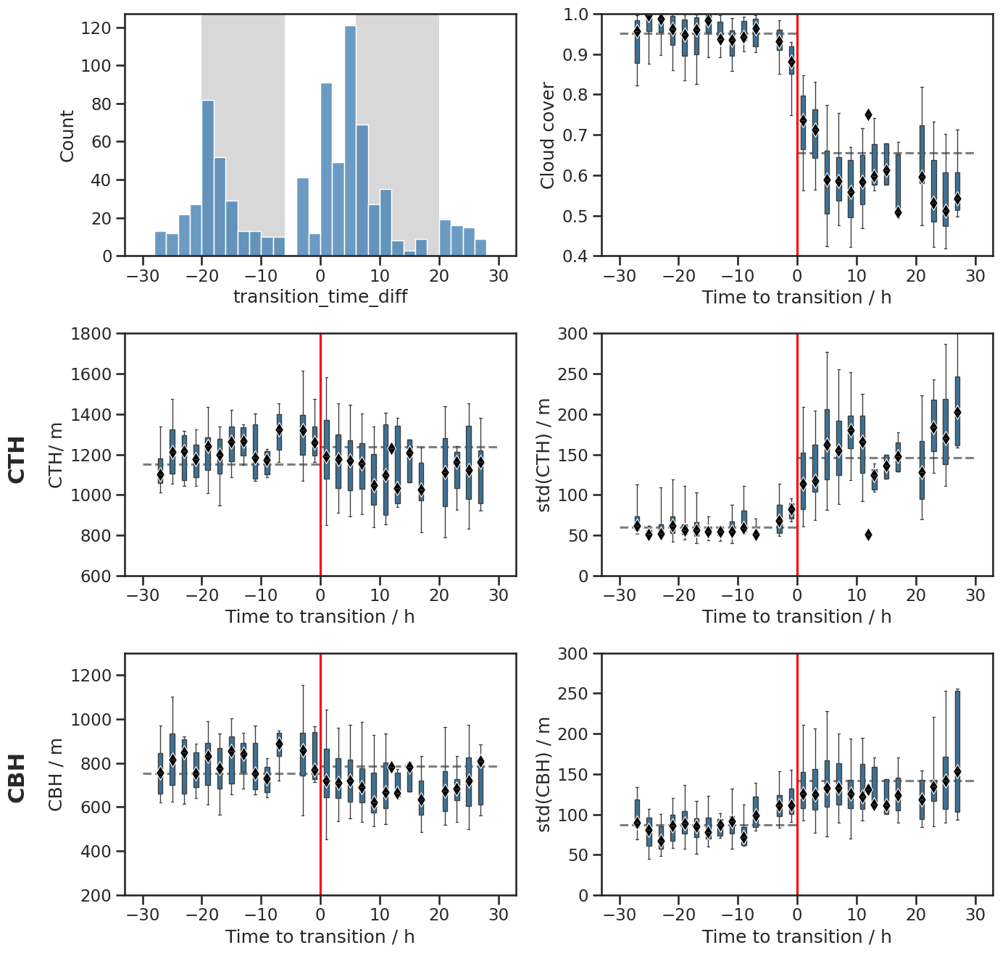

In [ ]:
plot_params = {
    'no_plot': {},
    'cloud_cover': {'factor': 1, 'y_label': 'Cloud cover', 'y_lim': (0.4, 1), 'y_scale': 'linear'},
    'cth_m': {'factor': 1, 'y_label': 'CTH/ m', 'y_lim': (600, 1800), 'y_scale': 'linear'},
    'cth_m_std': {'factor': 1e0, 'y_label': 'std(CTH) / m', 'y_lim': (0, 300), 'y_scale': 'linear'},
    'cbh_m': {'factor': 1e0, 'y_label': 'CBH / m', 'y_lim': (200, 1300), 'y_scale': 'linear'},
    'cbh_m_std': {'factor': 1e0, 'y_label': 'std(CBH) / m', 'y_lim': (0, 300), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 3
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

# add grey background for nighttime periods
axs[0].axvspan(-20, -6, color='grey', alpha=0.3, lw=0)
axs[0].axvspan(6, 20, color='grey', alpha=0.3, lw=0)
sns.histplot(ax=axs[0], data = bt_co_concat, x='transition_time_diff', bins=np.linspace(-30, 30, 31), color='steelblue', alpha=0.8)
plt.xlabel('Time to transition / h')

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

#axs[2].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
#axs[3].annotate('std', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['','CTH','CBH']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

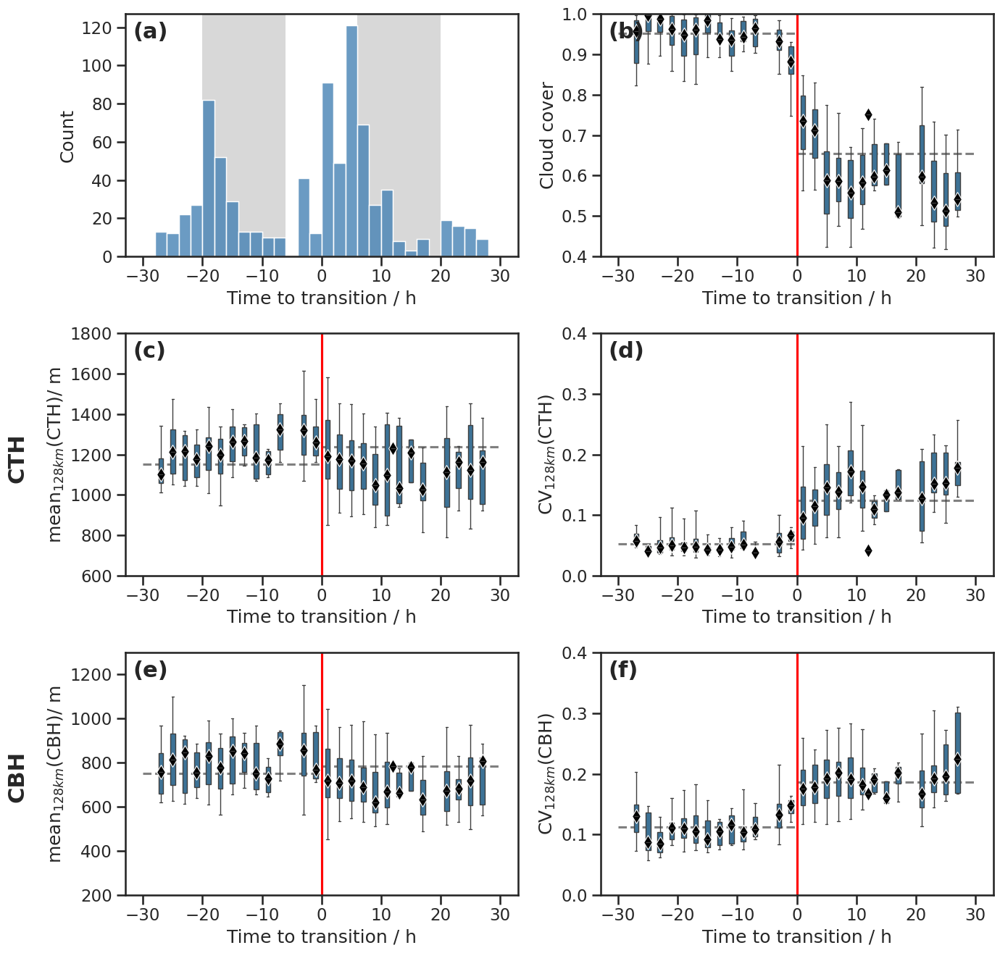

In [45]:
plot_params = {
    'no_plot': {},
    'cloud_cover': {'factor': 1, 'y_label': 'Cloud cover', 'y_lim': (0.4, 1), 'y_scale': 'linear'},
    'cth_m': {'factor': 1, 'y_label': 'mean$_{128km}$(CTH)/ m', 'y_lim': (600, 1800), 'y_scale': 'linear'},
    'cth_m_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(CTH)', 'y_lim': (0, 0.4), 'y_scale': 'linear'},
    'cbh_m': {'factor': 1, 'y_label': 'mean$_{128km}$(CBH)/ m', 'y_lim': (200, 1300), 'y_scale': 'linear'},
    'cbh_m_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(CBH)', 'y_lim': (0, 0.4), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 3
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

# add grey background for nighttime periods
axs[0].axvspan(-20, -6, color='grey', alpha=0.3, lw=0)
axs[0].axvspan(6, 20, color='grey', alpha=0.3, lw=0)
sns.histplot(ax=axs[0], data = bt_co_concat, x='transition_time_diff', bins=np.linspace(-30, 30, 31), color='steelblue', alpha=0.8)
axs[0].set_xlabel('Time to transition / h')

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

#axs[2].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
#axs[3].annotate('std', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[0].annotate('(a)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('(b)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[2].annotate('(c)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[3].annotate('(d)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[4].annotate('(e)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[5].annotate('(f)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['','CTH','CBH']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()

plt.savefig('./figures/cbh_cth_vs_time.png', bbox_inches='tight')

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2544272/1372724020.py:4: SyntaxWarning: invalid escape sequence '\m'
  'ER': {'factor':1e6, 'y_label': 'mean$_{128km}$(DER) / $\mu$m', 'y_lim': (4, 12), 'y_scale': 'linear'},
/tmp/ipykernel_2544272/1372724020.py:10: SyntaxWarning: invalid escape sequence '\m'
  'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'mean$_{128km}$(RVD) / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linear'},
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_d

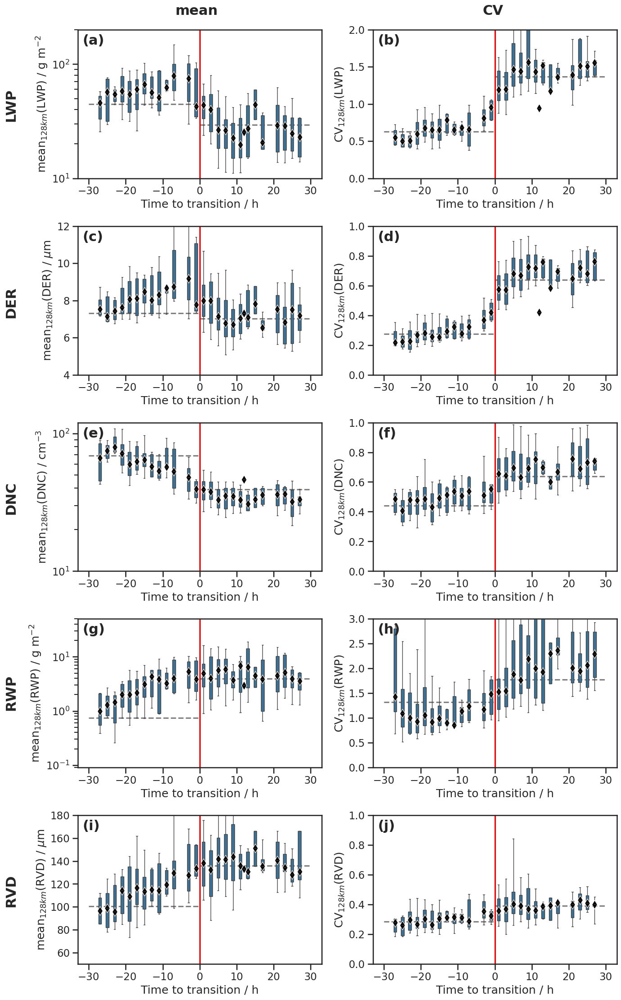

In [27]:
plot_params = {
    'lwp': {'factor': 1e3, 'y_label': 'mean$_{128km}$(LWP) / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'lwp_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(LWP)', 'y_lim': (0, 2), 'y_scale': 'linear'},
    'ER': {'factor':1e6, 'y_label': 'mean$_{128km}$(DER) / $\mu$m', 'y_lim': (4, 12), 'y_scale': 'linear'},
    'ER_cv': {'factor':1, 'y_label': 'CV$_{128km}$(DER)', 'y_lim': (0, 1), 'y_scale': 'linear'},
    'Nd': {'factor': 1e-6, 'y_label': 'mean$_{128km}$(DNC) / cm$^{-3}$', 'y_lim': (1e1, 1.2e2), 'y_scale': 'log'},
    'Nd_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(DNC)', 'y_lim': (0, 1), 'y_scale': 'linear'},
    'rwp': {'factor': 1e3, 'y_label': 'mean$_{128km}$(RWP) / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rwp_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(RWP)', 'y_lim': (0, 3), 'y_scale': 'linear'},
    'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'mean$_{128km}$(RVD) / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linear'},
    'rain_median_volume_diameter_cv': {'factor':1, 'y_label': 'CV$_{128km}$(RVD)', 'y_lim': (0, 1), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 5
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        axs[i].axis('off')
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(10, 90), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

axs[0].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('CV', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['(a)','(b)','(c)','(d)','(e)','(f)','(g)','(h)','(i)','(j)']):
    axs[idx].annotate(text, xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')

for idx, text in enumerate(['LWP','DER','DNC','RWP','RVD']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()
plt.savefig('./figures/microphysics_vs_time.png', bbox_inches='tight')

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1048858/1127203196.py:4: SyntaxWarning: invalid escape sequence '\m'
  'ER': {'factor':1e6, 'y_label': 'mean$_{128km}$(ER) / $\mu$m', 'y_lim': (3, 12), 'y_scale': 'linear'},
/tmp/ipykernel_1048858/1127203196.py:5: SyntaxWarning: invalid escape sequence '\m'
  'ER_std': {'factor':1e6, 'y_label': 'std$_{128km}$(ER) / $\mu$m', 'y_lim': (0, 8), 'y_scale': 'linear'},
/tmp/ipykernel_1048858/1127203196.py:10: SyntaxWarning: invalid escape sequence '\m'
  'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'mean$_{128km}$(RVD) / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linea

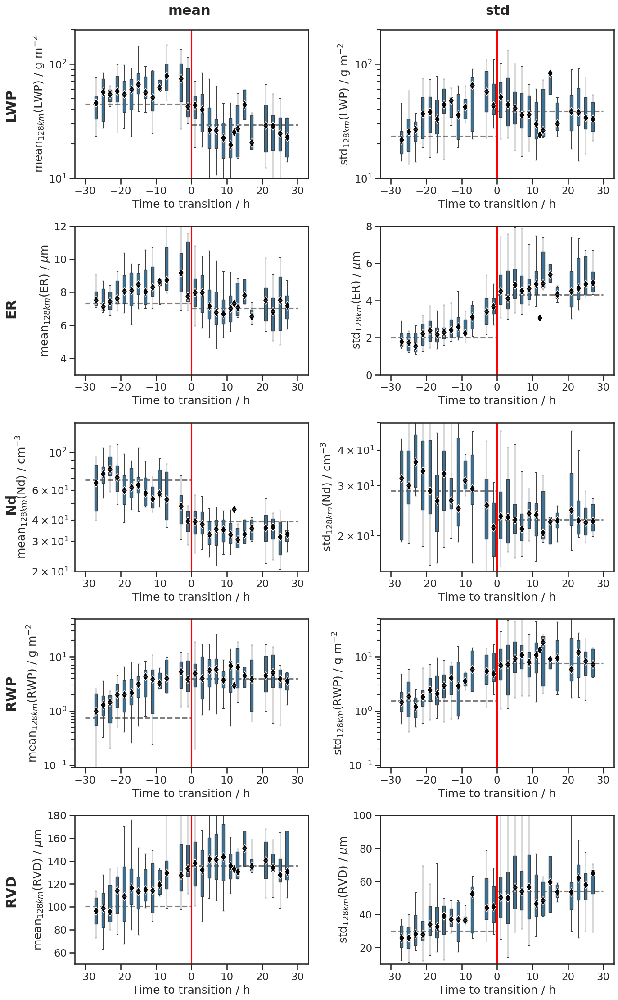

In [ ]:
plot_params = {
    'lwp': {'factor': 1e3, 'y_label': 'mean$_{128km}$(LWP) / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'lwp_std': {'factor': 1e3, 'y_label': 'std$_{128km}$(LWP) / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'ER': {'factor':1e6, 'y_label': 'mean$_{128km}$(ER) / $\mu$m', 'y_lim': (3, 12), 'y_scale': 'linear'},
    'ER_std': {'factor':1e6, 'y_label': 'std$_{128km}$(ER) / $\mu$m', 'y_lim': (0, 8), 'y_scale': 'linear'},
    'Nd': {'factor': 1e-6, 'y_label': 'mean$_{128km}$(Nd) / cm$^{-3}$', 'y_lim': (2e1, 1.5e2), 'y_scale': 'log'},
    'Nd_std': {'factor': 1e-6, 'y_label': 'std$_{128km}$(Nd) / cm$^{-3}$', 'y_lim': (1.5e1, 5e1), 'y_scale': 'log'},
    'rwp': {'factor': 1e3, 'y_label': 'mean$_{128km}$(RWP) / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rwp_std': {'factor': 1e3, 'y_label': 'std$_{128km}$(RWP) / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'mean$_{128km}$(RVD) / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linear'},
    'rain_median_volume_diameter_std': {'factor':1e6, 'y_label': 'std$_{128km}$(RVD) / $\mu$m', 'y_lim': (1e1, 1e2), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 5
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        axs[i].axis('off')
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

axs[0].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('std', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['LWP','ER','Nd','RWP','RVD']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()
#plt.savefig('./figures/microphysics_vs_time.png', bbox_inches='tight')

<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_368554/3503352503.py:3: SyntaxWarning: invalid escape sequence '\m'
  'ER': {'factor':1e6, 'y_label': 'ER / $\mu$m', 'y_lim': (3, 12), 'y_scale': 'linear'},
/tmp/ipykernel_368554/3503352503.py:6: SyntaxWarning: invalid escape sequence '\m'
  'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'RVD / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linear'},
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jma

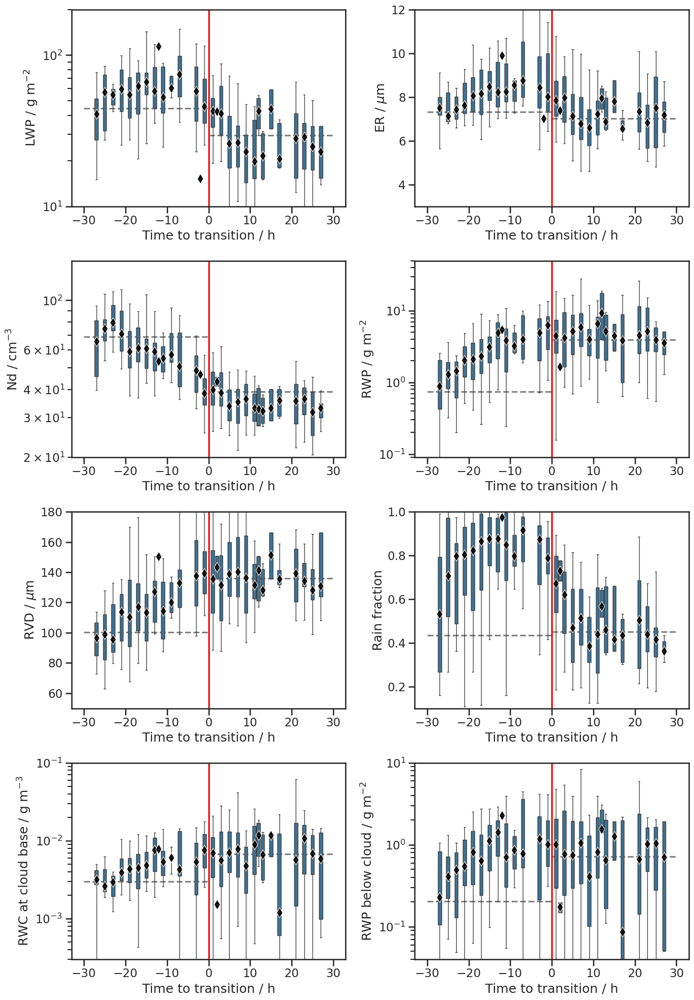

In [160]:
plot_params = {
    'lwp': {'factor': 1e3, 'y_label': 'LWP / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'ER': {'factor':1e6, 'y_label': 'ER / $\mu$m', 'y_lim': (3, 12), 'y_scale': 'linear'},
    'Nd': {'factor': 1e-6, 'y_label': 'Nd / cm$^{-3}$', 'y_lim': (2e1, 1.5e2), 'y_scale': 'log'},
    'rwp': {'factor': 1e3, 'y_label': 'RWP / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'RVD / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linear'},
    'rain_fraction': {'factor': 1, 'y_label': 'Rain fraction', 'y_lim': (0.1,1), 'y_scale': 'linear'},
    'rwc_cbh': {'factor': 1e3, 'y_label': 'RWC at cloud base / g m$^{-3}$', 'y_lim': (3e-4, 1e-1), 'y_scale': 'log'},
    'rwp_subcloud': {'factor': 1e3, 'y_label': 'RWP below cloud / g m$^{-2}$', 'y_lim': (4e-2, 1e1), 'y_scale': 'log'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 4
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*5))
axs = axs.flatten()

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        axs[i].axis('off')
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

    #ax2 = axs[i].twinx()
    #tmp = bt_co_concat[['transition_time_diff', var+'_std']].groupby('transition_time_diff').median()
    #sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var+'_std']*params['factor'], marker='o', color='green', s=40, linewidth=0, zorder=0, ax=axs[i])
    #plt.ylim(params['y_lim'])
    #plt.yscale(params['y_scale'])
    #plt.xlabel('Time to transition / h')
    #plt.ylabel('std(' + params['y_label'] + ')')
    #plt.axvline(0, color='red', linestyle='-')


fig.tight_layout()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

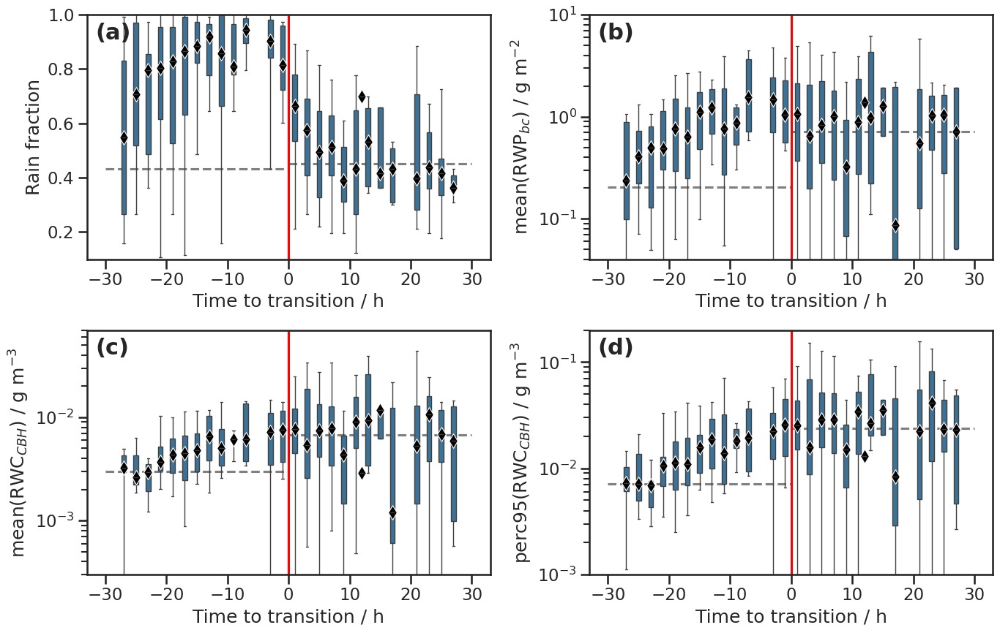

In [55]:
plot_params = {
    'rain_fraction': {'factor': 1, 'y_label': 'Rain fraction', 'y_lim': (0.1,1), 'y_scale': 'linear'},
    'rwp_subcloud': {'factor': 1e3, 'y_label': 'mean(RWP$_{bc}$) / g m$^{-2}$', 'y_lim': (4e-2, 1e1), 'y_scale': 'log'},
    'rwc_cbh': {'factor': 1e3, 'y_label': 'mean(RWC$_{CBH}$) / g m$^{-3}$', 'y_lim': (3e-4, 7e-2), 'y_scale': 'log'},
    'rwc_cbh_perc95': {'factor': 1e3, 'y_label': 'perc95(RWC$_{CBH}$) / g m$^{-3}$', 'y_lim': (1e-3, 2e-1), 'y_scale': 'log'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 2
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        axs[i].axis('off')
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

for idx, text in enumerate(['(a)','(b)','(c)','(d)']):
    axs[idx].annotate(text, xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')

fig.tight_layout()
plt.savefig('./figures/rain_details_vs_time.png', bbox_inches='tight')

#### compare CO clouds with non-transitioning clouds

In [126]:
bt_c_non_co_trans = bt_co_forward_from_c.where(((bt_co_forward_from_c.transition_flag==False) & 
                                               (bt_co_forward_from_c.goes_cats.sel(timestep=0).drop('timestep') == bt_co_forward_from_c.cats)), drop=True)
tmp = bt_c_non_co_trans.sel(timestep = slice(0,30)).goes_cats.fillna(-1)
enough_datapoints_along_track = (tmp.isin([0,1,2,3,4,5]).sum(dim='timestep')) >= 6
always_closed_cell = tmp.isin([-1,1]).all(dim='timestep')

bt_non_trans_c = bt_c_non_co_trans.where(enough_datapoints_along_track & always_closed_cell, drop=True)
print(f'Number of trajectories that stay closed-cell: {len(bt_non_trans_c.time_startpoint)}')

bt_co_transitioning_c = bt_co_forward_from_c.where(bt_co_forward_from_c.transition_flag == True, drop=True)
print(f'Number of trajectories that transition from closed to open cell: {len(bt_co_transitioning_c.time_startpoint)}')

Number of trajectories that stay closed-cell: 330
Number of trajectories that transition from closed to open cell: 455


/tmp/ipykernel_2544272/411393781.py:2: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  (bt_co_forward_from_c.goes_cats.sel(timestep=0).drop('timestep') == bt_co_forward_from_c.cats)), drop=True)


In [127]:
bt_non_trans_c

<xarray.Dataset> Size: 2MB
Dimensions:                               (time_startpoint: 330, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 3kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 3kB '01009...
Data variables: (12/139)
    lat_traj                              (time_startpoint, timestep) float64 114kB ...
    lon_traj                              (time_startpoint, timestep) float64 114kB ...
    plev_traj                             (time_startpoint, timestep) float64 114kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 114kB ...
    goes_cats                             (time_startpoint, timestep) float64 114kB ...
    goes_cert                             (time_startpoint, timestep) float64 114kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 3kB 0.095...
    lwp_cv                                (time_startpoint) float64 3kB 0.624...
    ER_cv                                 (time_startpoint) float64 3kB 0.337...
    Nd_cv                                 (time_startpoint) float64 3kB 0.165...
    rwp_cv                                (time_startpoint) float64 3kB nan ....
    rain_median_volume_diameter_cv        (time_startpoint) float64 3kB nan ....

<>:63: SyntaxWarning: invalid escape sequence '\m'
<>:69: SyntaxWarning: invalid escape sequence '\D'
<>:70: SyntaxWarning: invalid escape sequence '\D'
<>:63: SyntaxWarning: invalid escape sequence '\m'
<>:69: SyntaxWarning: invalid escape sequence '\D'
<>:70: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2544272/1908760196.py:63: SyntaxWarning: invalid escape sequence '\m'
  ax[2,1].set_xlabel('ER / $\mu$')
/tmp/ipykernel_2544272/1908760196.py:69: SyntaxWarning: invalid escape sequence '\D'
  plt.Line2D([0], [0], color=colors[1], lw=4, ls=line_styles[1], label='$\Delta$t < -10h'),
/tmp/ipykernel_2544272/1908760196.py:70: SyntaxWarning: invalid escape sequence '\D'
  plt.Line2D([0], [0], color=colors[2], lw=4, ls=line_styles[2], label='$\Delta$t >= -10h')


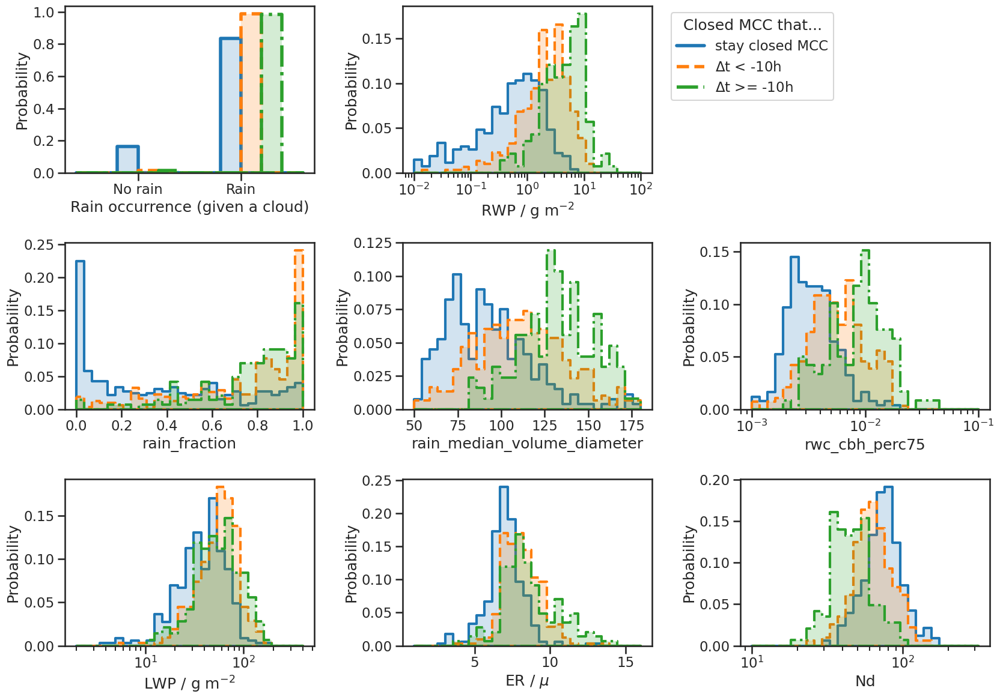

In [141]:
line_styles = ['-', '--', '-.']
colors = sns.color_palette('tab10')
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False


fig, ax = plt.subplots(3,3, figsize=(17, 12))
for j,dffil in enumerate([
    bt_non_trans_c, 
    bt_co_transitioning_c.where((bt_co_transitioning_c.transition_time_diff < -10), drop=True),
    bt_co_transitioning_c.where((bt_co_transitioning_c.transition_time_diff >= -10), drop=True)
    ]):
    sns.histplot(ax=ax[0,0], x=(dffil['rwp'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                 element='step', alpha=0.2, stat='probability', lw=4, color=colors[j], ls=line_styles[j])

    sns.histplot(
        ax=ax[0,1], x=dffil['rwp']*1e3, bins=np.logspace(-2,2,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])

    sns.histplot(
        ax=ax[1,0], x=dffil['rain_fraction'], bins=np.linspace(0,1,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
    sns.histplot(
        ax=ax[1,1], x=dffil['rain_median_volume_diameter']*1e6, bins=np.linspace(5e1, 1.8e2, 30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
    sns.histplot(
        ax=ax[1,2], x=dffil['rwc_cbh_perc75']*1e3, bins=np.logspace(-3, -1, 30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
    
    sns.histplot(
        ax=ax[2,0], x=dffil['lwp']*1e3, bins=np.logspace(0.3,2.6,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])

    sns.histplot(
        ax=ax[2,1], x=dffil['ER']*1e6, bins=np.linspace(1,16,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])
    sns.histplot(
        ax=ax[2,2], x=dffil['Nd']*1e-6, bins=np.logspace(1,2.5,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])


ax[0,0].set_xticks([0.1,1.1])
ax[0,0].set_xticklabels(['No rain', 'Rain'])
ax[0,0].set_xlabel('Rain occurrence (given a cloud)')
ax[0,1].set_xscale('log')
ax[0,1].set_xlabel('RWP / g m$^{-2}$')
ax[0,2].axis('off')
ax[1,2].set_xscale('log')
ax[2,0].set_xscale('log')
ax[2,0].set_xlabel('LWP / g m$^{-2}$')
ax[2,1].set_xscale('linear')
ax[2,1].set_xlabel('ER / $\mu$')
ax[2,2].set_xscale('log')

fig.tight_layout()
legend_handles = [
    plt.Line2D([0], [0], color=colors[0], lw=4, ls=line_styles[0], label='stay closed MCC'),
    plt.Line2D([0], [0], color=colors[1], lw=4, ls=line_styles[1], label='$\Delta$t < -10h'),
    plt.Line2D([0], [0], color=colors[2], lw=4, ls=line_styles[2], label='$\Delta$t >= -10h')
]
ax[0,1].legend(title='Closed MCC that...', handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left')

/tmp/ipykernel_1048858/533491473.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
/tmp/ipykernel_1048858/533491473.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
/tmp/ipykernel_1048858/533491473.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warni

Text(0.5, 1.0, 'Mean RWP given LWP')

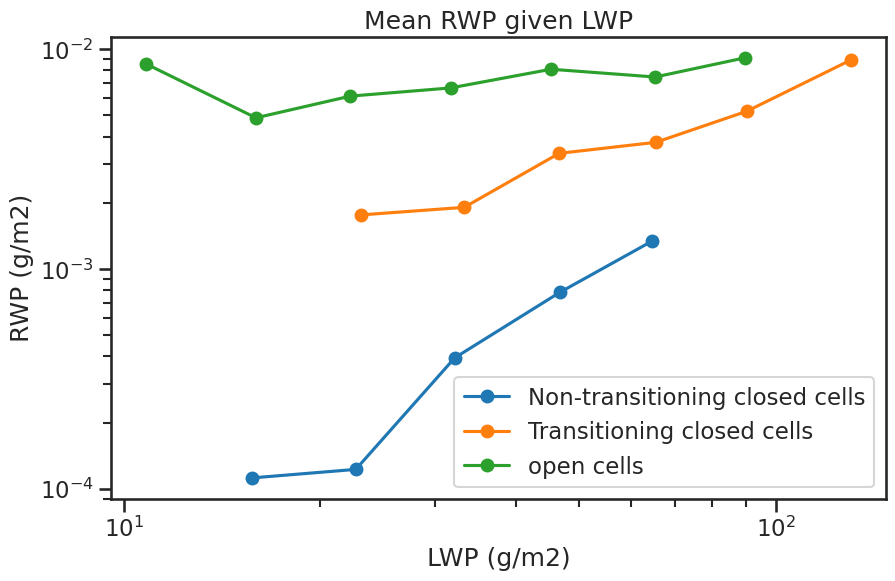

In [109]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for tmp, label in [(bt_non_trans_c, 'Non-transitioning closed cells'), (bt_co_transitioning_c, 'Transitioning closed cells'), (bt_co_back_from_o.where(bt_co_back_from_o.transition_flag == True, drop=True), 'open cells')]:
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    tmp['lwp'] = tmp['lwp']*1e3  # convert to g/m2
    #tmp['rwp'] = tmp['rwp']*1e3  # convert to g/m2
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=label)
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('LWP (g/m2)')
plt.ylabel('RWP (g/m2)')
plt.title('Mean RWP given LWP')

<>:5: SyntaxWarning: invalid escape sequence '\D'
<>:5: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2544272/1476148349.py:5: SyntaxWarning: invalid escape sequence '\D'
  data_list.append((tmp, f'{time_diffs[i]} <= $\Delta$t < {time_diffs[i+1]} hours'))


Text(0.5, 1.0, 'Mean RWP given LWP')

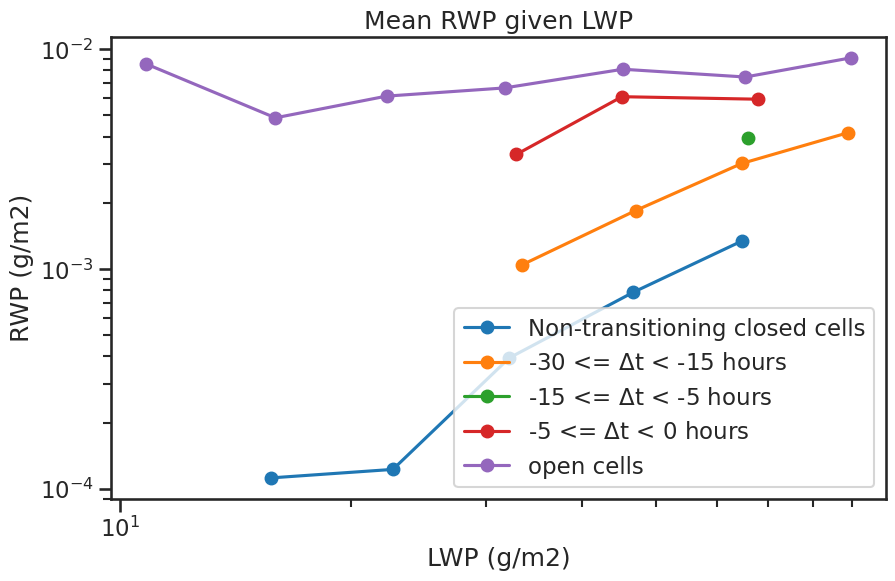

In [142]:
data_list = [(bt_non_trans_c, 'Non-transitioning closed cells')]
time_diffs = [-30, -15, -5, 0]
for i in range(len(time_diffs)-1):
    tmp = bt_co_transitioning_c.where((bt_co_transitioning_c.transition_time_diff >= time_diffs[i]) & (bt_co_transitioning_c.transition_time_diff < time_diffs[i+1]), drop=True)
    data_list.append((tmp, f'{time_diffs[i]} <= $\Delta$t < {time_diffs[i+1]} hours'))
data_list.append((bt_co_back_from_o.where(bt_co_back_from_o.transition_flag == True, drop=True), 'open cells'))

fig, axs = plt.subplots(1,1,figsize=(10,6))
for tmp, label in data_list:
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    tmp['lwp'] = tmp['lwp']*1e3  # convert to g/m2
    #tmp['rwp'] = tmp['rwp']*1e3  # convert to g/m2
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20)), observed=False).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20)), observed=False).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True,marker='o', ax=axs, label=label)
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('LWP (g/m2)')
plt.ylabel('RWP (g/m2)')
plt.title('Mean RWP given LWP')

/tmp/ipykernel_2544272/2783465273.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
/tmp/ipykernel_2544272/2783465273.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
/tmp/ipykernel_2544272/2783465273.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this

Text(0.5, 1.0, 'Mean RWP given LWP')

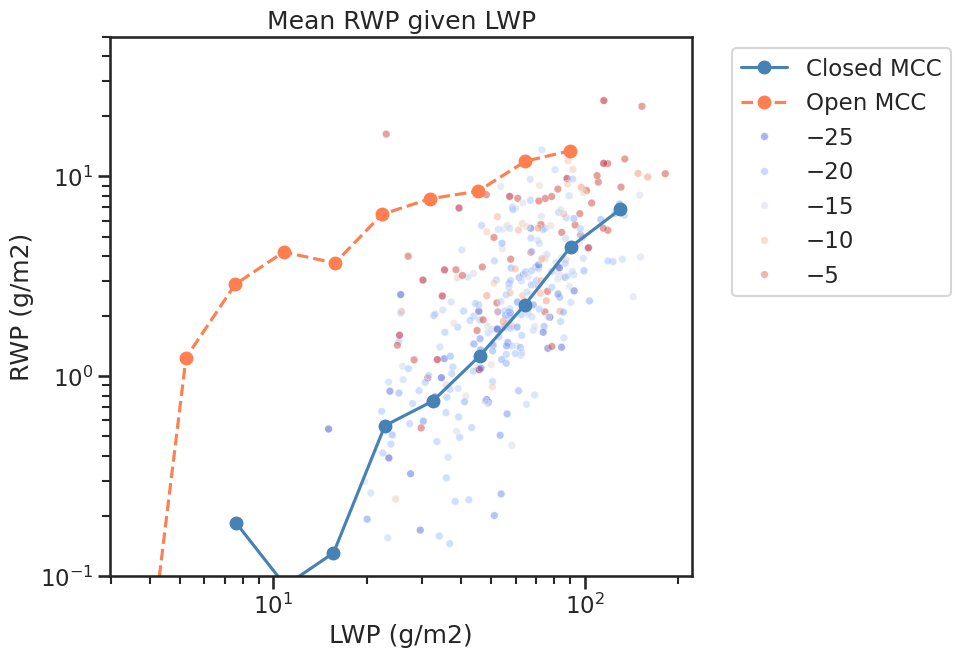

In [143]:
sns.set_context("talk", font_scale=1)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

cats_names = {
    1: 'Closed MCC',
    2: 'Open MCC'
    }

catcolors = {}
catcolors[1] = 'steelblue'
catcolors[2] = 'coral'
line_styles = [(0, (3, 1, 1, 1)), '-', '--', '-.', (0,(3,1,1,1,1,1)), ':']

fig, ax = plt.subplots(1,1,figsize=(7.5,7))
for i in [1,2]:
    tmp = (ds_acmcap.where(ds_acmcap.cats == i, drop=True)) # dffil[(dffil.cats==i)]
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    tmp['lwp'] = tmp['lwp']*1e3  # convert to g/m2
    tmp['rwp'] = tmp['rwp']*1e3  # convert to g/m2
    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 20, np.nan)
    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True, marker='o', ax=ax, label=cats_names[i], color=catcolors[i], linestyle=line_styles[i])

bt_co_c = bt_co_concat.where(bt_co_concat.transition_time_diff <= 0)
#for t in np.unique(bt_co_c.transition_time_diff):
#    tmp = bt_co_c.where(bt_co_c.transition_time_diff == t, drop=True)
#    tmp = tmp[['rwp','lwp']]
#    tmp = tmp.to_dataframe()
#    tmp['lwp'] = tmp['lwp']*1e3  # convert to g/m2
#    tmp['rwp'] = tmp['rwp']*1e3  # convert to g/m2
#    rwp_given_lwp = tmp[['lwp','rwp']].groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).mean()
#    rwp_given_lwp['size'] = tmp.groupby(pd.cut(tmp['lwp'], np.logspace(0,3,20))).size()
#    rwp_given_lwp['rwp'] = rwp_given_lwp['rwp'].where(rwp_given_lwp['size'] >= 2, np.nan)
#    rwp_given_lwp.plot(y='rwp', x='lwp', logy=True, logx=True, marker='o', ax=ax, label=t)

sns.scatterplot(data=bt_co_c.where(bt_co_c.transition_time_diff <= 0), x=bt_co_c['lwp']*1e3, y=bt_co_c['rwp']*1e3, hue='transition_time_diff', palette='coolwarm', legend=True, s=30, ax=ax, alpha=0.5)

ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.set_ylim(1e-1,5e1)
ax.set_xlabel('LWP (g/m2)')
ax.set_ylabel('RWP (g/m2)')
ax.set_title('Mean RWP given LWP')

/tmp/ipykernel_1048858/2661582944.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lwp_given_lon = tmp[['lon_mid','lwp']].groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).mean()
/tmp/ipykernel_1048858/2661582944.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lwp_given_lon['size'] = tmp.groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).size()
/tmp/ipykernel_1048858/2661582944.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default

Text(0.5, 1.0, 'Mean lwp given lon_mid')

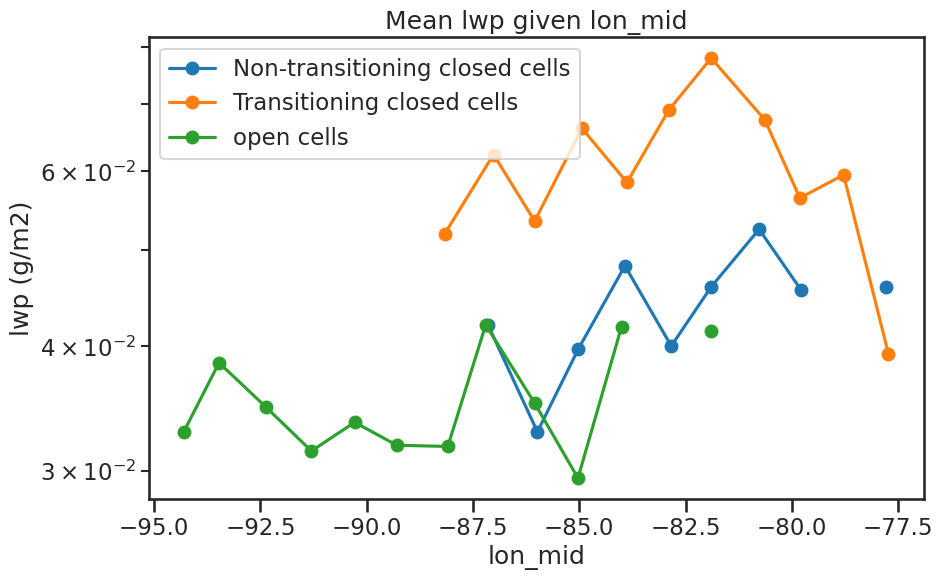

In [112]:
fig, axs = plt.subplots(1,1,figsize=(10,6))
for tmp, label in [(bt_non_trans_c, 'Non-transitioning closed cells'), (bt_co_transitioning_c, 'Transitioning closed cells'), (bt_co_back_from_o.where(bt_co_back_from_o.transition_flag == True, drop=True), 'open cells')]:
    tmp = tmp.sel(timestep=0)
    tmp = tmp.to_dataframe()
    lwp_given_lon = tmp[['lon_mid','lwp']].groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).mean()
    lwp_given_lon['size'] = tmp.groupby(pd.cut(tmp['lon_mid'], np.linspace(-95,-75,20))).size()
    lwp_given_lon['lwp'] = lwp_given_lon['lwp'].where(lwp_given_lon['size'] >= 20, np.nan)
    lwp_given_lon.plot(y='lwp', x='lon_mid', logy=True, logx=False,marker='o', ax=axs, label=label)
    # rotate xlabels and round to 1 decimal place
    #plt.xticks(rotation=45)
#plt.ylim(-10,160)
plt.xlabel('lon_mid')
plt.ylabel('lwp (g/m2)')
plt.title('Mean lwp given lon_mid')

/tmp/ipykernel_2544272/80815408.py:8: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

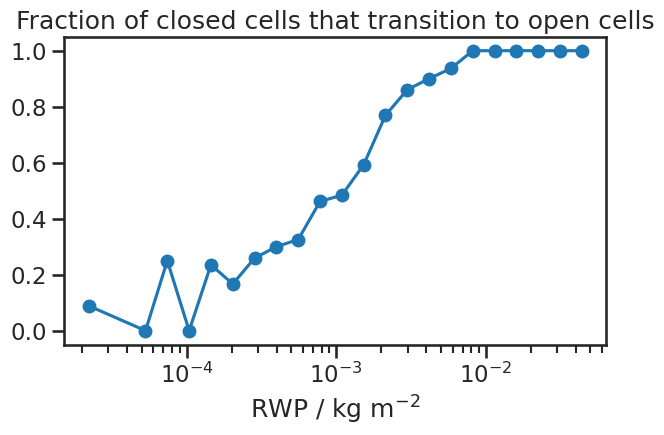

In [144]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-4.5, -1, 25)
bins[0] = 0
rwp_bin_centers = (bins[:-1] + bins[1:]) / 2
rwp_hist_trans = np.histogram(bt_co_transitioning_c.rwp, bins=bins)[0]
rwp_hist_non_trans = np.histogram(bt_non_trans_c.rwp, bins=bins)[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rwp_bin_centers, rwp_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('RWP / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/774150847.py:8: RuntimeWarning: invalid value encountered in divide
  rain_rate_cbh_transition_prob = rain_rate_cbh_hist_trans / rain_rate_cbh_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

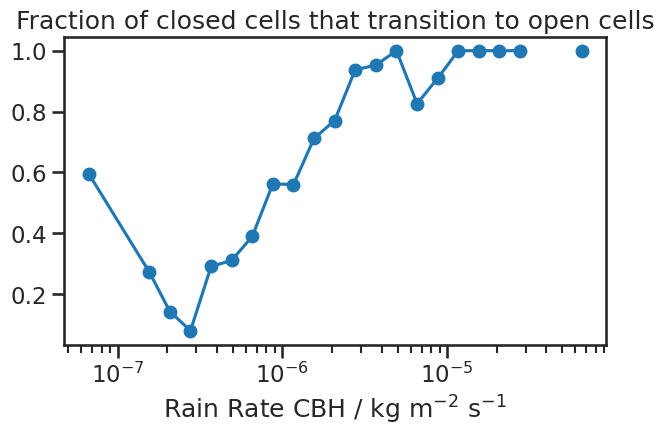

In [ ]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-7., -4., 25)
bins[0] = 0
rain_rate_cbh_bin_centers = (bins[:-1] + bins[1:]) / 2
rain_rate_cbh_hist_trans = np.histogram(bt_co_transitioning_c.rain_rate_cbh, bins=bins)[0]
rain_rate_cbh_hist_non_trans = np.histogram(bt_non_trans_c.rain_rate_cbh, bins=bins)[0]
rain_rate_cbh_hist_total = rain_rate_cbh_hist_trans + rain_rate_cbh_hist_non_trans
rain_rate_cbh_transition_prob = rain_rate_cbh_hist_trans / rain_rate_cbh_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rain_rate_cbh_bin_centers, rain_rate_cbh_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('Rain Rate CBH / kg m$^{-2}$ s$^{-1}$')
plt.title('Fraction of closed cells that transition to open cells')
plt.show()

/tmp/ipykernel_1499759/2139391749.py:8: RuntimeWarning: invalid value encountered in divide
  rwc_cbh_perc95_transition_prob = rwc_cbh_perc95_hist_trans / rwc_cbh_perc95_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

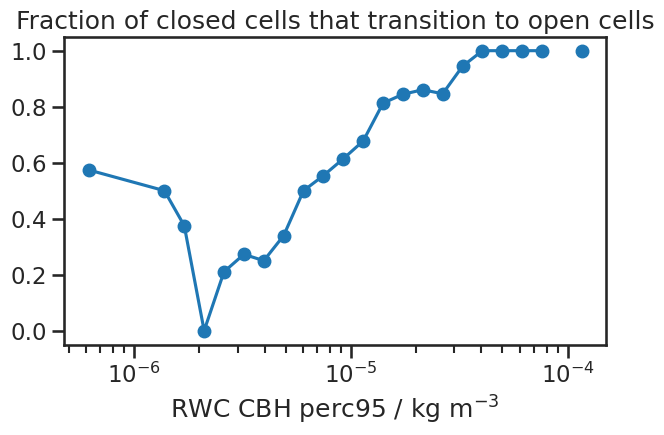

In [54]:
bins = np.logspace(-6., -3.8, 25)
bins[0] = 0
rwc_cbh_perc95_bin_centers = (bins[:-1] + bins[1:]) / 2
    
rwc_cbh_perc95_hist_trans = np.histogram(bt_co_transitioning_c.rwc_cbh_perc95, bins=bins)[0]
rwc_cbh_perc95_hist_non_trans = np.histogram(bt_non_trans_c.rwc_cbh_perc95, bins=bins)[0]
rwc_cbh_perc95_hist_total = rwc_cbh_perc95_hist_trans + rwc_cbh_perc95_hist_non_trans
rwc_cbh_perc95_transition_prob = rwc_cbh_perc95_hist_trans / rwc_cbh_perc95_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rwc_cbh_perc95_bin_centers, rwc_cbh_perc95_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('RWC CBH perc95 / kg m$^{-3}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/974125676.py:8: RuntimeWarning: invalid value encountered in divide
  rain_rate_subcloud_transition_prob = rain_rate_subcloud_hist_trans / rain_rate_subcloud_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

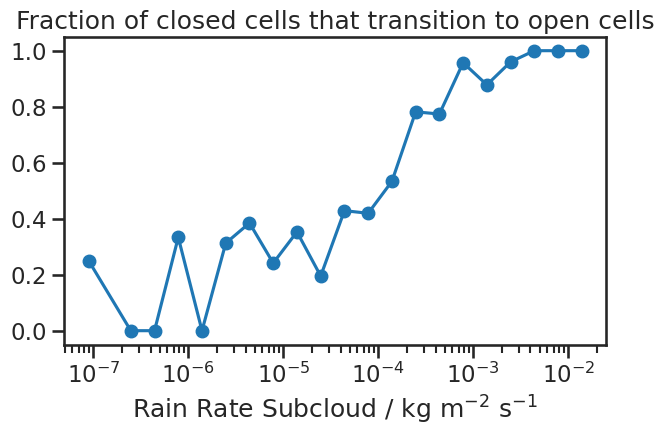

In [118]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-7., -1., 25)
bins[0] = 0
rain_rate_subcloud_bin_centers = (bins[:-1] + bins[1:]) / 2
rain_rate_subcloud_hist_trans = np.histogram(bt_co_transitioning_c.rain_rate_subcloud, bins=bins)[0]
rain_rate_subcloud_hist_non_trans = np.histogram(bt_non_trans_c.rain_rate_subcloud, bins=bins)[0]
rain_rate_subcloud_hist_total = rain_rate_subcloud_hist_trans + rain_rate_subcloud_hist_non_trans
rain_rate_subcloud_transition_prob = rain_rate_subcloud_hist_trans / rain_rate_subcloud_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rain_rate_subcloud_bin_centers, rain_rate_subcloud_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('Rain Rate Subcloud / kg m$^{-2}$ s$^{-1}$')
plt.title('Fraction of closed cells that transition to open cells')

Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

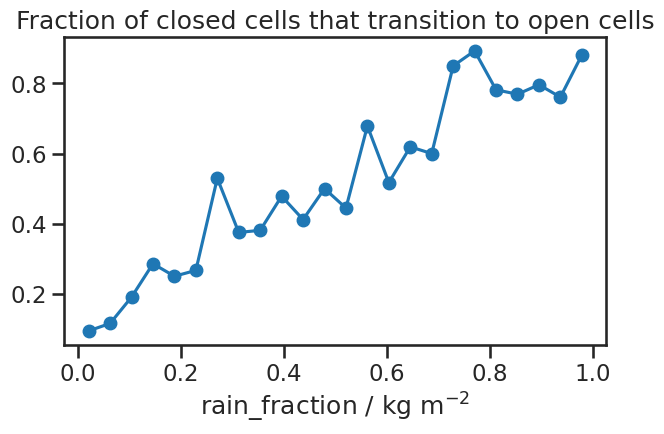

In [119]:
# plot probability that cloud will transition vs rain_fraction
bins = np.linspace(0, 1, 25)
bins[0] = 0
rain_fraction_bin_centers = (bins[:-1] + bins[1:]) / 2
rain_fraction_hist_trans = np.histogram(bt_co_transitioning_c.rain_fraction, bins=bins)[0]
rain_fraction_hist_non_trans = np.histogram(bt_non_trans_c.rain_fraction, bins=bins)[0]
rain_fraction_hist_total = rain_fraction_hist_trans + rain_fraction_hist_non_trans
rain_fraction_transition_prob = rain_fraction_hist_trans / rain_fraction_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rain_fraction_bin_centers, rain_fraction_transition_prob, marker='o')
plt.xlabel('rain_fraction / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/437304266.py:8: RuntimeWarning: invalid value encountered in divide
  rain_median_volume_diameter_transition_prob = rain_median_volume_diameter_hist_trans / rain_median_volume_diameter_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

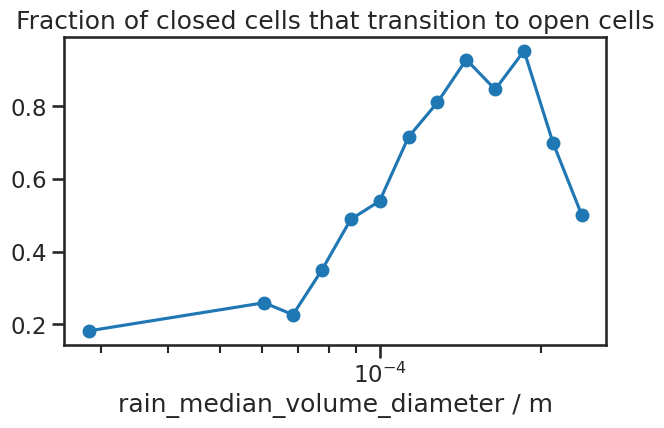

In [120]:
# plot probability that cloud will transition vs rain_median_volume_diameter
bins = np.logspace(-4.3, -3, 25)
bins[0] = 0
rain_median_volume_diameter_bin_centers = (bins[:-1] + bins[1:]) / 2
rain_median_volume_diameter_hist_trans = np.histogram(bt_co_transitioning_c.rain_median_volume_diameter, bins=bins)[0]
rain_median_volume_diameter_hist_non_trans = np.histogram(bt_non_trans_c.rain_median_volume_diameter, bins=bins)[0]
rain_median_volume_diameter_hist_total = rain_median_volume_diameter_hist_trans + rain_median_volume_diameter_hist_non_trans
rain_median_volume_diameter_transition_prob = rain_median_volume_diameter_hist_trans / rain_median_volume_diameter_hist_total
plt.figure(figsize=(7, 4))
plt.xscale('log')
plt.plot(rain_median_volume_diameter_bin_centers, rain_median_volume_diameter_transition_prob, marker='o')
plt.xlabel('rain_median_volume_diameter / m')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/3271198326.py:12: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

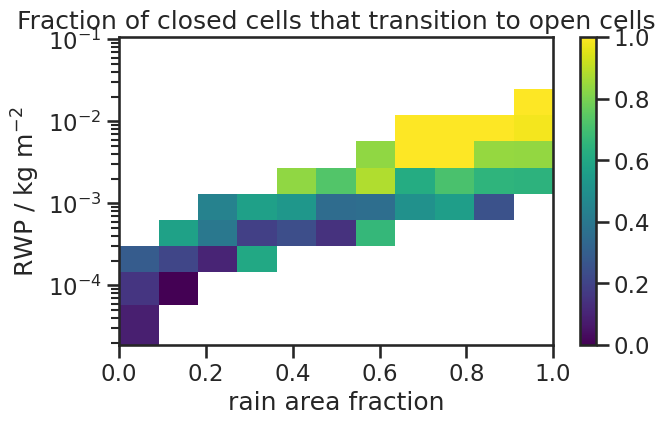

In [121]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 12)
bins_y[0] = 0
bins_x = np.linspace(0, 1, 12)

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_fraction_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rain_fraction, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rain_fraction, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 2, np.nan, rwp_transition_prob) 
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rain_fraction_bin'], coords={'rwp_bin': rwp_bin_centers, 'rain_fraction_bin': rain_fraction_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('rain area fraction')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/1521876788.py:13: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

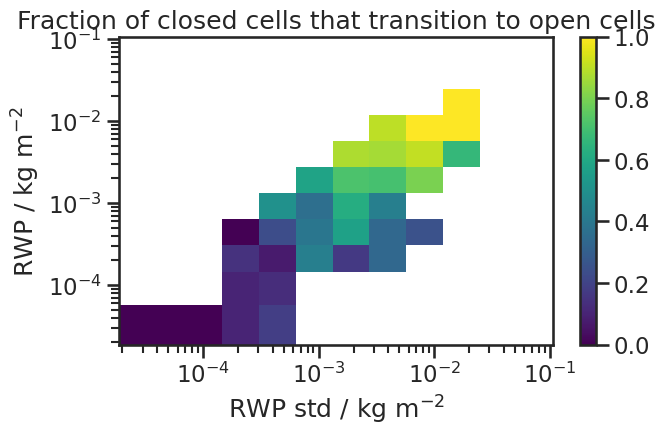

In [122]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 12)
bins_y[0] = 0
bins_x = np.logspace(-4.5, -1, 12)
bins_x[0] = 0

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rwp_std_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rwp_std, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rwp_std, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 2, np.nan, rwp_transition_prob) 
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rwp_std_bin'], coords={'rwp_bin': rwp_bin_centers, 'rwp_std_bin': rwp_std_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log', xscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('RWP std / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/1700057083.py:13: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

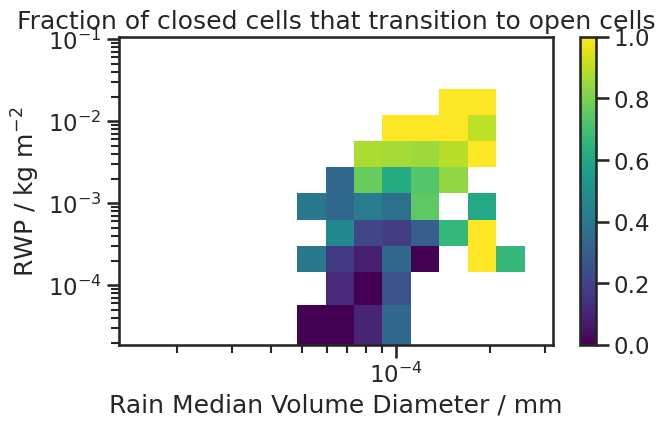

In [123]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 12)
bins_y[0] = 0
bins_x = np.logspace(-4.5, -3.5, 12)
bins_x[0] = 0

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_median_volume_diameter_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 2, np.nan, rwp_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rain_median_volume_diameter_bin'], coords={'rwp_bin': rwp_bin_centers, 'rain_median_volume_diameter_bin': rain_median_volume_diameter_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log', xscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('Rain Median Volume Diameter / mm')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_2544272/1213274747.py:13: RuntimeWarning: invalid value encountered in divide
  rwc_cbh_perc95_transition_prob = rwc_cbh_perc95_hist_trans / rwc_cbh_perc95_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

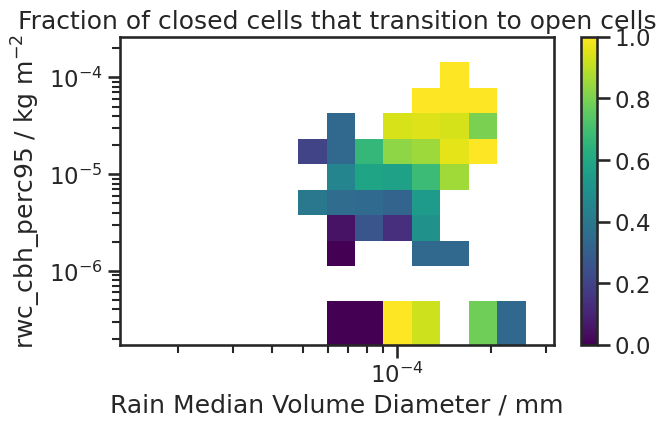

In [149]:
# plot probability that cloud will transition vs rwc_cbh_perc95
bins_y = np.logspace(-6.5, -3.6, 12)
bins_y[0] = 0
bins_x = np.logspace(-4.5, -3.5, 12)
bins_x[0] = 0

rwc_cbh_perc95_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_median_volume_diameter_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwc_cbh_perc95_hist_trans = np.histogram2d(bt_co_transitioning_c.rwc_cbh_perc95, bt_co_transitioning_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwc_cbh_perc95_hist_non_trans = np.histogram2d(bt_non_trans_c.rwc_cbh_perc95, bt_non_trans_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwc_cbh_perc95_hist_total = rwc_cbh_perc95_hist_trans + rwc_cbh_perc95_hist_non_trans
rwc_cbh_perc95_transition_prob = rwc_cbh_perc95_hist_trans / rwc_cbh_perc95_hist_total
rwc_cbh_perc95_transition_prob = np.where(rwc_cbh_perc95_hist_total <= 2, np.nan, rwc_cbh_perc95_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwc_cbh_perc95_transition_prob = xr.DataArray(data=rwc_cbh_perc95_transition_prob, dims=['rwc_cbh_perc95_bin', 'rain_median_volume_diameter_bin'], coords={'rwc_cbh_perc95_bin': rwc_cbh_perc95_bin_centers, 'rain_median_volume_diameter_bin': rain_median_volume_diameter_bin_centers})
plt.figure(figsize=(7, 4))
da_rwc_cbh_perc95_transition_prob.plot(yscale='log', xscale='log')
plt.ylabel('rwc_cbh_perc95 / kg m$^{-2}$')
plt.xlabel('Rain Median Volume Diameter / mm')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/2845530616.py:12: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

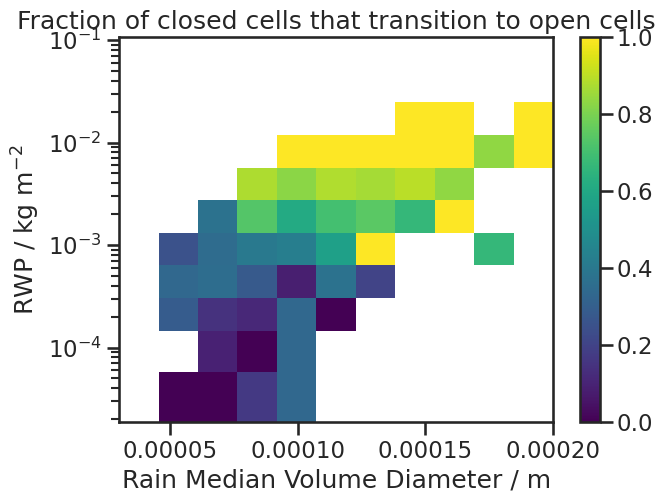

In [124]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 12)
bins_y[0] = 0
bins_x = np.linspace(3e-5, 2e-4, 12)

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_median_volume_diameter_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.rain_median_volume_diameter, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 2, np.nan, rwp_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'rain_median_volume_diameter_bin'], coords={'rwp_bin': rwp_bin_centers, 'rain_median_volume_diameter_bin': rain_median_volume_diameter_bin_centers})
plt.figure(figsize=(7, 5))
da_rwp_transition_prob.plot(yscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('Rain Median Volume Diameter / m')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/2009150771.py:13: RuntimeWarning: invalid value encountered in divide
  rwp_transition_prob = rwp_hist_trans / rwp_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

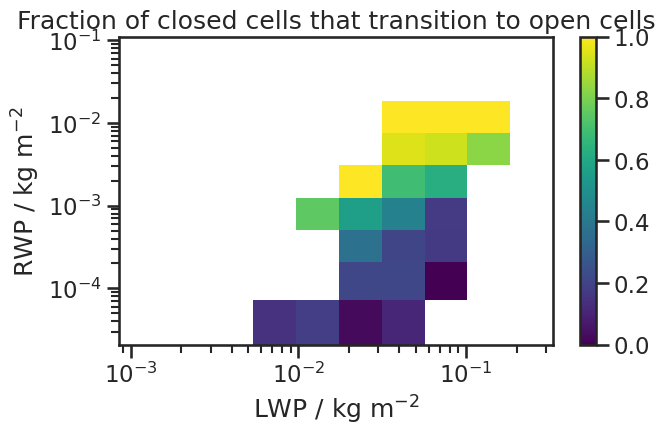

In [125]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-4.5, -1, 10)
bins_y[0] = 0
bins_x = np.logspace(-2.8, -0.5, 10)
bins_x[0] = 0

rwp_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
lwp_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp, bt_co_transitioning_c.lwp, bins=[bins_y, bins_x])[0]
rwp_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp, bt_non_trans_c.lwp, bins=[bins_y, bins_x])[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
rwp_transition_prob = np.where(rwp_hist_total <= 3, np.nan, rwp_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwp_transition_prob = xr.DataArray(data=rwp_transition_prob, dims=['rwp_bin', 'lwp_bin'], coords={'rwp_bin': rwp_bin_centers, 'lwp_bin': lwp_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_transition_prob.plot(yscale='log', xscale='log')
plt.ylabel('RWP / kg m$^{-2}$')
plt.xlabel('LWP / kg m$^{-2}$')
plt.title('Fraction of closed cells that transition to open cells')

/tmp/ipykernel_1048858/2562832824.py:12: RuntimeWarning: invalid value encountered in divide
  rwp_subcloud_transition_prob = rwp_subcloud_hist_trans / rwp_subcloud_hist_total


Text(0.5, 1.0, 'Fraction of closed cells that transition to open cells')

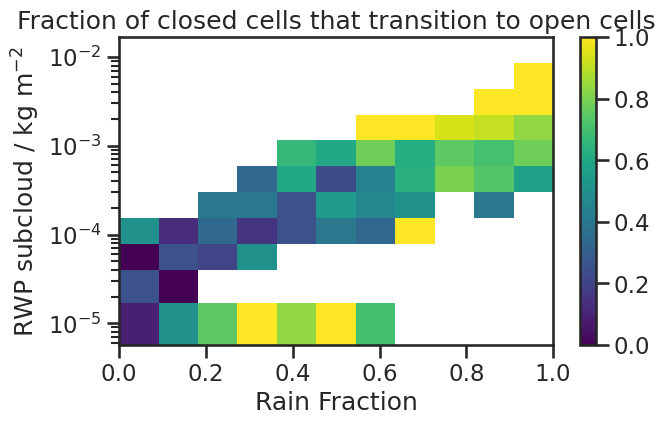

In [126]:
# plot probability that cloud will transition vs RWP
bins_y = np.logspace(-5, -1.8, 12)
bins_y[0] = 0
bins_x = np.linspace(0, 1, 12)

rwp_subcloud_bin_centers = (bins_y[:-1] + bins_y[1:]) / 2
rain_fraction_bin_centers = (bins_x[:-1] + bins_x[1:]) / 2

rwp_subcloud_hist_trans = np.histogram2d(bt_co_transitioning_c.rwp_subcloud, bt_co_transitioning_c.rain_fraction, bins=[bins_y, bins_x])[0]
rwp_subcloud_hist_non_trans = np.histogram2d(bt_non_trans_c.rwp_subcloud, bt_non_trans_c.rain_fraction, bins=[bins_y, bins_x])[0]
rwp_subcloud_hist_total = rwp_subcloud_hist_trans + rwp_subcloud_hist_non_trans
rwp_subcloud_transition_prob = rwp_subcloud_hist_trans / rwp_subcloud_hist_total
rwp_subcloud_transition_prob = np.where(rwp_subcloud_hist_total <= 2, np.nan, rwp_subcloud_transition_prob)  # set to nan where total count is 0 to avoid division by zero
da_rwp_subcloud_transition_prob = xr.DataArray(data=rwp_subcloud_transition_prob, dims=['rwp_subcloud_bin', 'rain_fraction_bin'], coords={'rwp_subcloud_bin': rwp_subcloud_bin_centers, 'rain_fraction_bin': rain_fraction_bin_centers})
plt.figure(figsize=(7, 4))
da_rwp_subcloud_transition_prob.plot(yscale='log', xscale='linear')
plt.ylabel('RWP subcloud / kg m$^{-2}$')
plt.xlabel('Rain Fraction')
plt.title('Fraction of closed cells that transition to open cells')

#### compare CO clouds with neighboring non-trans clouds

In [61]:
tmp = bt_co_forward_from_c.sel(timestep = slice(0,30)).goes_cats.fillna(-1)
enough_datapoints_along_track = (tmp.isin([0,1,2,3,4,5]).sum(dim='timestep')) >= 6
always_closed_cell = tmp.isin([-1,1]).all(dim='timestep')

# new flag: 1 = transition to open cell, 0 = stay closed cell, -1 = something else (not enough data or transition to other category)
bt_co_forward_from_c['flag_closed_cell_transition'] = xr.where(bt_co_forward_from_c.transition_flag, 1, xr.where(~bt_co_forward_from_c.transition_flag & enough_datapoints_along_track & always_closed_cell, 0, -1))

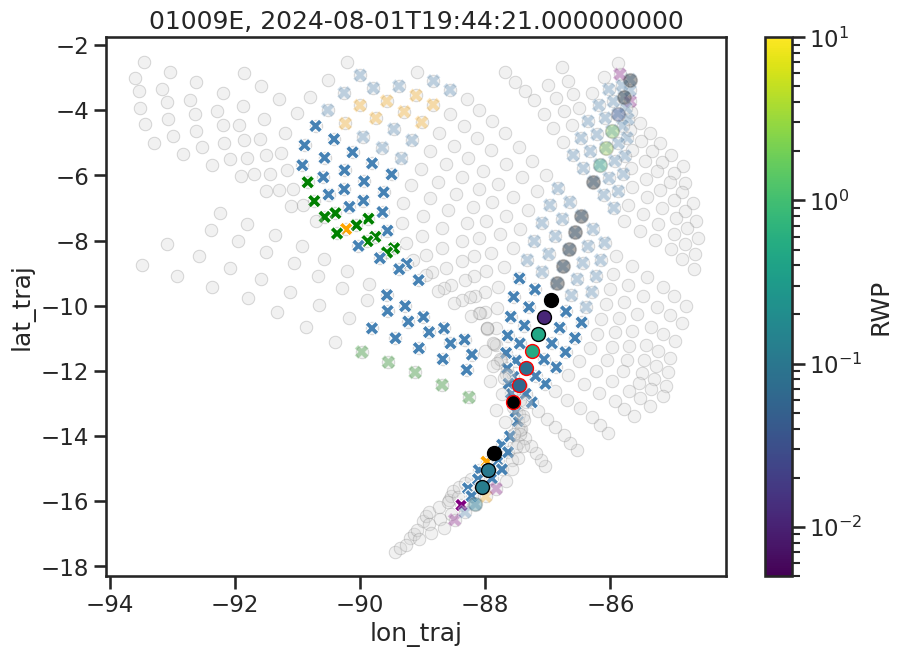

In [29]:
for orbit, group in bt_co_forward_from_c.groupby('orbit'):
    non_trans_closed_cells = (group.flag_closed_cell_transition == 0).sum()
    co_trans_closed_cells = (group.flag_closed_cell_transition == 1).sum()
    if non_trans_closed_cells > 0 and co_trans_closed_cells > 0:
        
        # Create colormap normalization once outside the loop
        norm = LogNorm(vmin=5e-3, vmax=1e1)
        cmap = plt.cm.viridis
        plt.figure(figsize=(10, 7))
        
        for i in range(len(group.time_startpoint)):
            tmp = group.isel(time_startpoint=i)
            if tmp.flag_closed_cell_transition == 0:
                # persistent closed cell
                alpha = 1.0
                marker_edge_color = 'black'
            elif tmp.flag_closed_cell_transition == 1:
                # transition from closed to open cell
                alpha = 1.0
                marker_edge_color = 'red'
            else:
                alpha = 0.3
                marker_edge_color = 'Grey'

            sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', color='lightgrey', alpha=0.3, edgecolor='Grey', legend=False)
            
            # Get the RWP value and map it to a color
            rwp_value = tmp.sel(timestep=0).rwp.values*1e3  # convert to g/m²
            color = cmap(norm(rwp_value))
            
            plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 
                    color=color, marker='o', markersize=10, markeredgecolor=marker_edge_color, alpha=alpha)
            sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
        
        # Add colorbar to show the RWP scale
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        plt.colorbar(sm, label='RWP', ax=plt.gca())
        
        plt.title(f'{orbit}, {group.time_startpoint.values[0]}')
        plt.show()
        break

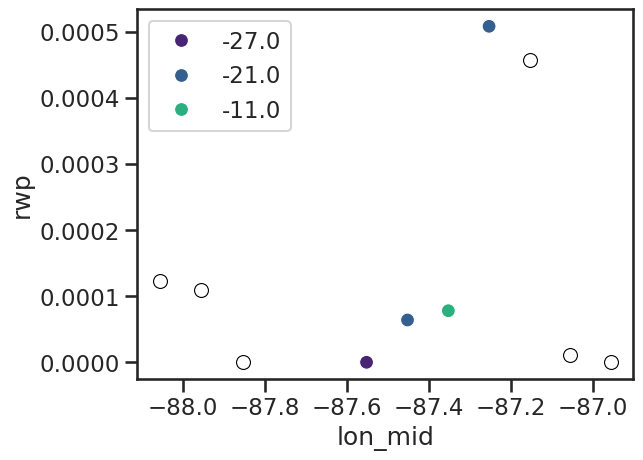

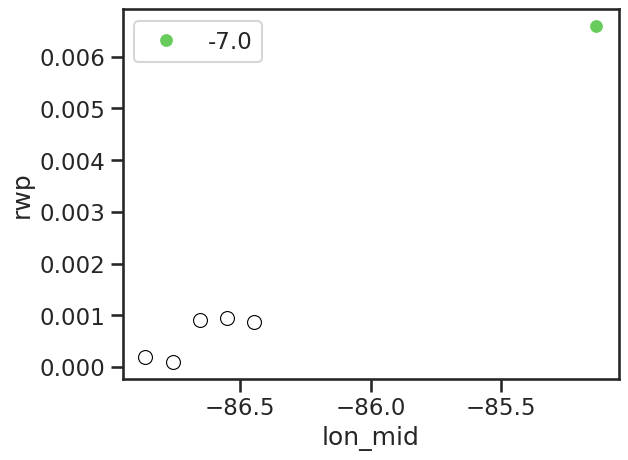

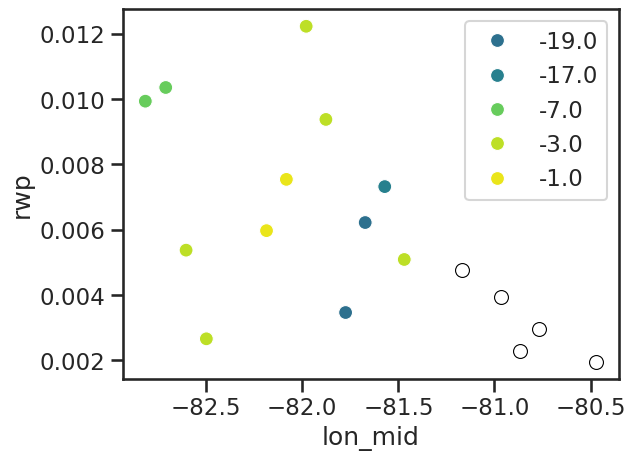

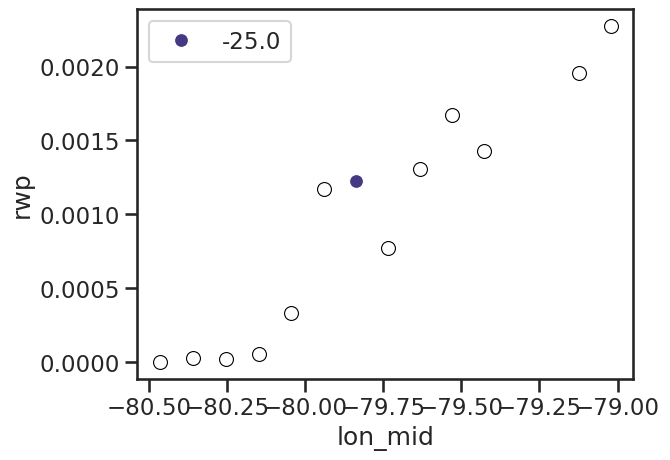

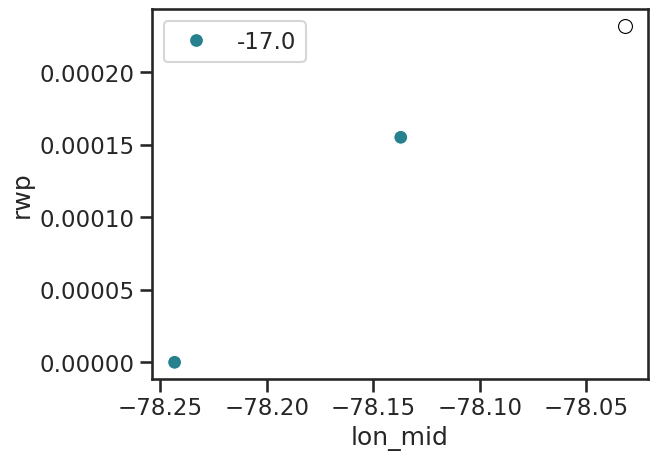

...

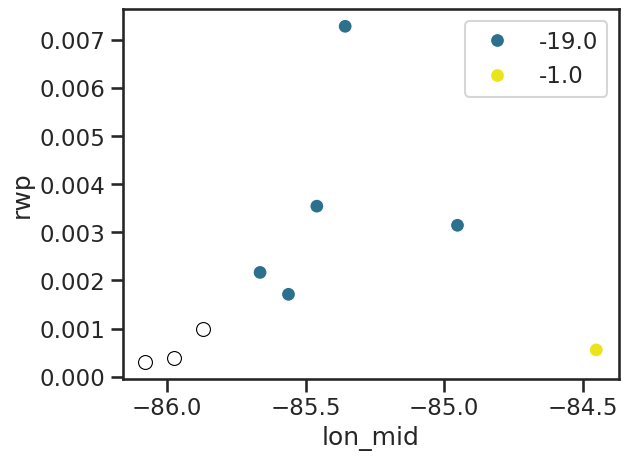

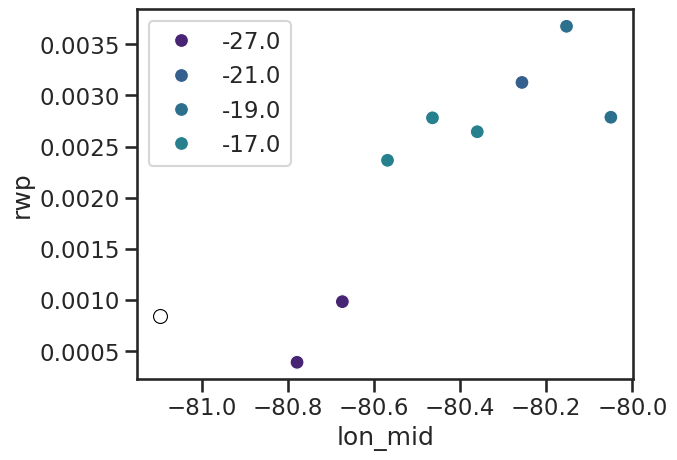

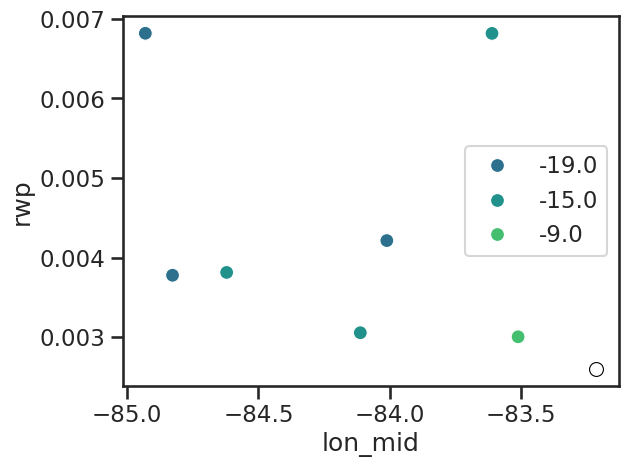

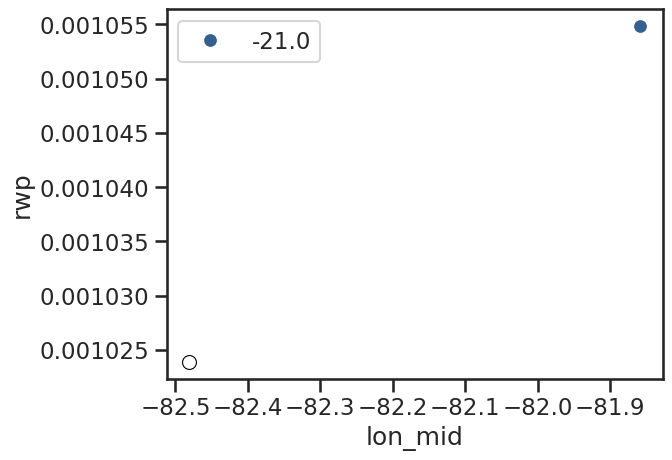

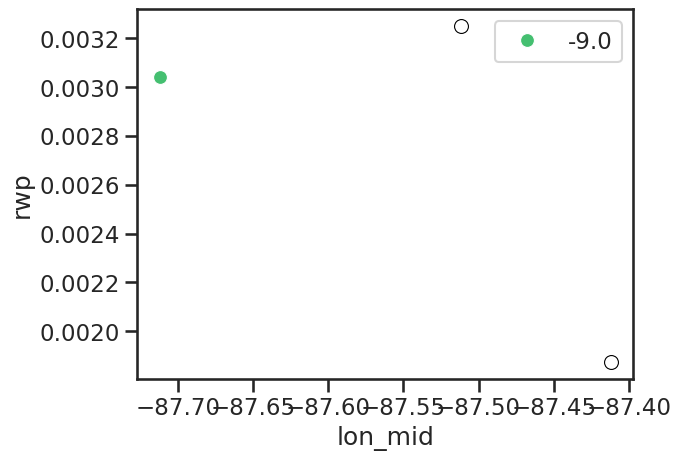

In [62]:
for orbit, group in bt_co_forward_from_c.groupby('orbit'):
    non_trans_closed_cells = (group.flag_closed_cell_transition == 0).sum()
    co_trans_closed_cells = (group.flag_closed_cell_transition == 1).sum()
    if non_trans_closed_cells > 0 and co_trans_closed_cells > 0:
        sns.scatterplot(data=group.where(group.flag_closed_cell_transition == 1, drop=True), x='lon_mid', y='rwp', hue='transition_time_diff', 
                        palette='viridis', hue_norm=(-30,0), legend=True, marker='o', s=100)
        sns.scatterplot(data=group.where(group.flag_closed_cell_transition == 0, drop=True), x='lon_mid', y='rwp',
                        color='white', legend=True, marker='o', s=100, edgecolor='black')
        plt.show()

#### distinguish POC "initiating" and "following" clouds

In [63]:
bt_C = bt_with_goes.where(bt_with_goes.goes_cat_at_ec_overpass == 1)
bt_co_forward_from_c_all = get_transition_properties(bt_C, transition_from_goes_cats=[1], transition_to_goes_cats=[2], backward=False)

In [64]:
bt_co_forward_from_c_all['time_diff_to_poc_formation'] = xr.DataArray(np.full(len(bt_co_forward_from_c_all.time_startpoint), np.nan), dims='time_startpoint', 
                                                                      coords={'time_startpoint': bt_co_forward_from_c_all.time_startpoint.values})
bt_co_forward_from_c_all['size_poc'] = xr.DataArray(np.full(len(bt_co_forward_from_c_all.time_startpoint), np.nan), dims='time_startpoint', 
                                                                      coords={'time_startpoint': bt_co_forward_from_c_all.time_startpoint.values})
for orbit, group in bt_co_forward_from_c_all.groupby('orbit'):
    print(orbit)
    #group.transition_flag.plot()
    #group.transition_time_diff.plot()
    
    # find connected clusters of transitioning clouds along the track using scipy label
    from scipy.ndimage import label
    labeled_array, num_features = label(group.transition_flag)

    for feature in range(1, num_features+1):
        mask = (labeled_array == feature)
        feature_group = group.isel({'time_startpoint': mask})  # Adjust dimension name as needed
        first_transition = feature_group.transition_time_diff.max()
        time_diff_to_poc_formation = feature_group.transition_time_diff - first_transition
        size_poc =feature_group.sizes['time_startpoint']
        # Assign values at specific coordinates
        bt_co_forward_from_c_all['time_diff_to_poc_formation'].loc[time_diff_to_poc_formation.time_startpoint] = time_diff_to_poc_formation
        bt_co_forward_from_c_all['size_poc'].loc[time_diff_to_poc_formation.time_startpoint] = size_poc

        #if size_poc >= 2:
        #    feature_group.transition_time_diff.plot(figsize=(4,2), marker='o')
        #    plt.show()

01009E
01024E
01040E
01056E
01071E
01087E
01102E
01133E
01164E
01180E
01195E
01211E
01227E
01242E
01258E
01273E
01289E
01304E
01320E
01335E
01351E
01367E
01382E
01398E
01413E
01460E
01475E
01491E
01522E
01538E
01553E
01569E
01584E
01600E
01616E
01631E
01647E
01678E
01693E
01709E
01724E
01740E
01756E
01771E
01787E
01833E
01849E
01864E
01880E
01896E
01911E
01927E
01942E
02005E
02020E
02036E
02051E
02067E
02082E
02160E
02176E
02191E
02222E
02238E
02253E
02269E
02285E
02300E
02316E
02331E
02378E
02394E
02409E
02425E
02440E
02456E
02471E
02487E
02518E
02534E
02549E
02565E
02596E
02627E
02642E
02658E
02674E
02689E
02705E
02720E
02736E
02751E
02767E
02783E
02798E
02829E
02876E
02891E
02907E
02923E
02938E
02954E
02969E
02985E
03000E
03016E
03031E
03047E
03063E
03078E
03094E
03187E
03203E
03218E
03249E
03265E
03280E
03296E
03312E
03358E
03374E
03389E
03405E
03420E
03436E
03452E
03467E
03483E
03498E
03514E
03529E
03545E
03561E
03576E
03592E
03607E
03623E
03638E
03654E
03669E
03716E
03732E
03747E

In [65]:
bt_co_forward_from_c_all['time_startpoint'] = bt_co_forward_from_c_all.time_startpoint.dt.round('0.1s')
# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_co_forward_from_c_all, ds_acmcap, join='left')
# Then merge
bt_co_forward_from_c_all = bt_aligned.merge(acmcap_aligned)

In [66]:
bt_co_forward_from_c_all

<xarray.Dataset> Size: 93MB
Dimensions:                               (time_startpoint: 12920, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 103kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 103kB '010...
Data variables: (12/140)
    lat_traj                              (time_startpoint, timestep) float64 4MB ...
    lon_traj                              (time_startpoint, timestep) float64 4MB ...
    plev_traj                             (time_startpoint, timestep) float64 4MB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 4MB ...
    goes_cats                             (time_startpoint, timestep) float64 4MB ...
    goes_cert                             (time_startpoint, timestep) float64 4MB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 103kB 0.0...
    lwp_cv                                (time_startpoint) float64 103kB 0.5...
    ER_cv                                 (time_startpoint) float64 103kB 0.3...
    Nd_cv                                 (time_startpoint) float64 103kB 0.3...
    rwp_cv                                (time_startpoint) float64 103kB nan...
    rain_median_volume_diameter_cv        (time_startpoint) float64 103kB nan...

In [67]:
bt_co_forward_from_c = bt_co_forward_from_c_all.where((bt_co_forward_from_c_all.goes_cat_at_ec_overpass == 1) & (bt_co_forward_from_c_all.transition_flag == True), drop=True)

In [68]:
bt_poc_initiators =bt_co_forward_from_c.where((
                                    (bt_co_forward_from_c.size_poc >= 2)  # only for POC of at least size 2
                                    & (bt_co_forward_from_c.time_diff_to_poc_formation == 0)  # filter for cloud scenes that are the first to transition within their POC
                                    #& (bt_co_forward_from_c.transition_uncertainty < 2),  # filter out nighttime transitions
                                    ),
                                    drop=True)
bt_poc_followers =bt_co_forward_from_c.where((
                                    (bt_co_forward_from_c.size_poc >= 2)  # only for POC of at least size 2
                                    & (bt_co_forward_from_c.time_diff_to_poc_formation < 0)),  # filter for cloud scenes that are the first to transition within their POC
                                    drop=True)

In [69]:
bt_poc_initiators

<xarray.Dataset> Size: 1MB
Dimensions:                               (time_startpoint: 179, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 1kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 1kB '01009...
Data variables: (12/140)
    lat_traj                              (time_startpoint, timestep) float64 62kB ...
    lon_traj                              (time_startpoint, timestep) float64 62kB ...
    plev_traj                             (time_startpoint, timestep) float64 62kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 62kB ...
    goes_cats                             (time_startpoint, timestep) float64 62kB ...
    goes_cert                             (time_startpoint, timestep) float64 62kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 1kB 0.199...
    lwp_cv                                (time_startpoint) float64 1kB 1.046...
    ER_cv                                 (time_startpoint) float64 1kB 0.565...
    Nd_cv                                 (time_startpoint) float64 1kB 0.675...
    rwp_cv                                (time_startpoint) float64 1kB 7.261...
    rain_median_volume_diameter_cv        (time_startpoint) float64 1kB 0.115...

In [70]:
bt_poc_followers

<xarray.Dataset> Size: 1MB
Dimensions:                               (time_startpoint: 196, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 2kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 2kB '01009...
Data variables: (12/140)
    lat_traj                              (time_startpoint, timestep) float64 67kB ...
    lon_traj                              (time_startpoint, timestep) float64 67kB ...
    plev_traj                             (time_startpoint, timestep) float64 67kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 67kB ...
    goes_cats                             (time_startpoint, timestep) float64 67kB ...
    goes_cert                             (time_startpoint, timestep) float64 67kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 2kB 0.201...
    lwp_cv                                (time_startpoint) float64 2kB 1.009...
    ER_cv                                 (time_startpoint) float64 2kB 0.481...
    Nd_cv                                 (time_startpoint) float64 2kB 1.087...
    rwp_cv                                (time_startpoint) float64 2kB 20.38...
    rain_median_volume_diameter_cv        (time_startpoint) float64 2kB 0.442...

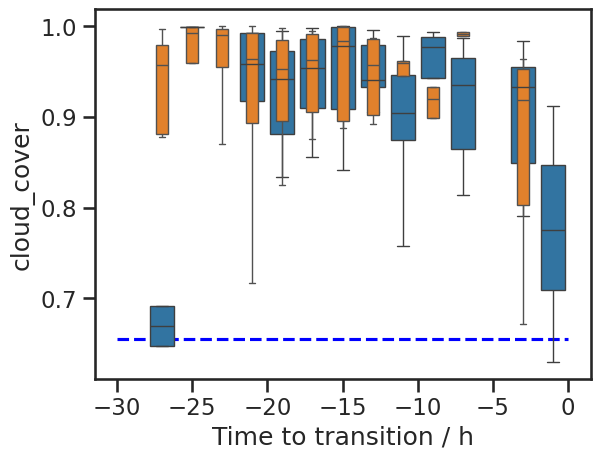

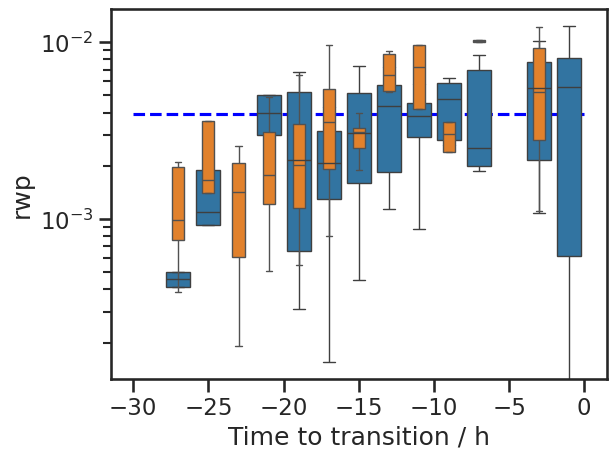

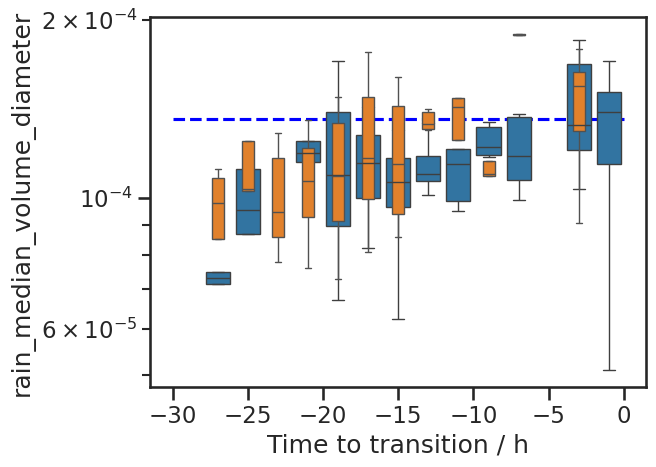

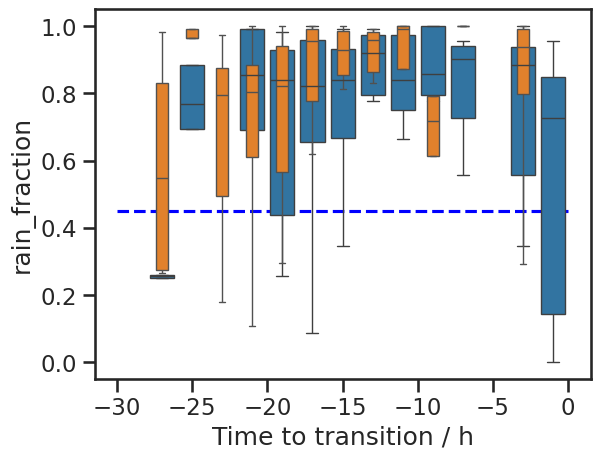

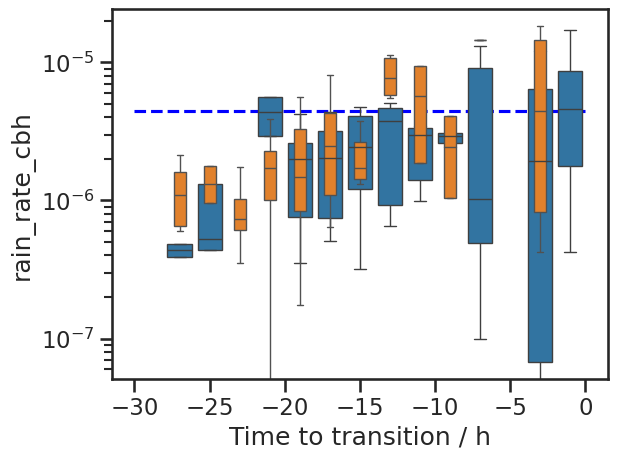

...

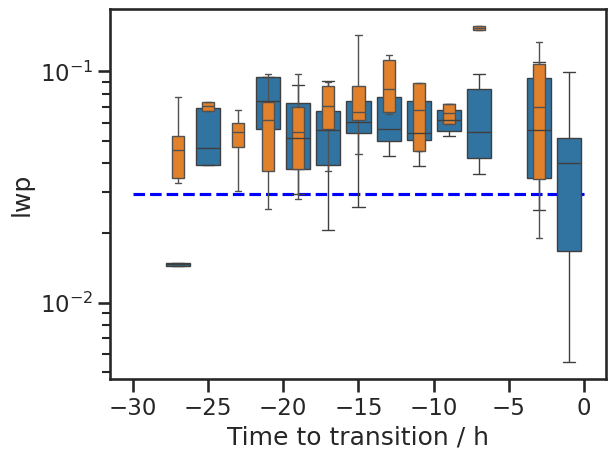

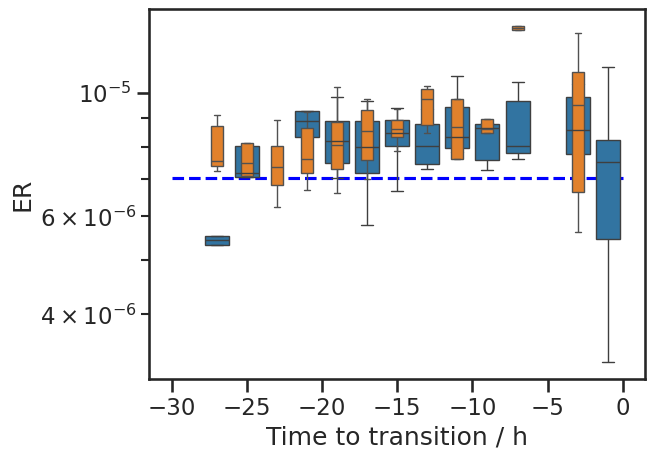

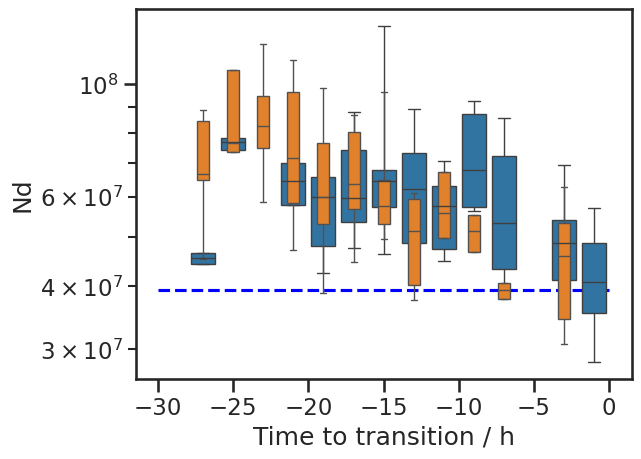

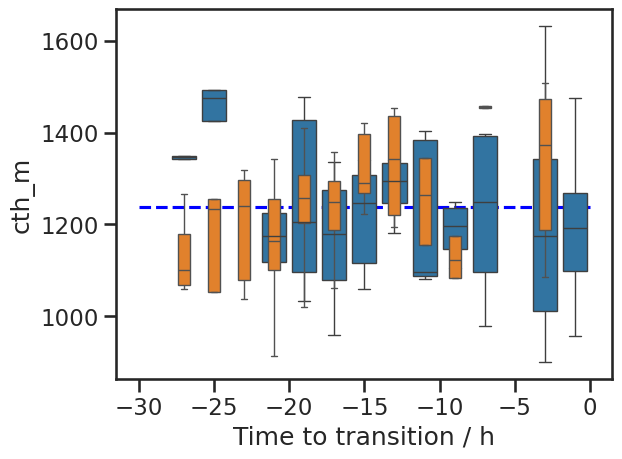

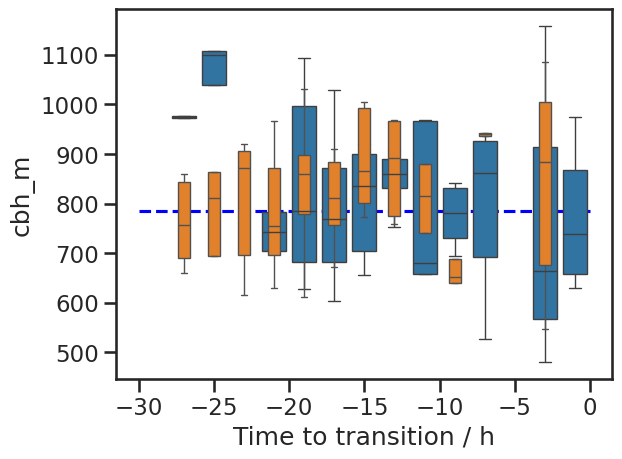

In [71]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False


for var, ylim, yscale in [('cloud_cover', (0, 1), 'linear'),
                          ('rwp', (9e-2, 5e1), 'log'), 
                          ('rain_median_volume_diameter', (1e-5, 1e-3), 'log'),
                          ('rain_fraction', (0, 1), 'linear'),
                          ('rain_rate_cbh', (1e-6, 2e-4), 'log'),
                          ('rain_rate_subcloud', (1e-6, 2e-4), 'log'),
                          ('lwp', (1e-2, 2e-1), 'log'), 
                          ('ER', (5e-6, 2e-5), 'log'),
                          ('Nd', (1e7, 1e9), 'log'),
                          ('cth_m', (0, 3000), 'linear'),
                          ('cbh_m', (0, 3000), 'linear')
                          ]:
    plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=-30, xmax=0, color='blue', linestyle='--')
    sns.boxplot(data = bt_poc_initiators, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=2, showfliers=False)
    sns.boxplot(data = bt_poc_followers, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=1.5, showfliers=False)
    plt.yscale(yscale)
    #plt.ylim(ylim)
    plt.xlabel('Time to transition / h')
    plt.show()

#### distinguish POC and larger-scale open cells

In [ ]:
bt_poc =bt_co_forward_from_c.where(
                                    (bt_co_forward_from_c.size_poc <= 5), 
                                    drop=True)
bt_largescale_open =bt_co_forward_from_c.where(
                                    (bt_co_forward_from_c.size_poc > 5),  
                                    drop=True)

In [73]:
bt_poc

<xarray.Dataset> Size: 2MB
Dimensions:                               (time_startpoint: 334, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 3kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 3kB '01009...
Data variables: (12/140)
    lat_traj                              (time_startpoint, timestep) float64 115kB ...
    lon_traj                              (time_startpoint, timestep) float64 115kB ...
    plev_traj                             (time_startpoint, timestep) float64 115kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 115kB ...
    goes_cats                             (time_startpoint, timestep) float64 115kB ...
    goes_cert                             (time_startpoint, timestep) float64 115kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 3kB 0.201...
    lwp_cv                                (time_startpoint) float64 3kB 1.009...
    ER_cv                                 (time_startpoint) float64 3kB 0.481...
    Nd_cv                                 (time_startpoint) float64 3kB 1.087...
    rwp_cv                                (time_startpoint) float64 3kB 20.38...
    rain_median_volume_diameter_cv        (time_startpoint) float64 3kB 0.442...

In [74]:
bt_largescale_open

<xarray.Dataset> Size: 992kB
Dimensions:                               (time_startpoint: 138, timestep: 43)
Coordinates:
  * time_startpoint                       (time_startpoint) datetime64[ns] 1kB ...
  * timestep                              (timestep) int64 344B -42 -40 ... 42
    orbit                                 (time_startpoint) object 1kB '01071...
Data variables: (12/140)
    lat_traj                              (time_startpoint, timestep) float64 47kB ...
    lon_traj                              (time_startpoint, timestep) float64 47kB ...
    plev_traj                             (time_startpoint, timestep) float64 47kB ...
    datetime_traj                         (time_startpoint, timestep) datetime64[ns] 47kB ...
    goes_cats                             (time_startpoint, timestep) float64 47kB ...
    goes_cert                             (time_startpoint, timestep) float64 47kB ...
    ...                                    ...
    cth_m_cv                              (time_startpoint) float64 1kB 0.112...
    lwp_cv                                (time_startpoint) float64 1kB 0.696...
    ER_cv                                 (time_startpoint) float64 1kB 0.276...
    Nd_cv                                 (time_startpoint) float64 1kB 0.588...
    rwp_cv                                (time_startpoint) float64 1kB 0.816...
    rain_median_volume_diameter_cv        (time_startpoint) float64 1kB 0.270...

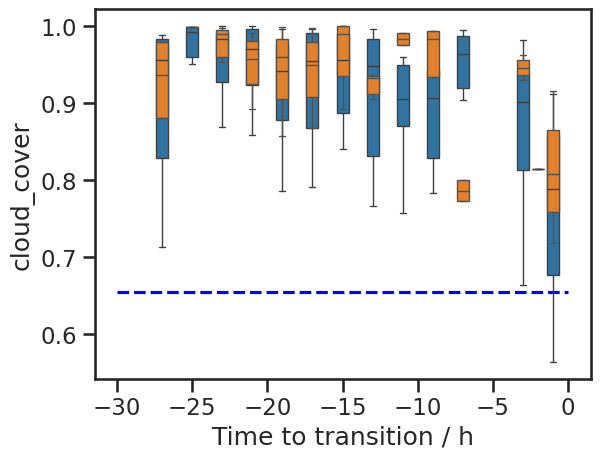

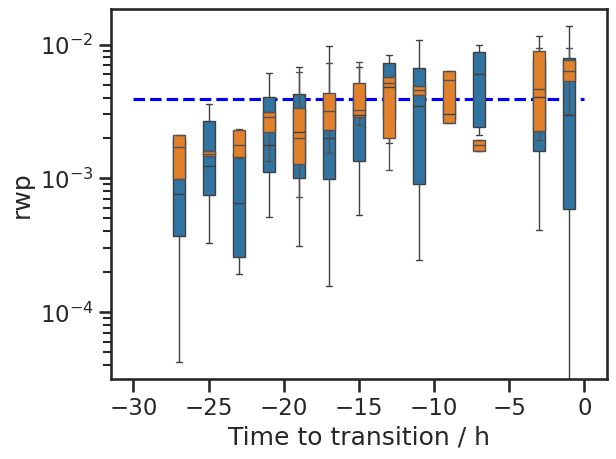

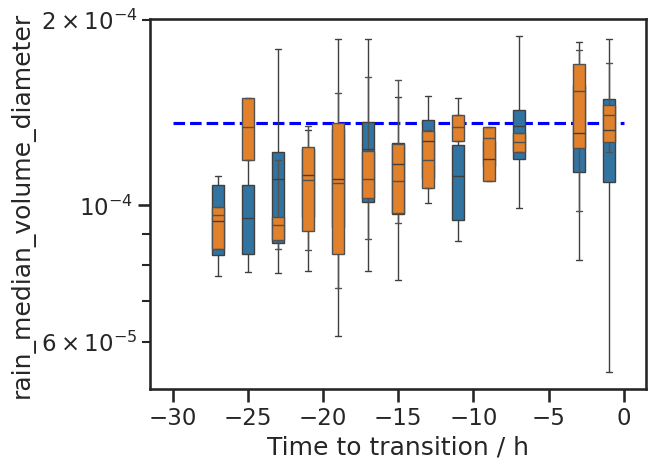

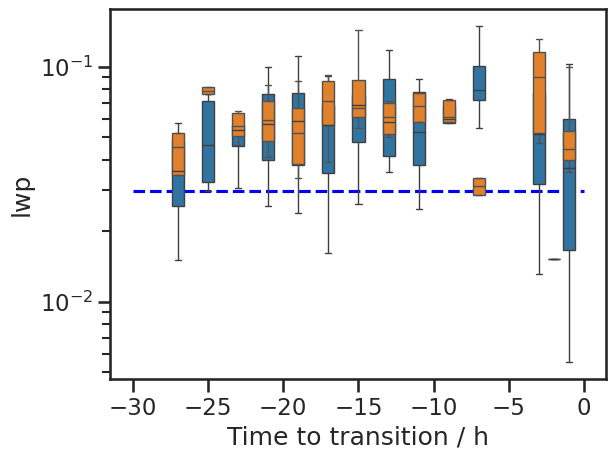

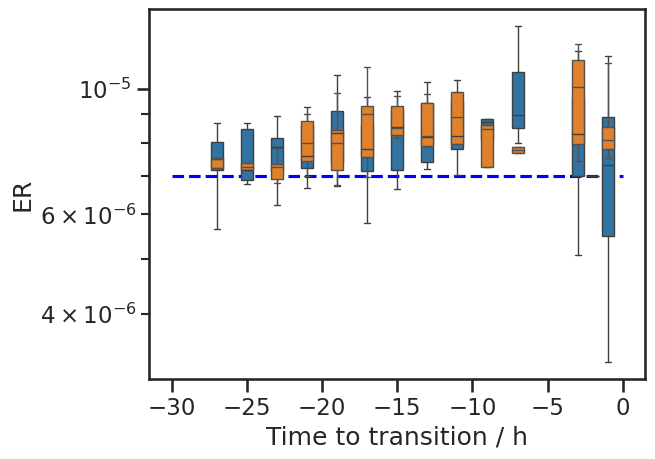

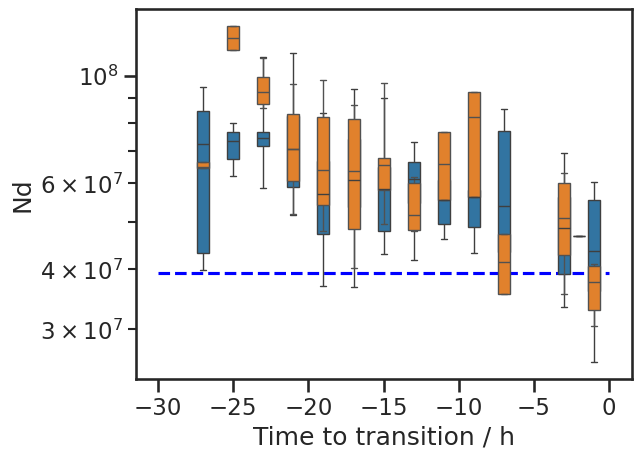

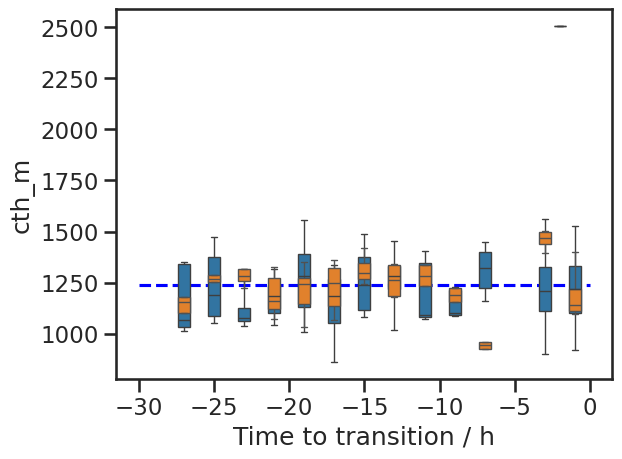

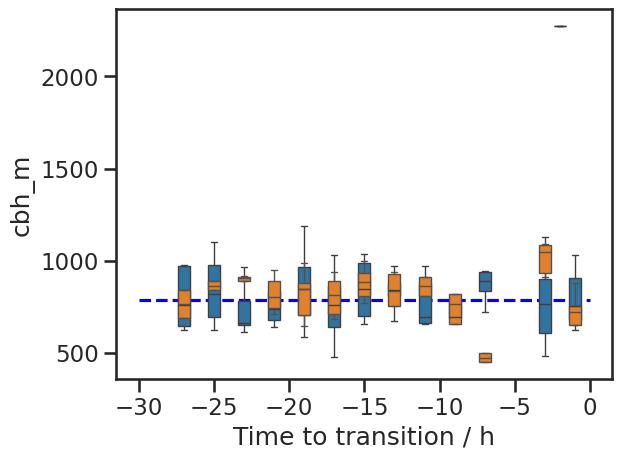

In [75]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False


for var, ylim, yscale in [('cloud_cover', (0, 1), 'linear'),
                          ('rwp', (9e-2, 5e1), 'log'), 
                          ('rain_median_volume_diameter', (1e-5, 1e-3), 'log'),
                          ('lwp', (1e-2, 2e-1), 'log'), 
                          ('ER', (5e-6, 2e-5), 'log'),
                          ('Nd', (1e7, 1e9), 'log'),
                          ('cth_m', (0, 3000), 'linear'),
                          ('cbh_m', (0, 3000), 'linear')
                          ]:
    plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=-30, xmax=0, color='blue', linestyle='--')
    sns.boxplot(data = bt_poc, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=2, showfliers=False)
    sns.boxplot(data = bt_largescale_open, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=1.5, showfliers=False)
    plt.yscale(yscale)
    #plt.ylim(ylim)
    plt.xlabel('Time to transition / h')
    plt.show()

#### examples of transitioning clouds

In [25]:
def plot_ACMCAP_MCOP_for_orbit(orbit, lat_min, lat_max):
    sys.path.append('./../../../ectools/')
    from ectools import ecio
    from ectools import colormaps
    sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_msi/')
    import access_ec_on_maap as maap
    #from importlib import reload
    #reload(maap)

    dfscene = bt_co_concat.where((bt_co_concat.orbit == orbit) & (bt_co_concat.lat_mid >= lat_min) & (bt_co_concat.lat_mid <= lat_max), drop=True)
    time_startpoint = dfscene.time_startpoint.values[0]
    year = pd.to_datetime(time_startpoint).year
    month = pd.to_datetime(time_startpoint).month
    day = pd.to_datetime(time_startpoint).day
    region = 'SEP'
    transition_params=dfscene[['transition_time_diff','along_track_mid','cats','goes_cats','scene_id']].sel(timestep=0).groupby('scene_id').mean()

    # load ACMCAP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/{year}/{month:02d}/{day:02d}/*_{orbit}.h5')[0]
        ACMCAP = ecio.load_ACMCAP(filename)
    except IndexError:
        ACMCAP_list = maap.get_acmcap_via_maap(
                            frame=orbit[-1],
                            orbitNumber=orbit[:-1],
                            max_items=1,
                            )
        ACMCAP = ACMCAP_list[0][0]

    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
    ACMCAP.encoding = encoding.copy()
    ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
    ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})

    # load MCOP
    MCOP_list = maap.get_mcop_via_maap(
            region=region, 
            frame=orbit[-1],
            orbitNumber=orbit[:-1],
            mcop_variables=['time', 'latitude', 'longitude', 'cloud_optical_thickness', 'cloud_water_path','cloud_effective_radius'], 
            max_items=1)
        
    MCOP, _ = MCOP_list[0]

    MCOP = MCOP.assign_coords(
        {
        'along_track': (
            ["along_track"],
            MCOP['along_track'].data,
            MCOP['along_track'].attrs
            ),
        'across_track': (
            ['across_track'],
            MCOP['across_track'].data,
            MCOP['across_track'].attrs
            )
        })
    along_track_min = np.abs(MCOP.sel(across_track=284).latitude - lat_min).argmin()
    along_track_max = np.abs(MCOP.sel(across_track=284).latitude - lat_max).argmin()
    MCOP2 = MCOP.sel(along_track=slice(MCOP.along_track[along_track_max], MCOP.along_track[along_track_min]))
    MCOP2 = MCOP2.sel(across_track=slice(360 - 256, 360))

    # load C-FMR
    CFMR_list = maap.get_cfmr_via_maap(
                        frame=orbit[-1],
                        orbitNumber=orbit[:-1],
                        max_items=1,
                        )
    CFMR = CFMR_list[0][0]
    CFMR = CFMR.where((CFMR.latitude > lat_min) & (CFMR.latitude < lat_max), drop=True)
    CFMR = CFMR.assign_coords(height_coord=("CPR_height", CFMR.height.isel(along_track=0).data))
    CFMR = CFMR.swap_dims({'CPR_height': 'height_coord'})
    CFMR = CFMR.where(CFMR.height_coord > -500, drop=True)

    # load CCD
    CCD_list = maap.get_ccd_via_maap(
                    frame=orbit[-1],
                    orbitNumber=orbit[:-1],
                    max_items=1,
                    )
    CCD = CCD_list[0][0]
    CCD = CCD.where((CCD.latitude > lat_min) & (CCD.latitude < lat_max), drop=True)
    CCD = CCD.assign_coords(height_coord=("CPR_height", CCD.height.isel(along_track=0).data))
    CCD = CCD.swap_dims({'CPR_height': 'height_coord'})
    CCD = CCD.where(CCD.height_coord > -500, drop=True)

    # plot
    sns.set_context('talk')
    length_along_track = len(ACMCAP.along_track)
    figsize = (length_along_track/112*7, 9)
    fig, axs = plt.subplots(2,1, figsize=figsize, gridspec_kw={'height_ratios': [1, 3]})
    ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='Blues', add_colorbar=False)
    ACMCAP.liquid_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-6, vmax=1e-3, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'LWC (kg m$^{-3}$)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    title = f'{orbit}, lat:{np.round(lat_min, 2)}-{np.round(lat_max, 2)}'
    axs[0].set_title(title)
    ax = axs[1]
    MCOP2.cloud_water_path.T.plot(ax=ax, cmap='viridis', vmin=1e-2, vmax=1e0, norm=LogNorm(), add_colorbar=True)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP liquid water path')
    for i,t in enumerate(transition_params["transition_time_diff"].values):
        ax.annotate(f'{t:.2f}', xy=(transition_params["along_track_mid"].values[i], 290), xycoords='data', fontsize=12, color='red')
    fig.tight_layout()
    plt.show()

    sns.set_context('talk')
    fig, axs = plt.subplots(2,1, figsize=figsize, gridspec_kw={'height_ratios': [1, 3]})
    ACMCAP.liquid_effective_radius.T.plot(ax=axs[0], ylim=(0,3000), vmin=5e-6, vmax=2e-5, cmap='turbo', cbar_kwargs={'label': 'ER (m)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    axs[0].set_title(title)
    ax = axs[1]
    MCOP2.cloud_effective_radius.T.plot(ax=ax, cmap='viridis', vmin=5e-6, vmax=2e-5, add_colorbar=True)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP effective radius')
    for i,t in enumerate(transition_params["transition_time_diff"].values):
        ax.annotate(f'{t:.2f}', xy=(transition_params["along_track_mid"].values[i], 290), xycoords='data', fontsize=12, color='red')
        ax.annotate(f'{transition_params["cats"].values[i]}', xy=(transition_params["along_track_mid"].values[i], 275), xycoords='data', fontsize=12, color='black')
        ax.annotate(f'{transition_params["goes_cats"].values[i]}', xy=(transition_params["along_track_mid"].values[i], 265), xycoords='data', fontsize=12, color='blue')
    fig.tight_layout()
    plt.show()

    sns.set_context('talk')
    figsize = (length_along_track/112*7, 12)
    fig, axs = plt.subplots(5,1, figsize=figsize, gridspec_kw={'height_ratios': [1, 1, 1, 1, 1]})
    ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'RWC (kg m$^{-3}$)'})
    mean_RWP = (ACMCAP.rain_water_content.where(ACMCAP.rain_water_content > 0).sum(dim='height_coord')*100).mean().values * 1e3
    axs[0].annotate(fr'{mean_RWP:.1f}g/m$^{2}$', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    axs[0].set_title(f'{orbit}, lat:{lat_min.round(2)}-{lat_max.round(2)}')
    ACMCAP.rain_median_volume_diameter.T.plot(ax=axs[1], ylim=(0,3000), vmin=1e-5, vmax=1e-3, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'RVD (m)'})
    mean_RVD = (ACMCAP.rain_median_volume_diameter.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).mean().values * 1e6
    axs[1].annotate(fr'{mean_RVD:.1f}$\mu$m', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    ACMCAP.rain_normalized_number_concentration.T.plot(ax=axs[2], ylim=(0,3000), vmin=1e7, vmax=1e10, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'N$_{R}$ (m$^{-3}$)'})
    mean_RNC = (ACMCAP.rain_normalized_number_concentration.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).mean().values * 1e-6
    axs[2].annotate(fr'{mean_RNC:.1f}cm$^{{-3}}$', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    #ACMCAP.CPR_reflectivity_factor.T.plot(ax=axs[3], ylim=(0,3000), vmin=-40, vmax=0, cmap='turbo', cbar_kwargs={'label': 'Refl. (dBZ)'})
    CFMR.reflectivity_no_attenuation_correction.T.plot(ax=axs[3], cmap=colormaps.chiljet2, vmin=-30, vmax=0, ylim=(0,3000), cbar_kwargs={'label': 'Refl. (dBZ)'})
    (CCD['doppler_velocity_best_estimate'] - CCD['sedimentation_velocity_best_estimate']).T.plot(ax=axs[4], cmap='RdBu', vmin=-2, vmax=2, ylim=(0,3000), cbar_kwargs={'label': 'w (m/s)'})
    fig.tight_layout()
    plt.show()

In [194]:
ds_23h_before_trans = bt_co_concat.where((bt_co_concat.transition_flag==1) & (bt_co_concat.transition_time_diff == -23), drop=True)
ds_13h_before_trans = bt_co_concat.where((bt_co_concat.transition_flag==1) & (bt_co_concat.transition_time_diff == -13), drop=True)
ds_3h_before_trans = bt_co_concat.where((bt_co_concat.transition_flag==1) & (bt_co_concat.transition_time_diff == -3), drop=True)

------------------ 3h before transition ------------------
Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/06/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/06/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E.h5
Orbit: 06766E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/06/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766

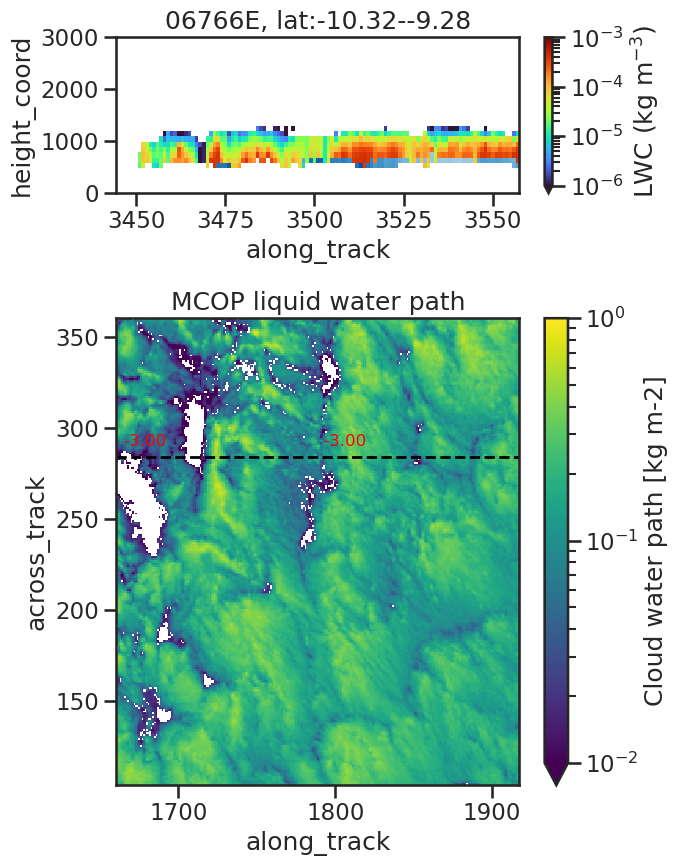

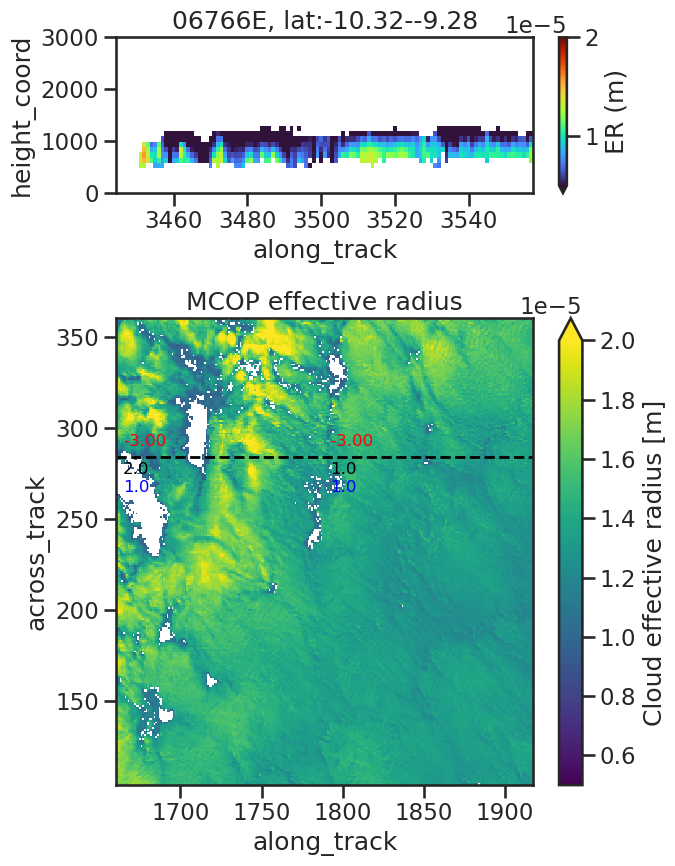

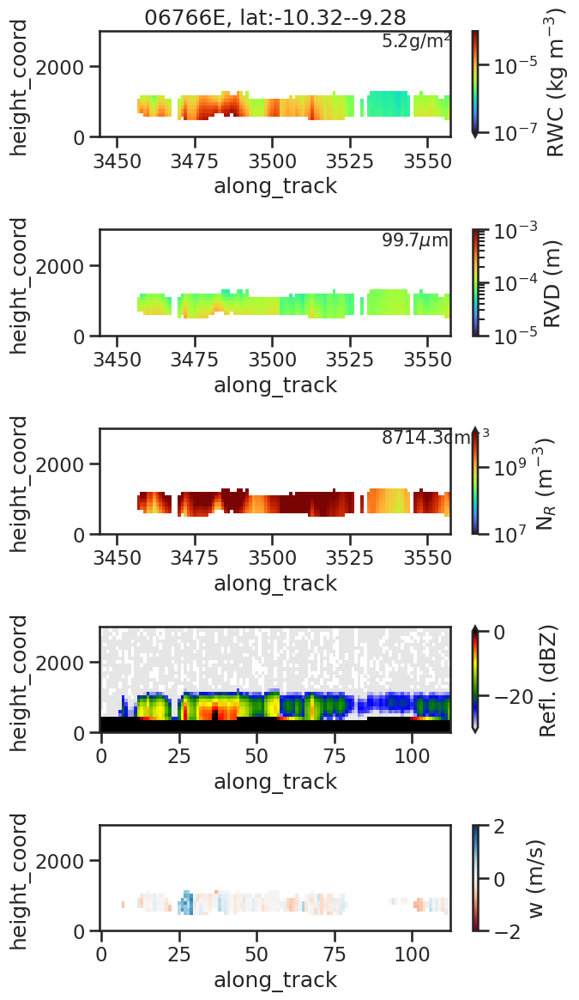

Selecting frame from 5 to 4873
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/07/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/07/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E.h5
Orbit: 06299E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/07/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_062

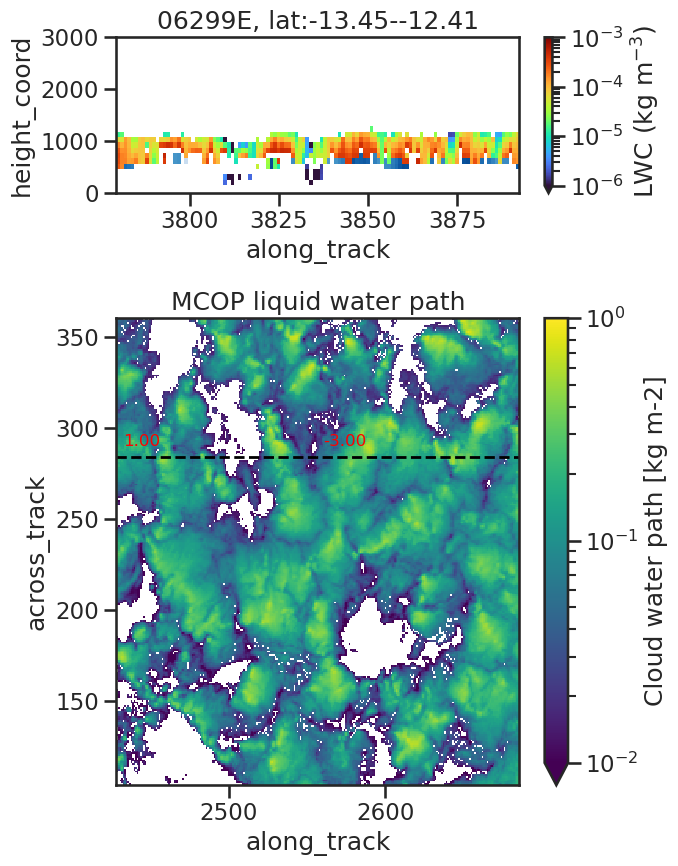

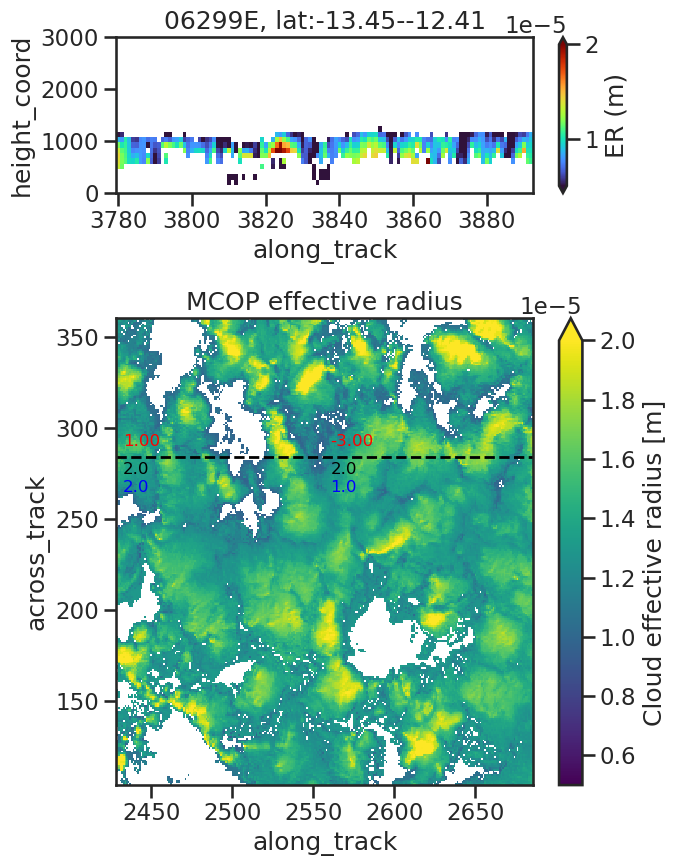

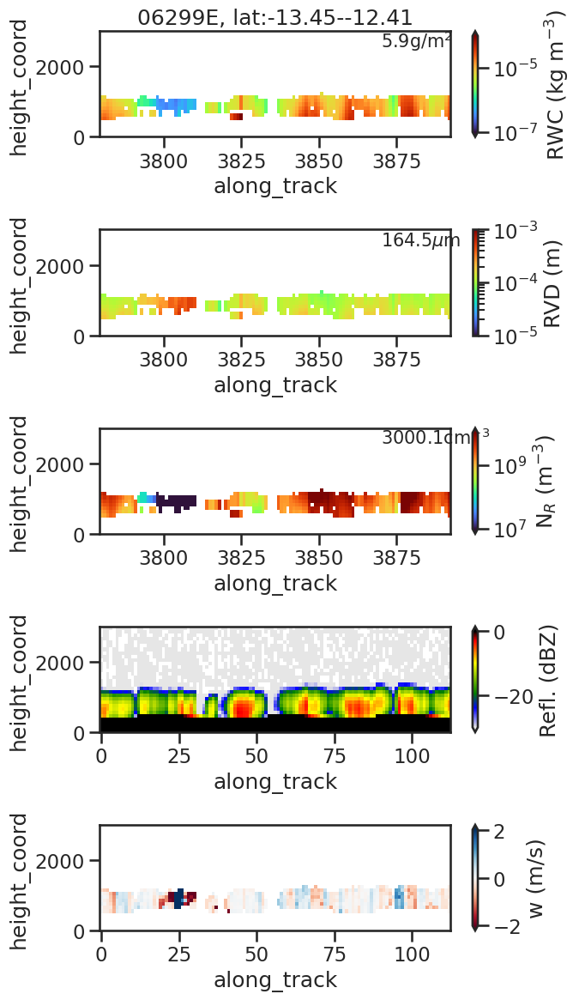

Selecting frame from 7 to 4875
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/21/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/21/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E.h5
Orbit: 06517E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/21/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_065

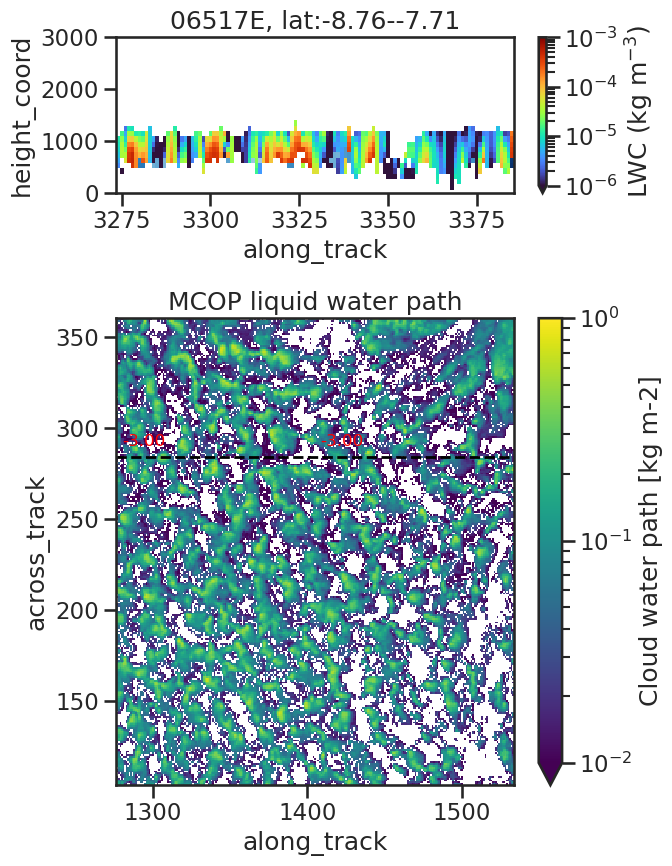

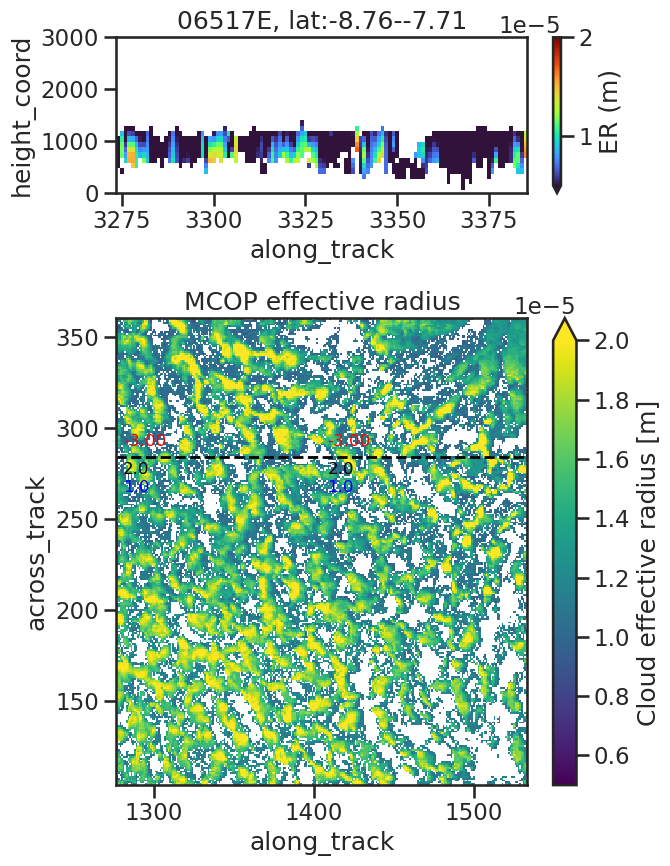

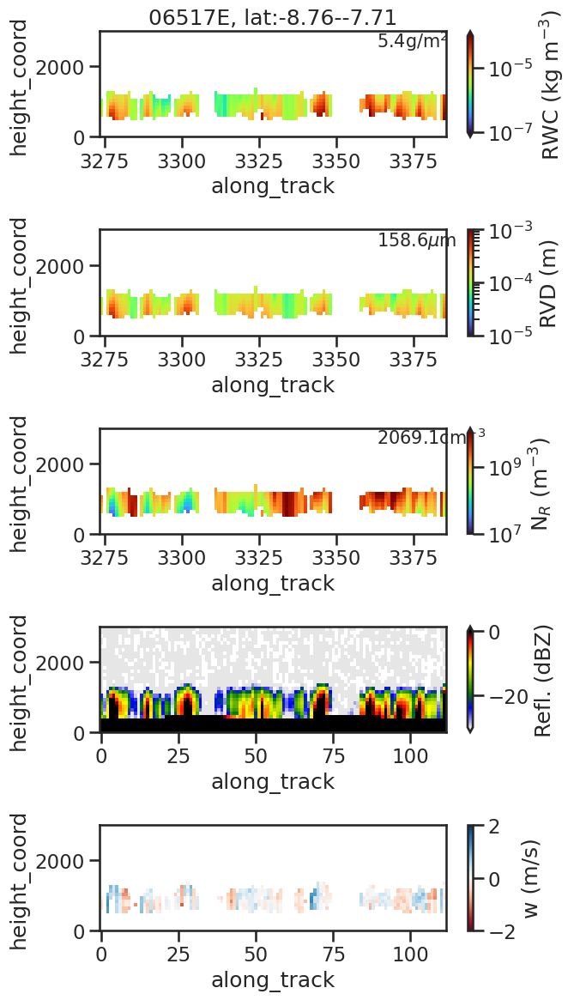

------------------ 13h before transition ------------------
Selecting frame from 6 to 4874
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/28/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/28/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E.h5
Orbit: 06159E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/28/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_0615

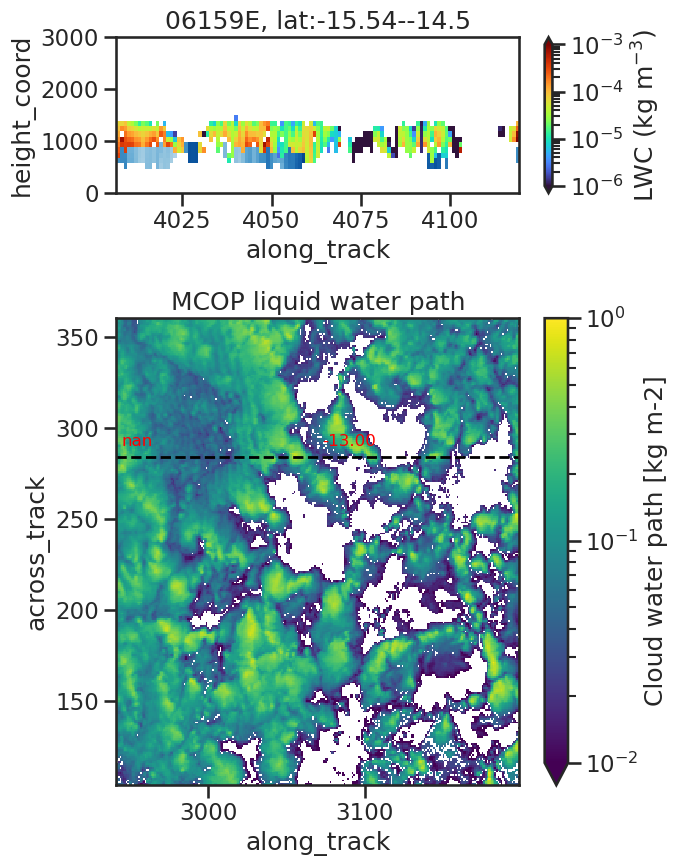

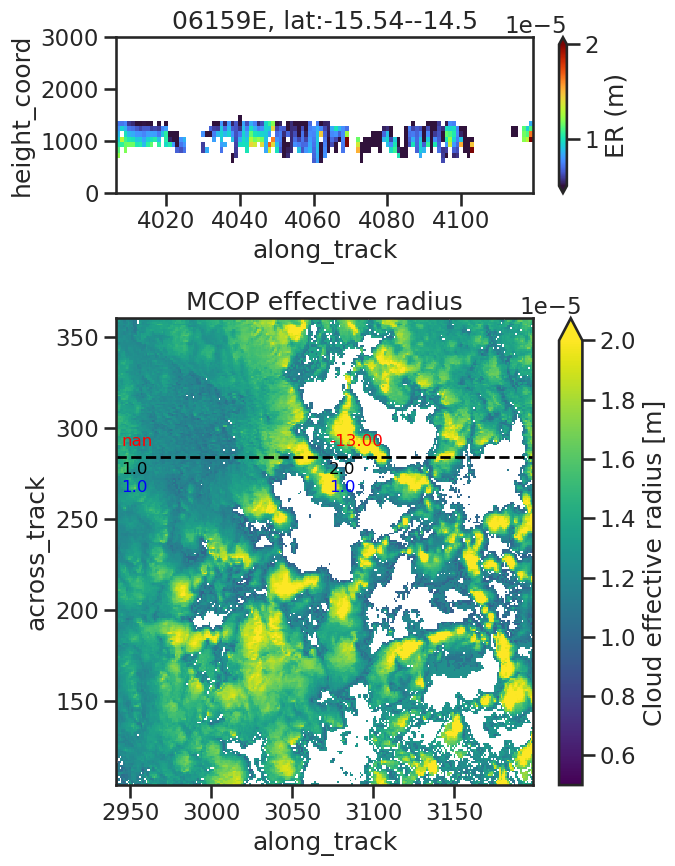

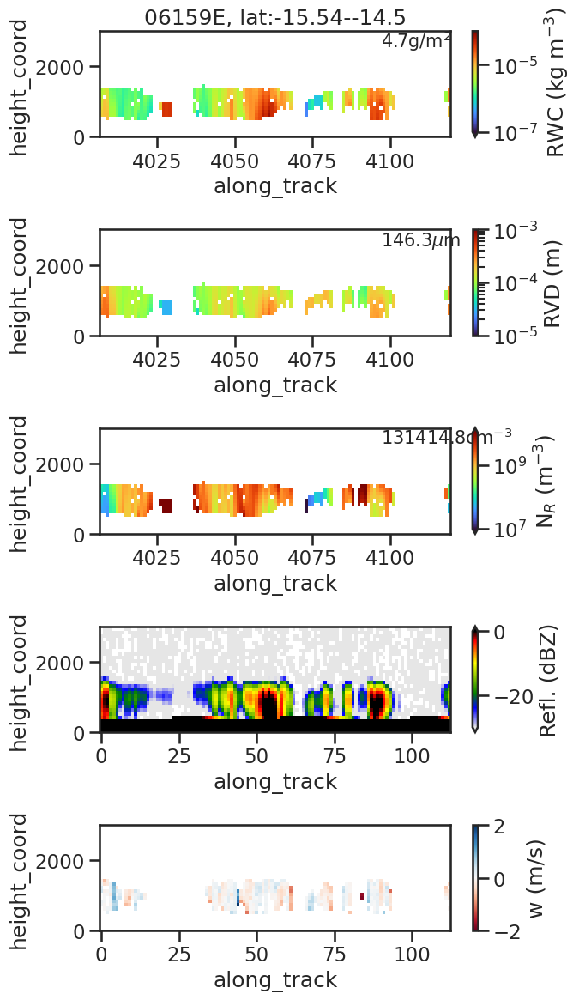

Selecting frame from 7 to 4876
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/11/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/11/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E.h5
Orbit: 06361E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/11/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_063

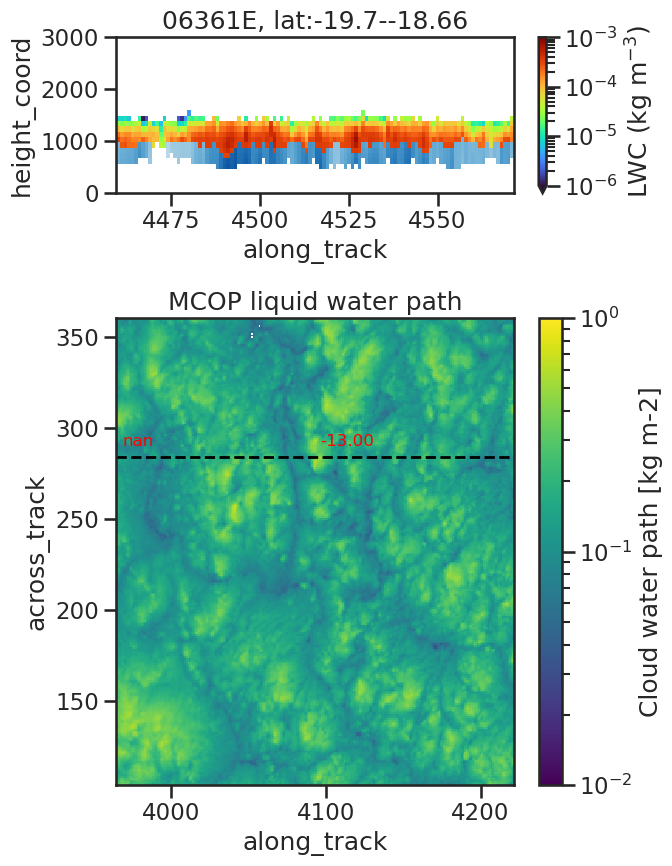

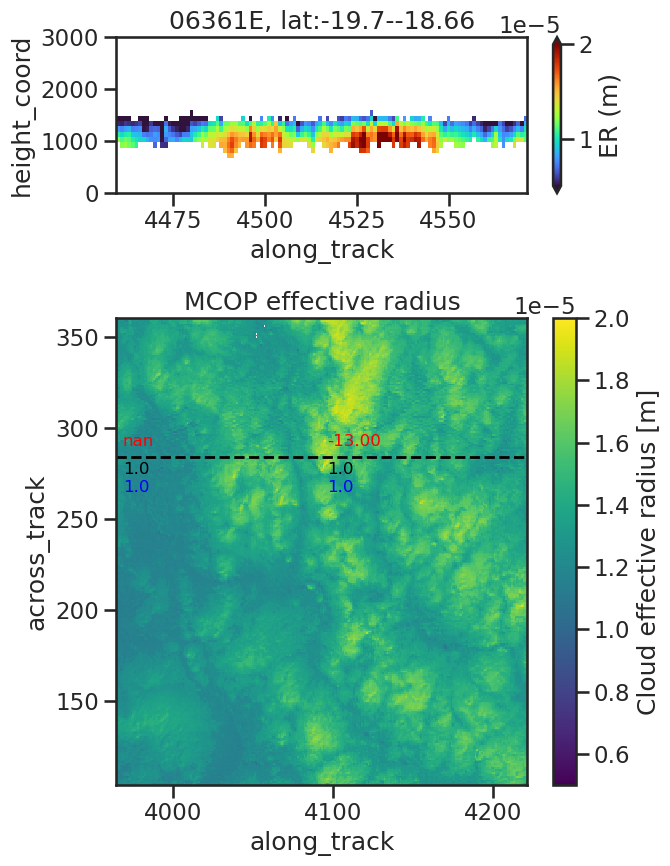

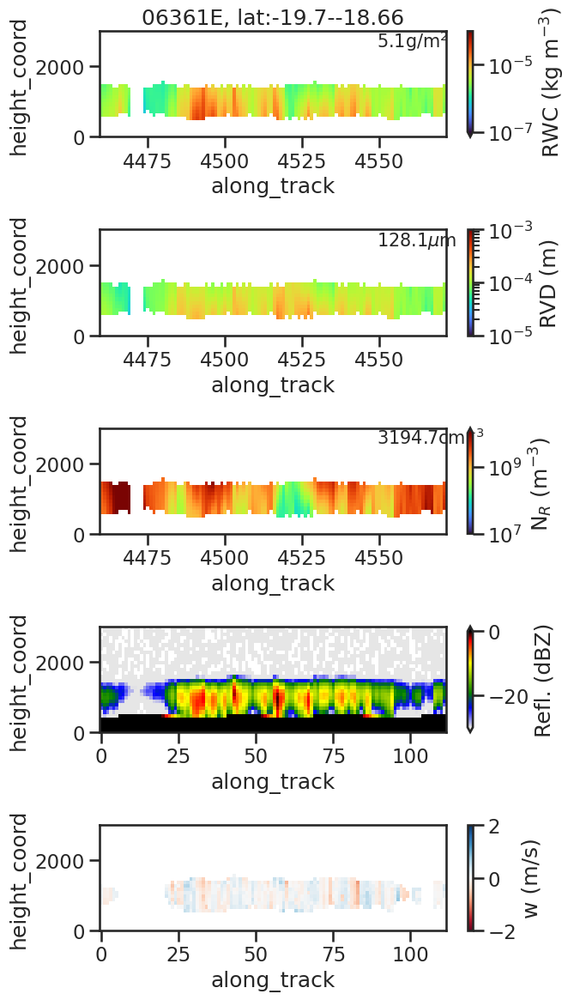

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/21/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/21/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E.h5
Orbit: 06050E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/21/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_060

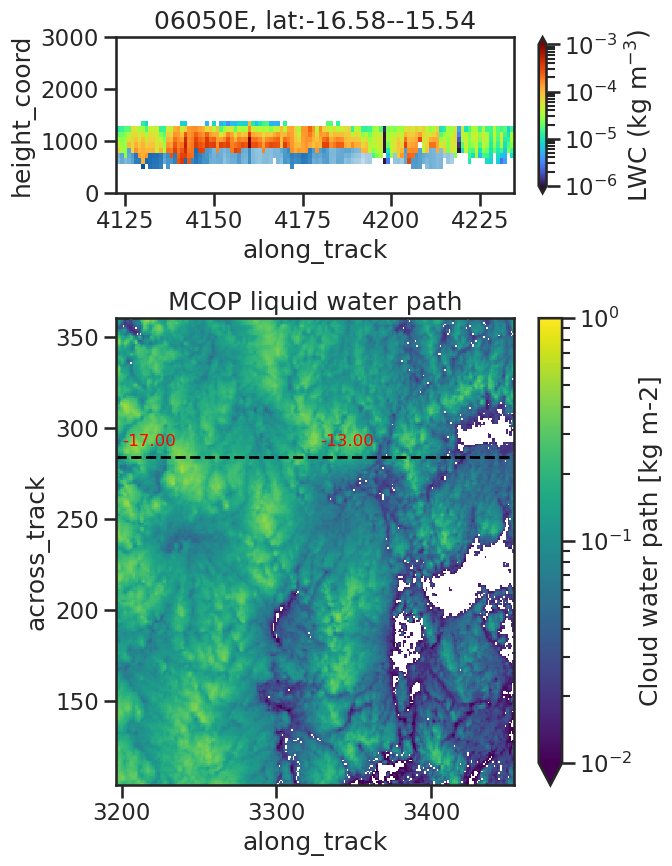

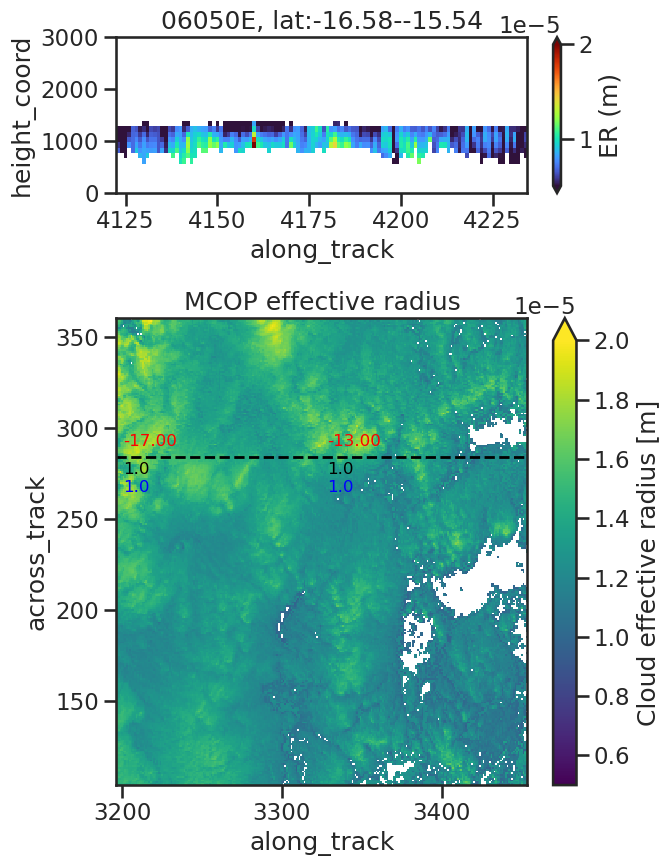

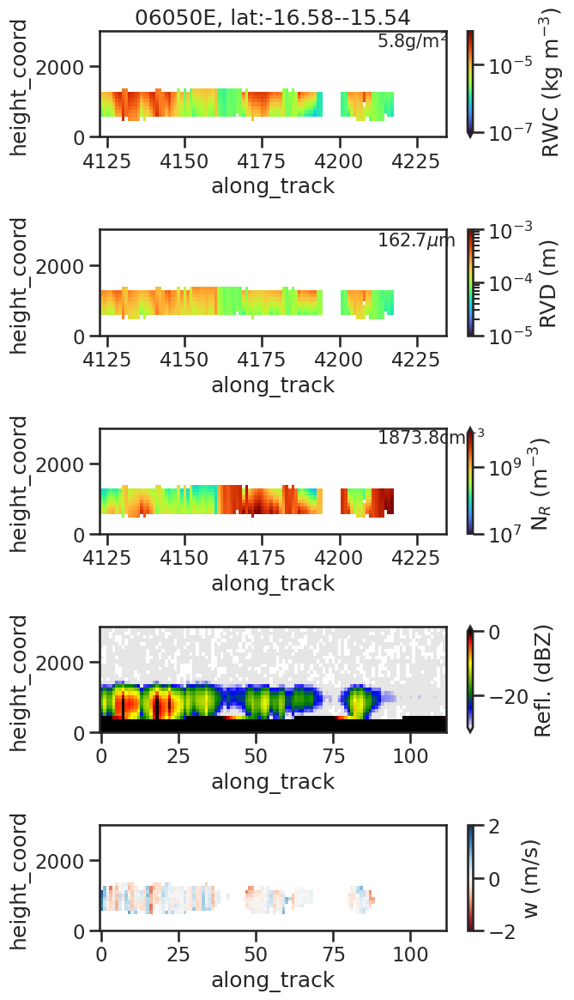

------------------ 23h before transition ------------------
Selecting frame from 7 to 4879
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/05/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/05/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E.h5
Orbit: 01071E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/05/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_0107

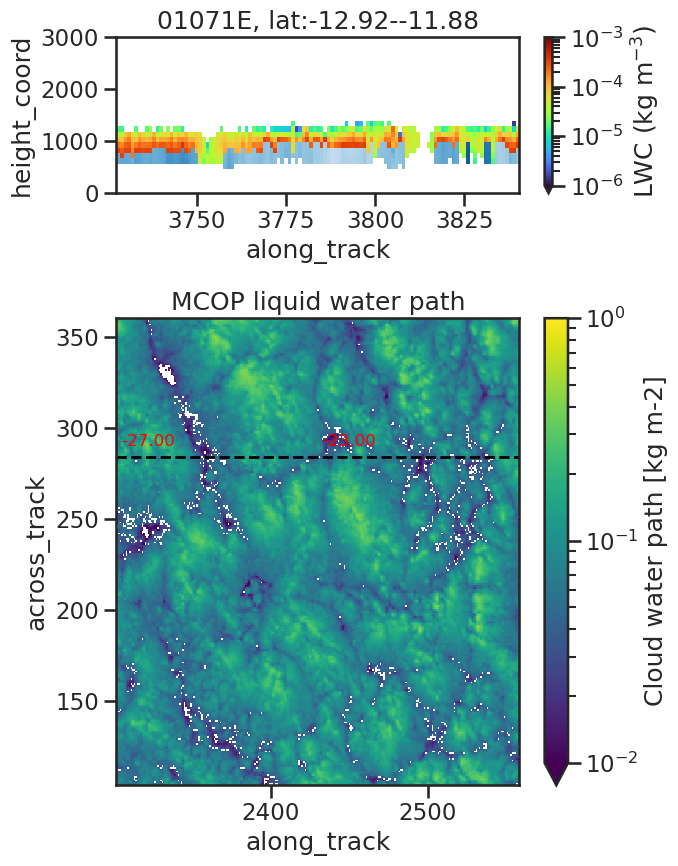

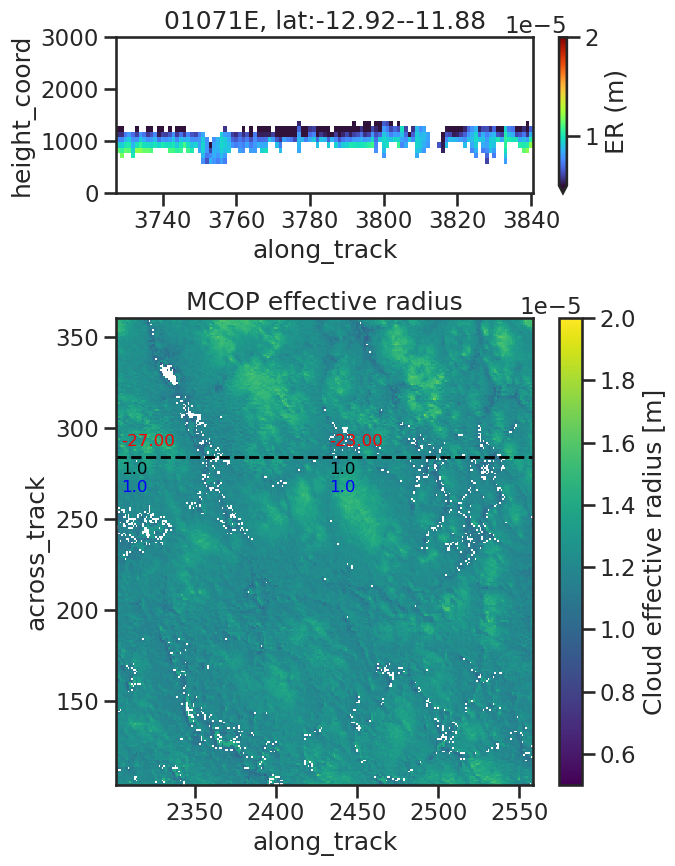

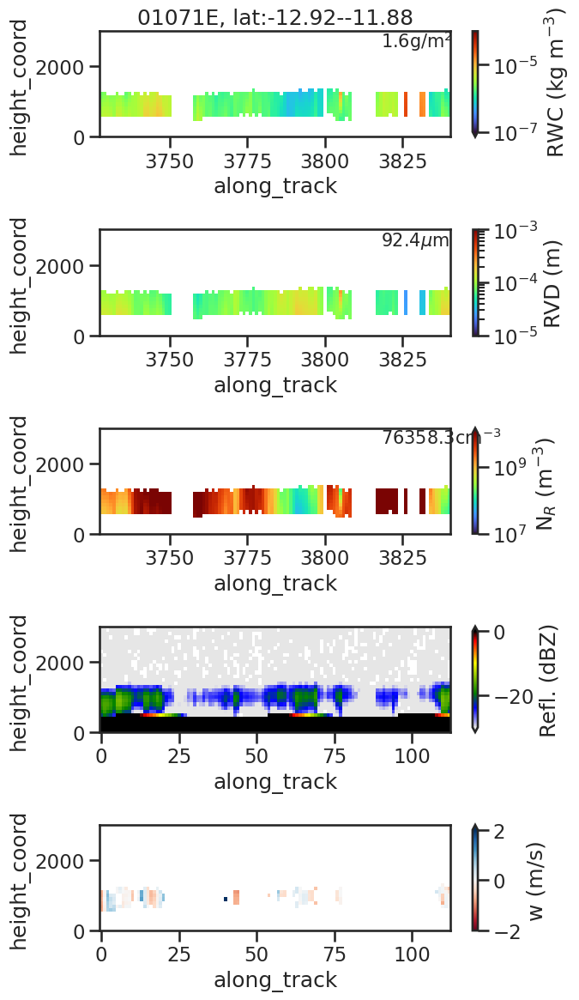

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/10/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/10/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E.h5
Orbit: 06828E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/10/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_068

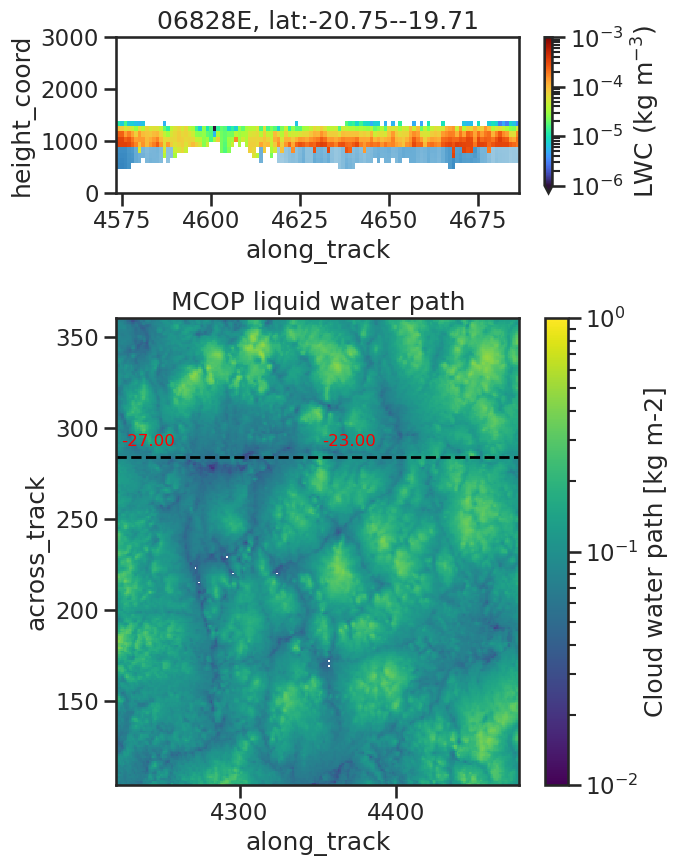

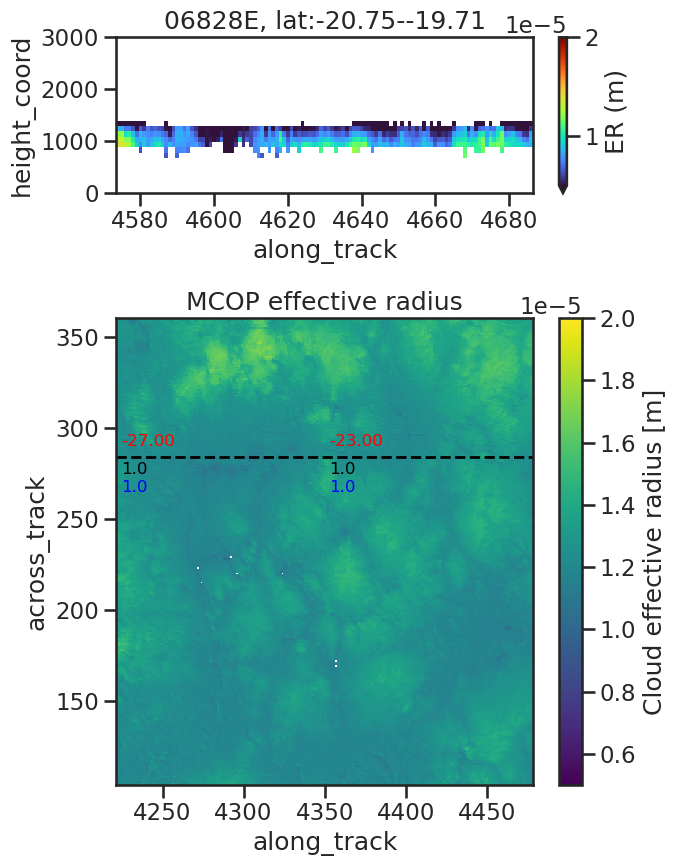

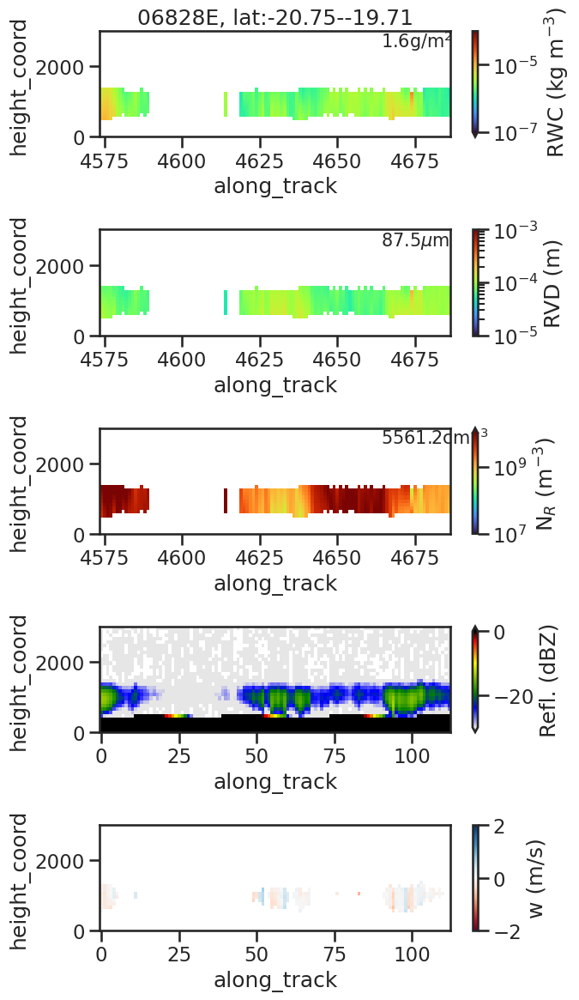

Selecting frame from 7 to 4875
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/26/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/26/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E.h5
Orbit: 07077E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/26/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_070

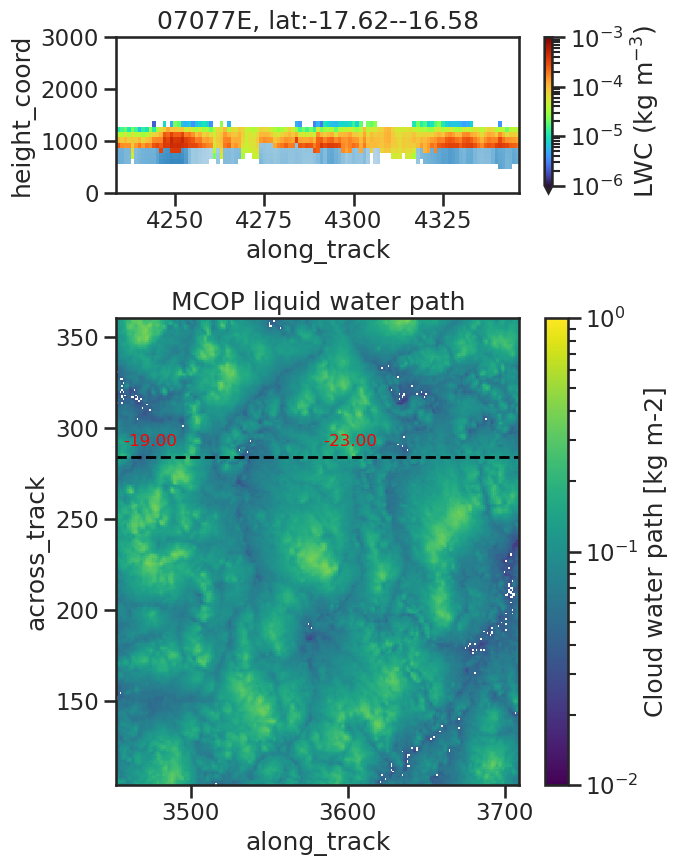

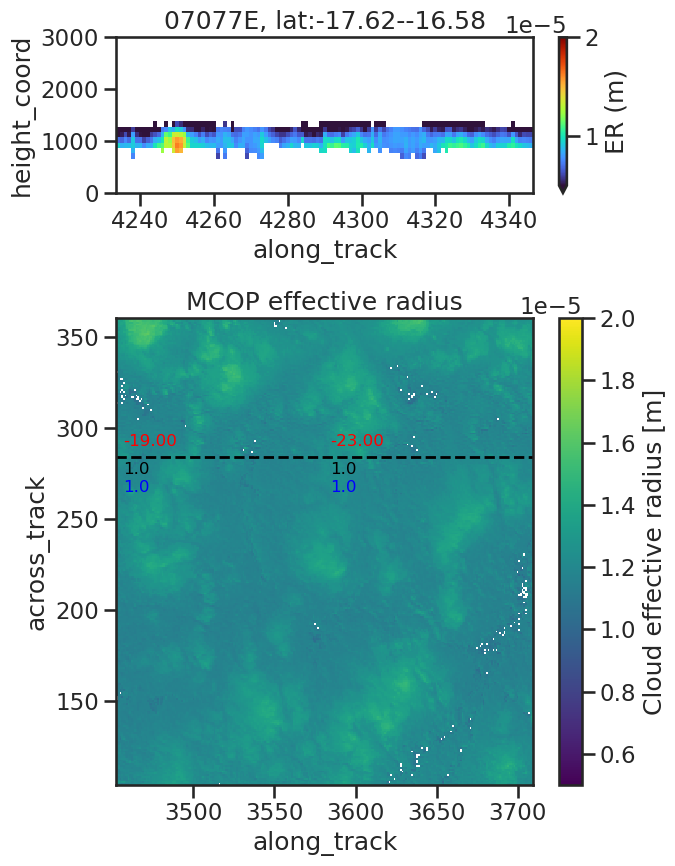

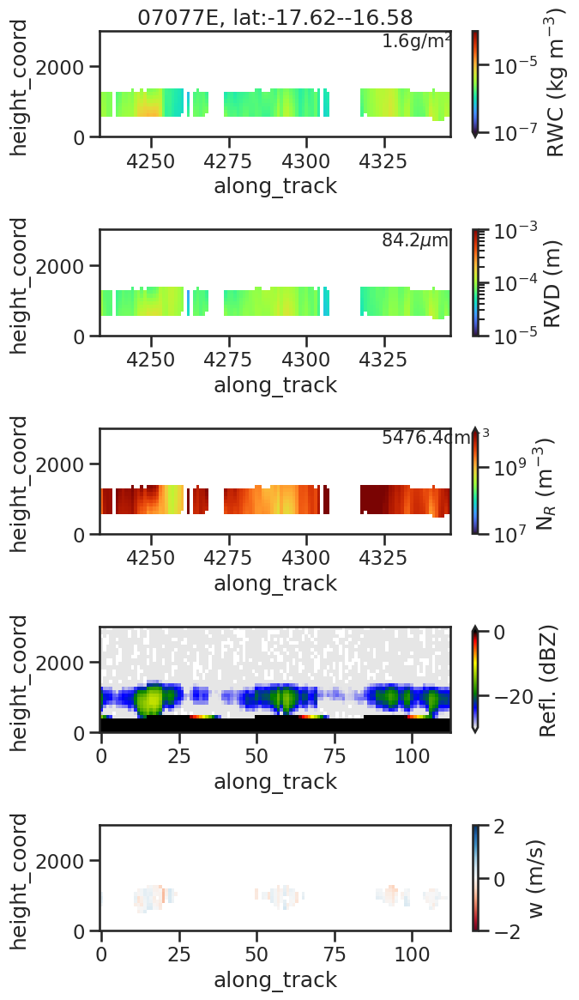

In [212]:
print('------------------ 3h before transition ------------------')
ds_3h_before_trans['rwp_diff_to_median'] = np.abs(ds_3h_before_trans['rwp'].median() - ds_3h_before_trans['rwp'])
ds_3h_before_trans = ds_3h_before_trans.sortby('rwp_diff_to_median')
for i in range(3):
    ds_3h_before_trans_i = ds_3h_before_trans.isel(time_startpoint=i)
    plot_ACMCAP_MCOP_for_orbit(str(ds_3h_before_trans_i['orbit'].values), ds_3h_before_trans_i['lat_min'].values, ds_3h_before_trans_i['lat_max'].values)

print('------------------ 13h before transition ------------------')
ds_13h_before_trans['rwp_diff_to_median'] = np.abs(ds_13h_before_trans['rwp'].median() - ds_13h_before_trans['rwp'])
ds_13h_before_trans = ds_13h_before_trans.sortby('rwp_diff_to_median')
for i in range(3):
    ds_13h_before_trans_i = ds_13h_before_trans.isel(time_startpoint=i)
    plot_ACMCAP_MCOP_for_orbit(str(ds_13h_before_trans_i['orbit'].values), ds_13h_before_trans_i['lat_min'].values, ds_13h_before_trans_i['lat_max'].values)

print('------------------ 23h before transition ------------------')
ds_23h_before_trans['rwp_diff_to_median'] = np.abs(ds_23h_before_trans['rwp'].median() - ds_23h_before_trans['rwp'])
ds_23h_before_trans = ds_23h_before_trans.sortby('rwp_diff_to_median')
for i in range(3):
    ds_23h_before_trans_i = ds_23h_before_trans.isel(time_startpoint=i)
    plot_ACMCAP_MCOP_for_orbit(str(ds_23h_before_trans_i['orbit'].values), ds_23h_before_trans_i['lat_min'].values, ds_23h_before_trans_i['lat_max'].values)

In [26]:
ds_at_transition = bt_co_concat.where(np.abs(bt_co_concat.transition_time_diff) <= 1, drop=True)

# look for low LWP clouds at transition - what is going on here?
ds_at_transition = ds_at_transition.where((ds_at_transition.cats == 1), drop=True)
np.unique(ds_at_transition.orbit.values)

array(['01351E', '01460E', '05630E', '05708E', '06019E', '06439E',
       '06517E', '06766E', '06906E', '07046E', '07373E'], dtype=object)

In [46]:
ds_before_transition = bt_co_concat.where((bt_co_concat.transition_time_diff <= -20) & (bt_co_concat.transition_time_diff >= -24), drop=True)
np.unique(ds_before_transition.orbit.values)

array(['01009E', '01071E', '01211E', '01242E', '01351E', '01382E',
       '01553E', '01631E', '01709E', '01740E', '01833E', '01942E',
       '02160E', '02238E', '02409E', '06268E', '06408E', '06470E',
       '06517E', '06766E', '06828E', '07077E', '07108E', '07155E',
       '07279E', '07326E', '07637E'], dtype=object)

In [55]:
non_trans_high_rwp = bt_non_trans_c.where(bt_non_trans_c.rwp > 3e-3, drop=True)
np.unique(non_trans_high_rwp.orbit.values)

array(['01102E', '01942E', '06190E', '06268E', '06408E', '06548E',
       '06579E', '06766E', '06828E', '07933E'], dtype=object)

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/12/20/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/12/20/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E.h5
Orbit: 03203E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/12/20/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_032

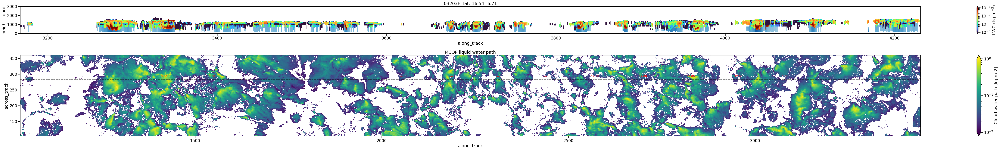

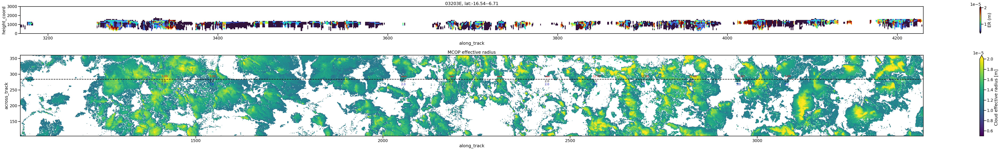

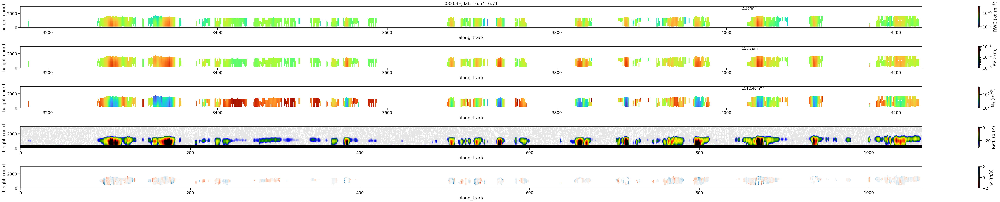

In [ ]:
orbit = '03203E'
ds_orbit = bt_co_concat.where(bt_co_concat.orbit == orbit, drop=True)
lat_min = ds_orbit.lat_min.min().values
lat_max = ds_orbit.lat_max.max().values
plot_ACMCAP_MCOP_for_orbit(orbit, lat_min - 1, lat_max + 1)

In [27]:
for i,orbit in enumerate(np.unique(ds_before_transition.orbit.values)[:5]):
    ds_before_transition_orbit = ds_before_transition.where(ds_before_transition.orbit == orbit, drop=True)
    lat_min = ds_before_transition_orbit.lat_min.min().values
    lat_max = ds_before_transition_orbit.lat_max.max().values
    plot_ACMCAP_MCOP_for_orbit(orbit, lat_min - 1, lat_max + 1)
    if i >= 5:
        break

NameError: name 'ds_before_transition' is not defined

In [27]:
9.81 * 2.5e6 / (1.2 * 800 * 1004 * 300) *1e2 * 3600

30534.113545816734

In [ ]:
for i,orbit in enumerate(np.unique(non_trans_high_rwp.orbit.values)):
    non_trans_high_rwp_orbit = non_trans_high_rwp.where(non_trans_high_rwp.orbit == orbit, drop=True)
    lat_min = non_trans_high_rwp_orbit.lat_min.min().values
    lat_max = non_trans_high_rwp_orbit.lat_max.max().values
    plot_ACMCAP_MCOP_for_orbit(orbit, lat_min - 1, lat_max + 1)
    if i >= 5:
        break

Selecting frame from 8 to 4873
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E.h5
Orbit: 01351E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_013

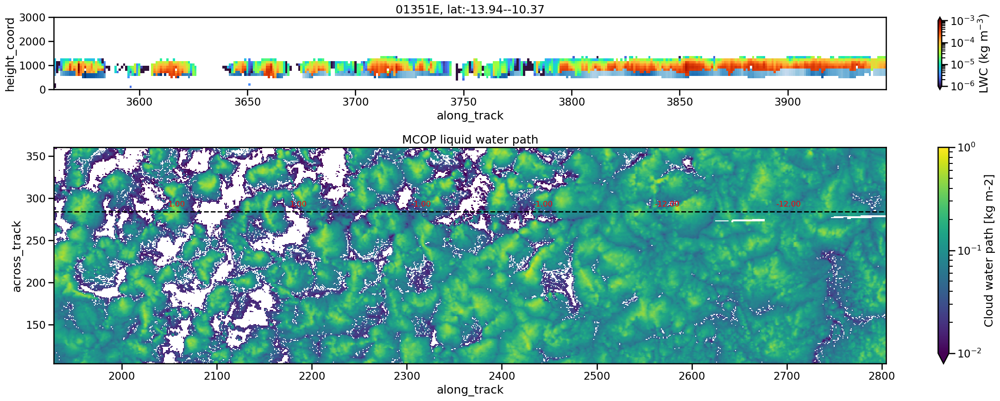

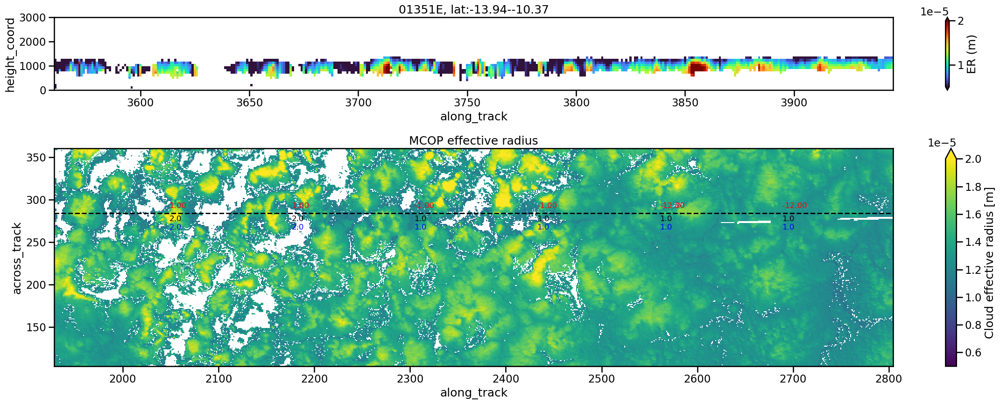

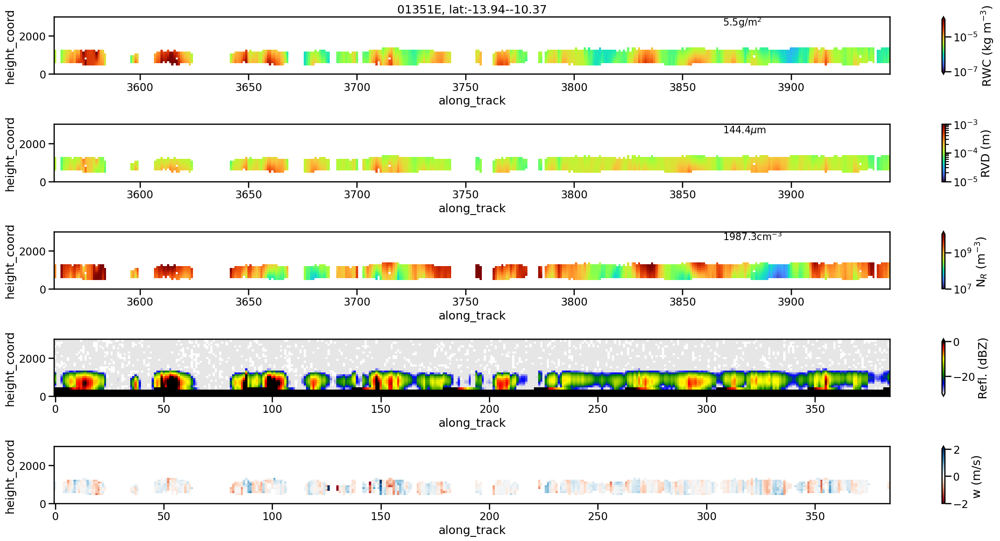

Selecting frame from 9 to 4873
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/30/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/30/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E.h5
Orbit: 01460E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/30/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_014

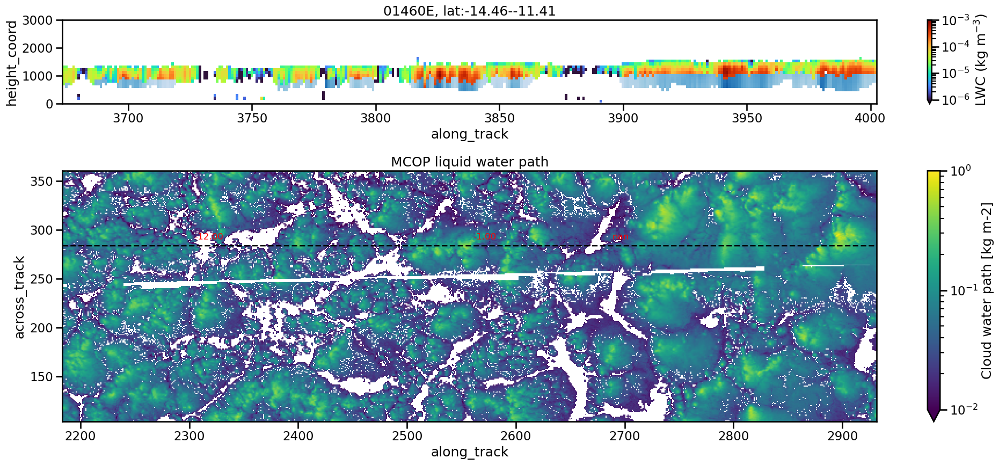

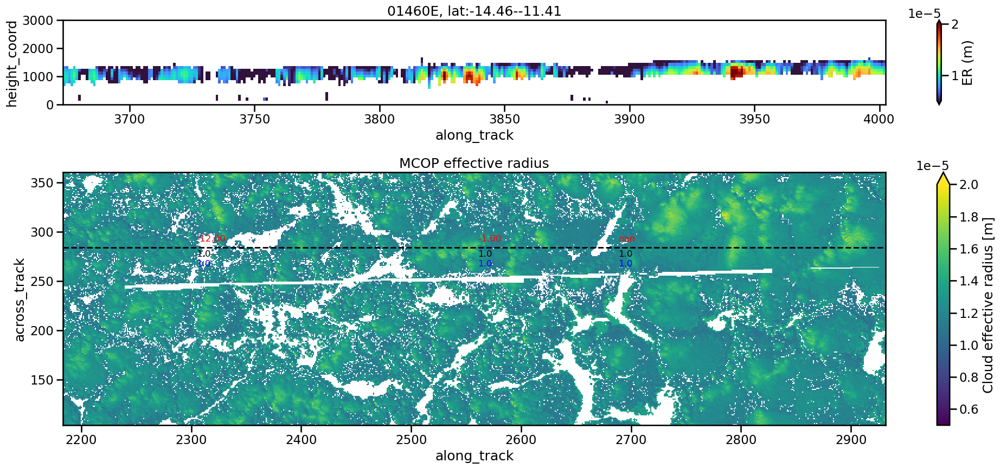

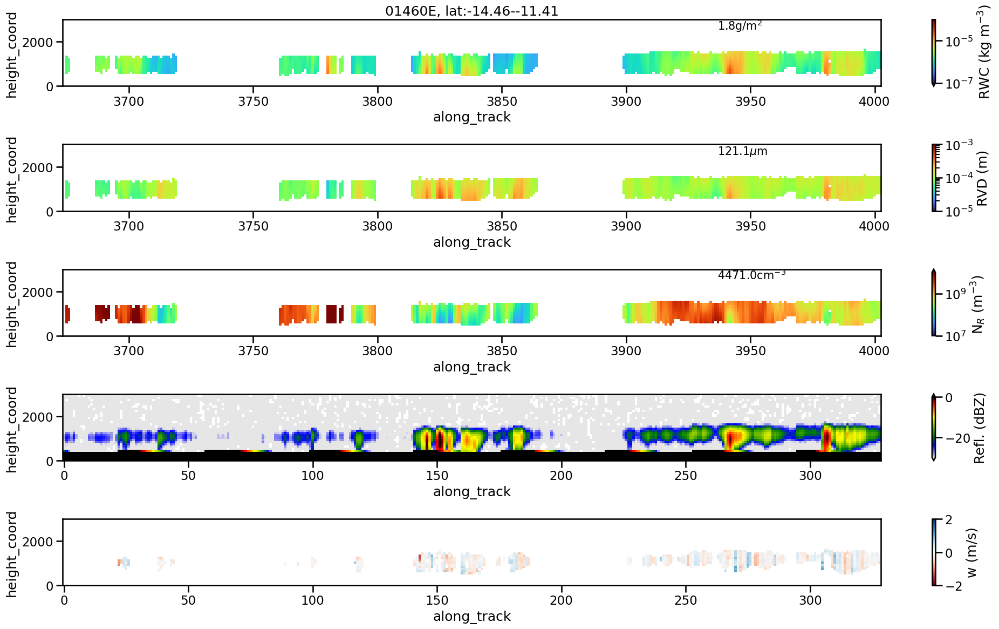

Selecting frame from 9 to 4876
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/25/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/25/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E.h5
Orbit: 05630E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/25/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_056

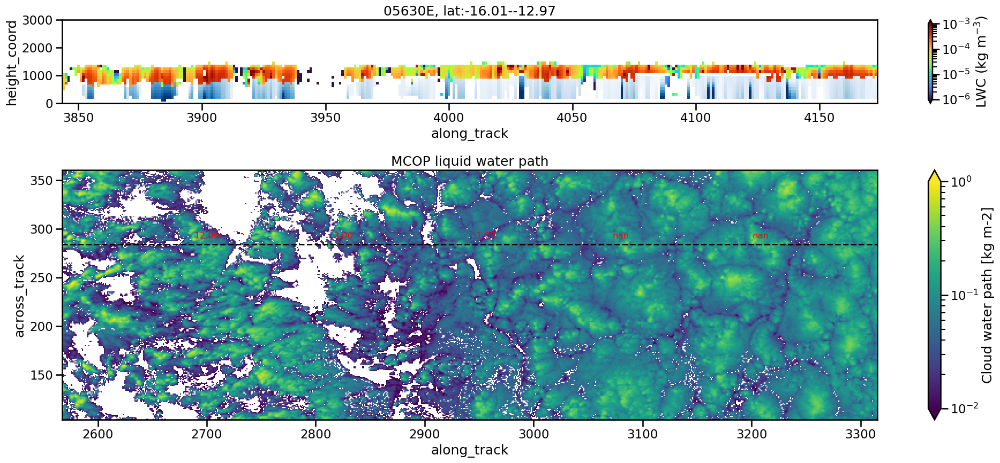

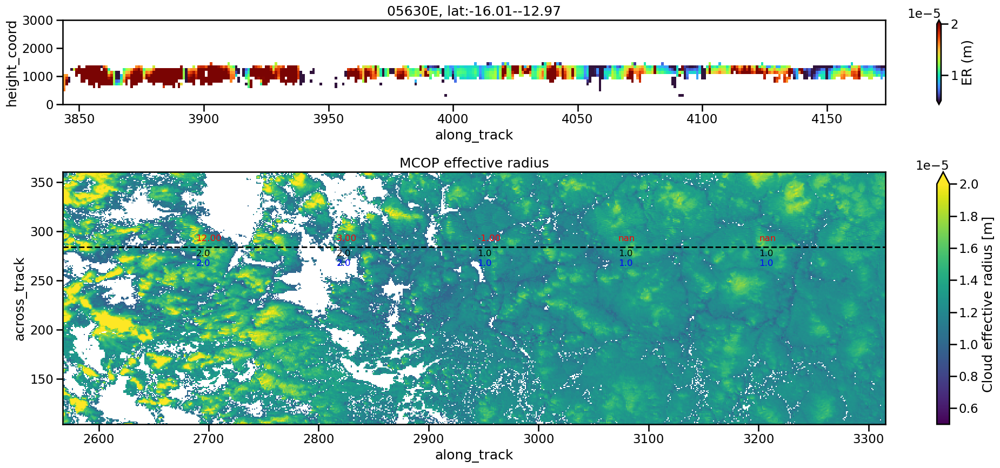

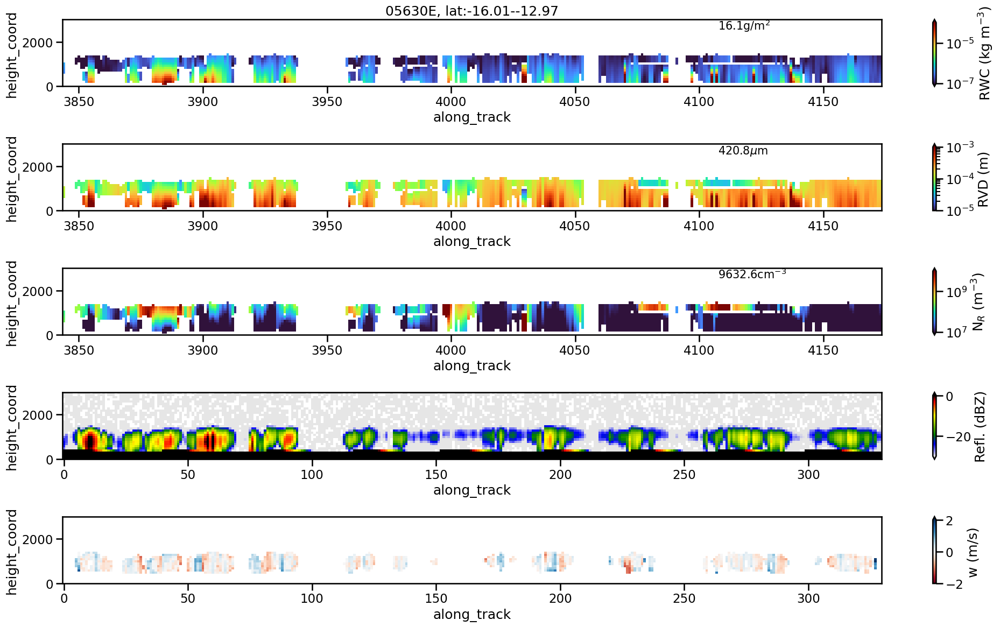

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/30/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/30/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E.h5
Orbit: 05708E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/30/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_057

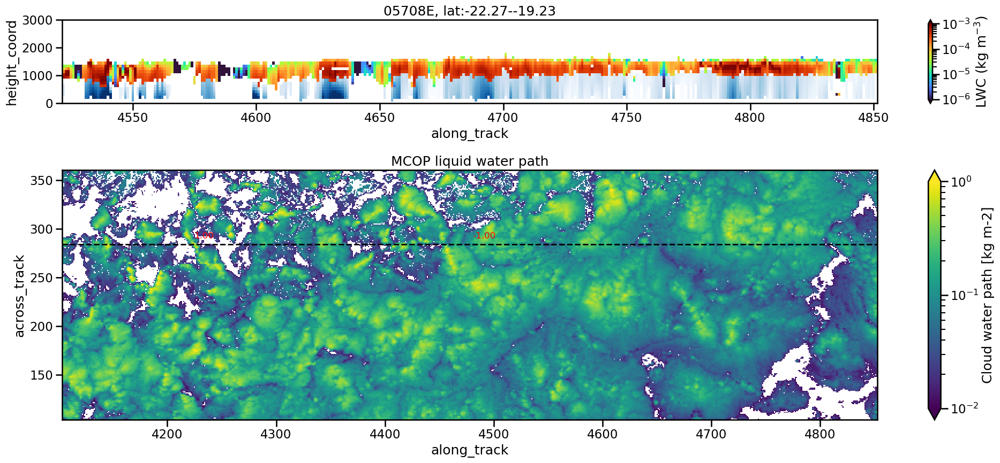

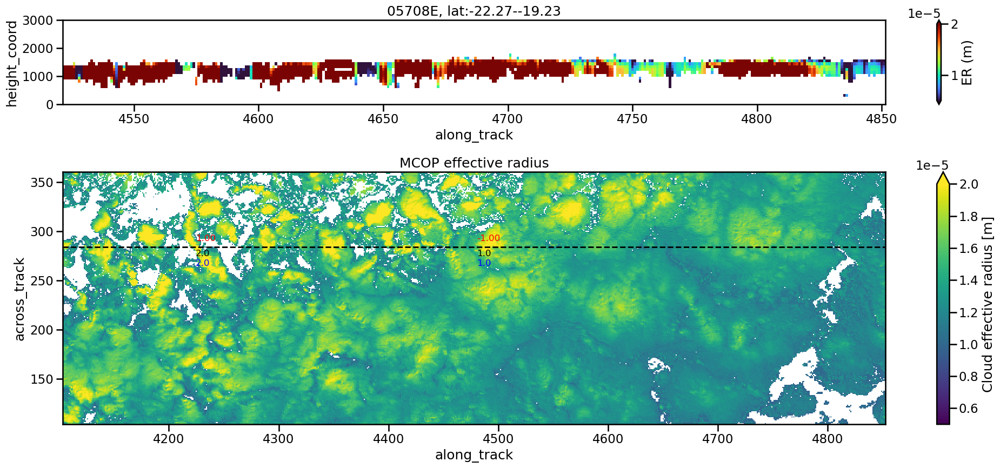

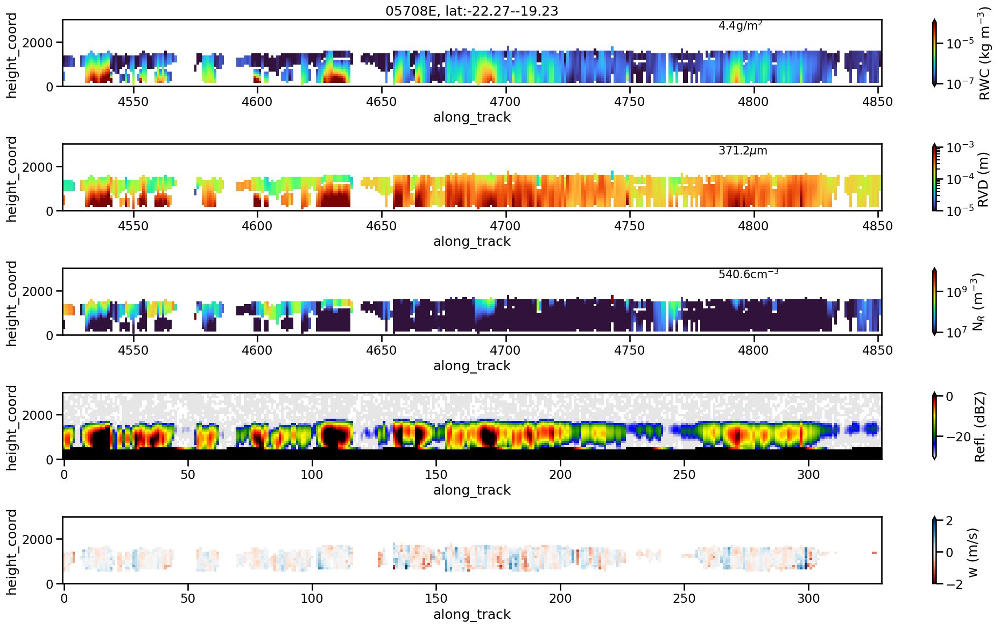

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E.h5
Orbit: 06019E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_060

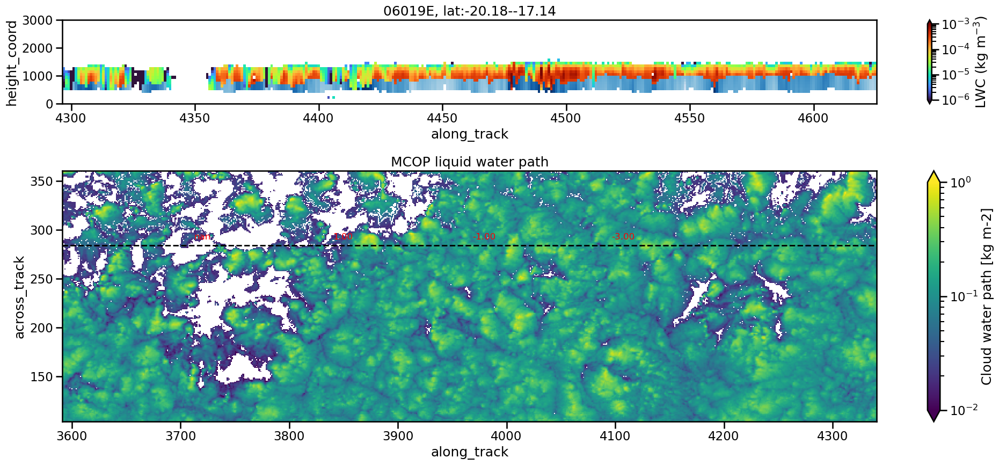

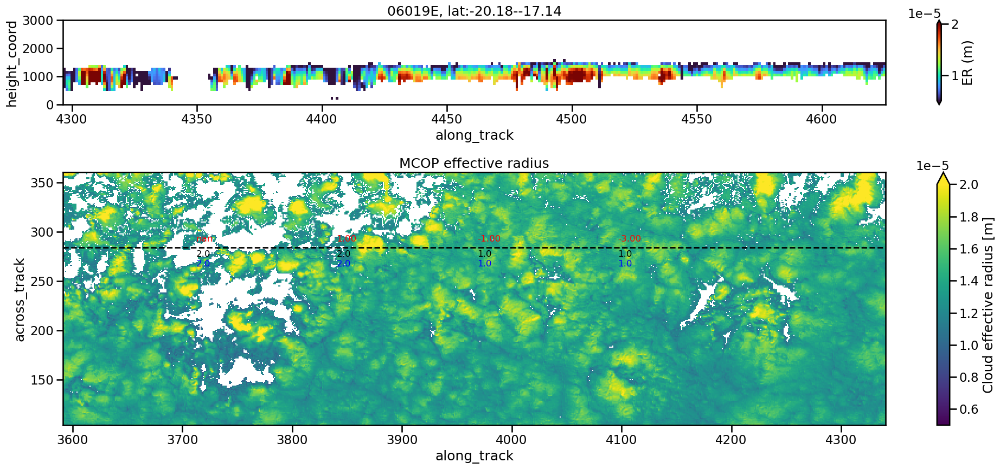

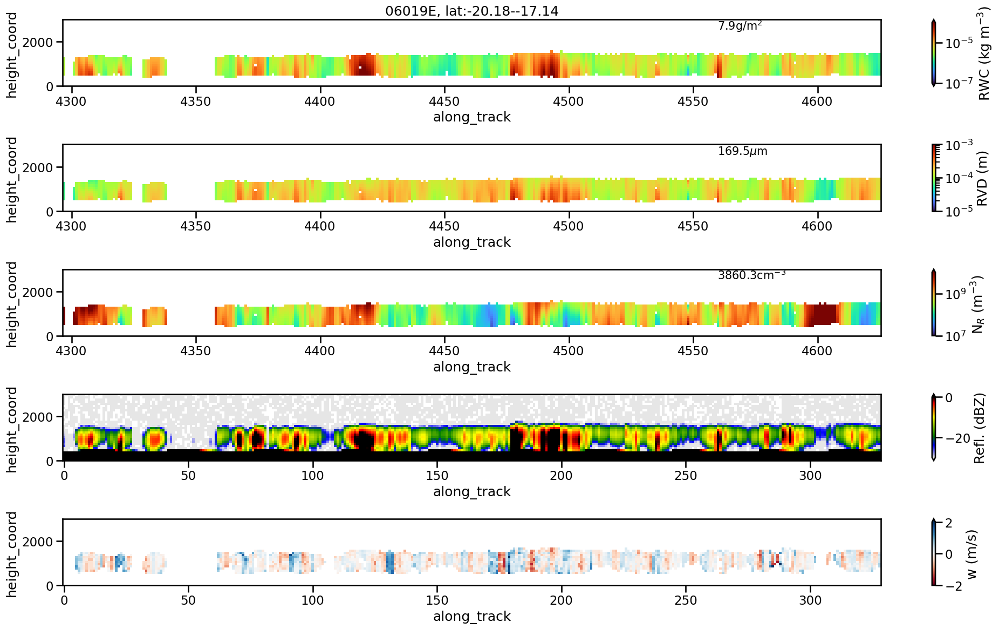

In [35]:
for i,orbit in enumerate(np.unique(ds_at_transition.orbit.values)[:5]):
    ds_at_transition_orbit = ds_at_transition.where(ds_at_transition.orbit == orbit, drop=True)
    lat_min = ds_at_transition_orbit.lat_min.min().values
    lat_max = ds_at_transition_orbit.lat_max.max().values
    plot_ACMCAP_MCOP_for_orbit(orbit, lat_min - 1, lat_max + 1)
    if i >= 5:
        break

In [42]:
bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.orbit=='05848E'), drop=True)[['orbit','transition_time_diff','rwp','lwp','rwp_perc75','lat_mid']]

<xarray.Dataset> Size: 224B
Dimensions:               (time_startpoint: 4)
Coordinates:
  * time_startpoint       (time_startpoint) datetime64[ns] 32B 2025-06-08T19:...
    orbit                 (time_startpoint) object 32B '05848E' ... '05848E'
Data variables:
    transition_time_diff  (time_startpoint) float64 32B -1.0 -1.0 -1.0 -1.0
    rwp                   (time_startpoint) float64 32B 0.001482 ... 0.000259
    lwp                   (time_startpoint) float64 32B 0.03345 ... 0.01852
    rwp_perc75            (time_startpoint) float64 32B 0.0 0.0 0.0 0.0
    lat_mid               (time_startpoint) float64 32B -6.193 -7.237 ... -9.325

In [119]:
bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.transition_time_diff < 30) & (bt_co_concat.lat_mid < -20), drop=True)[['orbit','transition_time_diff','rwp','lwp','rwp_perc75','lat_mid']]

<xarray.Dataset> Size: 4kB
Dimensions:               (time_startpoint: 78)
Coordinates:
  * time_startpoint       (time_startpoint) datetime64[ns] 624B 2024-08-07T19...
    orbit                 (time_startpoint) object 624B '01102E' ... '07793E'
Data variables:
    transition_time_diff  (time_startpoint) float64 624B -3.0 -3.0 ... 3.0 12.0
    rwp                   (time_startpoint) float64 624B 0.002659 ... 0.009056
    lwp                   (time_startpoint) float64 624B 0.07601 ... 0.009783
    rwp_perc75            (time_startpoint) float64 624B 0.003181 ... 0.005266
    lat_mid               (time_startpoint) float64 624B -20.26 ... -20.79

##### example for publication

In [49]:
bt_example = bt_co_concat.where((bt_co_concat.orbit == '06019E') & (bt_co_concat.lat_min >= -19.18-1) & (bt_co_concat.lat_max <= -18.14+1.5), drop=True)

In [60]:
bt_example = bt_example.sortby('transition_time_diff')

In [61]:
bt_example[['lat_min', 'lat_max', 'lat_mid', 'transition_time_diff', 'cats']]

<xarray.Dataset> Size: 224B
Dimensions:               (time_startpoint: 4)
Coordinates:
  * time_startpoint       (time_startpoint) datetime64[ns] 32B 2025-06-19T19:...
    orbit                 (time_startpoint) object 32B '06019E' ... '06019E'
Data variables:
    lat_min               (time_startpoint) float64 32B -19.7 -19.18 ... -18.14
    lat_max               (time_startpoint) float64 32B -18.66 -18.14 ... -17.1
    lat_mid               (time_startpoint) float64 32B -19.23 -18.71 ... -17.67
    transition_time_diff  (time_startpoint) float64 32B -3.0 -1.0 1.0 nan
    cats                  (time_startpoint) float64 32B 1.0 1.0 2.0 2.0

In [51]:
orbit = '06019E'
lat_min = bt_example.lat_min.min().values
lat_max = bt_example.lat_max.max().values
lat_min, lat_max

(array(-19.70404768), array(-17.10013199))

In [52]:


sys.path.append('./../../../ectools/')
from ectools import ecio
from ectools import colormaps
sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_msi/')
import access_ec_on_maap as maap
#from importlib import reload
#reload(maap)

dfscene = bt_co_concat.where((bt_co_concat.orbit == orbit) & (bt_co_concat.lat_mid >= lat_min) & (bt_co_concat.lat_mid <= lat_max), drop=True)
time_startpoint = dfscene.time_startpoint.values[0]
year = pd.to_datetime(time_startpoint).year
month = pd.to_datetime(time_startpoint).month
day = pd.to_datetime(time_startpoint).day
region = 'SEP'
transition_params=dfscene[['transition_time_diff','along_track_mid','cats','goes_cats','scene_id']].sel(timestep=0).groupby('scene_id').mean()

# load ACMCAP
try:
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/{year}/{month:02d}/{day:02d}/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
except IndexError:
    ACMCAP_list = maap.get_acmcap_via_maap(
                        frame=orbit[-1],
                        orbitNumber=orbit[:-1],
                        max_items=1,
                        )
    ACMCAP = ACMCAP_list[0][0]

encoding = ACMCAP.encoding
ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
ACMCAP.encoding = encoding.copy()
ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})

# load MCOP
MCOP_list = maap.get_mcop_via_maap(
        region=region, 
        frame=orbit[-1],
        orbitNumber=orbit[:-1],
        mcop_variables=['time', 'latitude', 'longitude', 'cloud_optical_thickness', 'cloud_water_path','cloud_effective_radius'], 
        max_items=1)
    
MCOP, _ = MCOP_list[0]

MCOP = MCOP.assign_coords(
    {
    'along_track': (
        ["along_track"],
        MCOP['along_track'].data,
        MCOP['along_track'].attrs
        ),
    'across_track': (
        ['across_track'],
        MCOP['across_track'].data,
        MCOP['across_track'].attrs
        )
    })
along_track_min = np.abs(MCOP.sel(across_track=284).latitude - lat_min).argmin()
along_track_max = np.abs(MCOP.sel(across_track=284).latitude - lat_max).argmin()
MCOP2 = MCOP.sel(along_track=slice(MCOP.along_track[along_track_max], MCOP.along_track[along_track_min]))
MCOP2 = MCOP2.sel(across_track=slice(360 - 256, 360))

# load C-FMR
CFMR_list = maap.get_cfmr_via_maap(
                    frame=orbit[-1],
                    orbitNumber=orbit[:-1],
                    max_items=1,
                    )
CFMR = CFMR_list[0][0]
CFMR = CFMR.where((CFMR.latitude > lat_min) & (CFMR.latitude < lat_max), drop=True)
CFMR = CFMR.assign_coords(height_coord=("CPR_height", CFMR.height.isel(along_track=0).data))
CFMR = CFMR.swap_dims({'CPR_height': 'height_coord'})
CFMR = CFMR.where(CFMR.height_coord > -500, drop=True)

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E.h5
Orbit: 06019E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_060

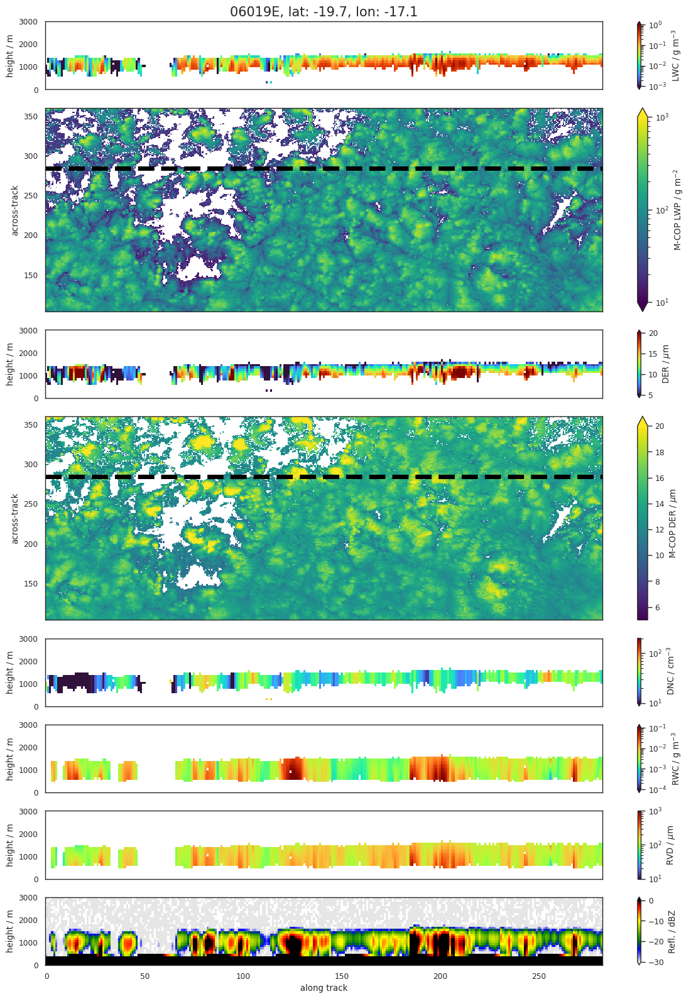

In [98]:
# plot
sns.set_context('paper')
#sns.set_style('white')

import matplotlib.gridspec as gridspec

fig, axs = plt.subplots(figsize=(12, 16), nrows=8, ncols=1, gridspec_kw={'height_ratios': [1, 3, 1, 3, 1, 1, 1, 1]})


annotation_fontsize = 12
annotation_xy = (0.05, 0.8)

#ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='Blues', add_colorbar=False)
(ACMCAP.liquid_water_content*1e3).T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-3, vmax=1e0, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'LWC / g m$^{-3}$'})
#dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
mean_LWP = (ACMCAP.liquid_water_content.where(ACMCAP.liquid_water_content > 0).sum(dim='height_coord')*100).mean().values * 1e3
std_LWP = (ACMCAP.liquid_water_content.where(ACMCAP.liquid_water_content > 0).sum(dim='height_coord')*100).std().values * 1e3
#axs[0].annotate(fr'mean: {mean_LWP:.1f} g/m$^{2}$', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
#axs[0].annotate(fr'CV: {std_LWP/mean_LWP:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
axs[0].set_title(f'{orbit}, lat: {lat_min.round(2)}, lon: {lat_max.round(2)}', fontsize=15)
ax = axs[1]
(MCOP2.cloud_water_path * 1e3).T.plot(ax=ax, cmap='viridis', vmin=1e1, vmax=1e3, norm=LogNorm(), add_colorbar=True, cbar_kwargs={'label': 'M-COP LWP / g m$^{-2}$'})
ax.axhline(284, color='k', linestyle='--', lw=5)
mean_LWP = (MCOP2.cloud_water_path.where((MCOP2.cloud_water_path > 0) & (~np.isinf(MCOP2.cloud_water_path))).mean().values * 1e3)
#ax.annotate(fr'{mean_LWP:.1f}g/m$^{2}$', xy=(0.8,0.9), xycoords='axes fraction', fontsize=15)
#ax.set_title('M-COP liquid water path')

(ACMCAP.liquid_effective_radius * 1e6).T.plot(ax=axs[2], ylim=(0,3000), vmin=5, vmax=20, cmap='turbo', cbar_kwargs={'label': 'DER / $\mu$m'})
#dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
mean_ER = (ACMCAP.liquid_effective_radius.where(ACMCAP.liquid_water_content > 0).mean(dim='height_coord')).mean().values * 1e6
std_ER = (ACMCAP.liquid_effective_radius.where(ACMCAP.liquid_water_content > 0).mean(dim='height_coord')).std().values * 1e6
#axs[2].annotate(f'mean: {mean_ER:.1f} $\mu$m', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
#axs[2].annotate(f'CV: {std_ER/mean_ER:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
ax = axs[3]
(MCOP2.cloud_effective_radius * 1e6).T.plot(ax=ax, cmap='viridis', vmin=5, vmax=20, add_colorbar=True, cbar_kwargs={'label': 'M-COP DER / $\mu$m'})
ax.axhline(284, color='k', linestyle='--', lw=5)
mean_ER = MCOP2.cloud_effective_radius.where(MCOP2.cloud_water_path > 0).mean().values * 1e6
#ax.annotate(f'{mean_ER:.1f}$\mu$m', xy=(0.8,0.9), xycoords='axes fraction', fontsize=15)
#ax.set_title('M-COP effective radius')

(ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0) * 1e-6).T.plot(ax=axs[4], ylim=(0,3000), vmin=1e1, vmax=2e2, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'DNC / cm$^{-3}$'})
mean_Nd = (ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0).mean(dim='height_coord')).mean().values * 1e-6
std_Nd = (ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0).mean(dim='height_coord')).std().values * 1e-6
#axs[4].annotate(f'mean: {mean_Nd:.1f} cm$^{{-3}}$', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
#axs[4].annotate(f'CV: {std_Nd/mean_Nd:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
(ACMCAP.rain_water_content*1e3).T.plot(ax=axs[5], ylim=(0,3000), vmin=1e-4, vmax=1e-1, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'RWC / g m$^{-3}$'})
mean_RWP = (ACMCAP.rain_water_content.where(ACMCAP.rain_water_content > 0).sum(dim='height_coord')*100).mean().values * 1e3
std_RWP = (ACMCAP.rain_water_content.where(ACMCAP.rain_water_content > 0).sum(dim='height_coord')*100).std().values * 1e3
#axs[5].annotate(fr'mean: {mean_RWP:.1f} g/m$^{2}$', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
#axs[5].annotate(fr'CV: {std_RWP/mean_RWP:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
(ACMCAP.rain_median_volume_diameter*1e6).T.plot(ax=axs[6], ylim=(0,3000), vmin=1e1, vmax=1e3, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'RVD / $\mu$m'})
mean_RVD = (ACMCAP.rain_median_volume_diameter.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).mean().values * 1e6
std_RVD = (ACMCAP.rain_median_volume_diameter.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).std().values * 1e6
#axs[6].annotate(fr'mean: {mean_RVD:.1f} $\mu$m', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
#axs[6].annotate(fr'CV: {std_RVD/mean_RVD:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
CFMR.reflectivity_no_attenuation_correction.T.plot(ax=axs[7], cmap=colormaps.chiljet2, vmin=-30, vmax=0, ylim=(0,3000), cbar_kwargs={'label': 'Refl. / dBZ'})

axs[-1].set_ylabel('height / m')
axs[-1].set_xlabel('along track')
for i in [0, 2,  4, 5, 6]:
    axs[i].set_xticks([])
    #axs[i].set_yticks([])
    axs[i].set_xlabel('')
    #axs[i].set_ylabel('')
    axs[i].set_ylabel('height / m')
for i in [1,3]:
    axs[i].set_xticks([])
    #axs[i].set_yticks([])
    axs[i].set_xlabel('')
    #axs[i].set_ylabel('')
    axs[i].set_ylabel('across-track')

# additinal axis on top of axs[0] to plot scene extent
#ax = axs[0].twiny()
#ax.set_xlim(axs[0].get_xlim())
#for i in range(len(bt_example.time_startpoint)):
#    colors = [c for c in sns.color_palette('tab10', n_colors=10)]
#    idx_min = np.abs(ACMCAP.latitude - bt_example.lat_min[i]).argmin()
#    idx_max = np.abs(ACMCAP.latitude - bt_example.lat_max[i]).argmin()
#    along_track_min, along_track_max = ACMCAP.along_track[idx_min].values, ACMCAP.along_track[idx_max].values
#    print(along_track_min, along_track_max)
#    axs[0].hlines([0-i], xmin=along_track_min, xmax=along_track_max, color=colors[i], linestyle='-', lw=5)

fig.tight_layout()
plt.savefig(f'./figures/example_transitioning_clouds.png', dpi=300)

##### time evolution of examples

In [154]:
dataset_filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu_1kmres.h5'
acmcap_1km = pd.read_hdf(dataset_filename, key='StCu')

-27.0
-25.0
-23.0
-21.0
-19.0
-17.0
-15.0
-13.0
-11.0
-9.0
-7.0
-3.0
-1.0
1.0
3.0
5.0
7.0
9.0
11.0
12.0
13.0
15.0
17.0
21.0
23.0
25.0
27.0


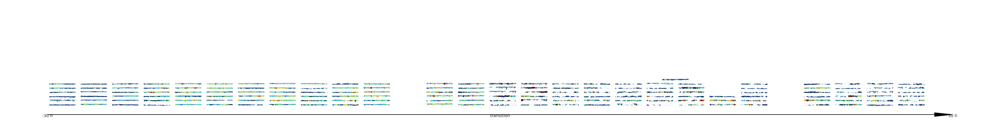

In [199]:
# create a big figure with many small subplots to compare the different trajectory sets
# the subplots are at x-positions determined by the transition_time_diff values, and y-positions determined s.t. plots dont overlap
hue_variable = 'rwc_cbh'  # can be 'rain_rate_cbh', 'lwp'

fig = plt.figure(figsize=(50, 10))
# Track occupied positions to avoid overlaps
occupied_positions = []  # List of (left, right, bottom, top) rectangles
subplot_width = 0.025
subplot_height = 0.015

time_min, time_max = -30, 30

sns.set_context('talk', font_scale=0.8)

bt_tmp = bt_co_concat.where(bt_co_concat.transition_flag == 1, drop=True)


for i, dt_ in enumerate(np.unique(bt_tmp.transition_time_diff.values)):
    print(dt_)
    bt_tmp_dt = bt_tmp.where(bt_tmp.transition_time_diff == dt_, drop=True)
    number_of_plots = min(6, len(bt_tmp_dt.time_startpoint.values))
    chosen_time_startpoints =np.random.choice(bt_tmp_dt.time_startpoint.values, size=number_of_plots, replace=False)

    for t_ in chosen_time_startpoints:
        bt_tmp_t = bt_tmp.sel(time_startpoint=t_)
        orbit, lat_min, lat_max = bt_tmp_t.orbit.values, bt_tmp_t.lat_min.values, bt_tmp_t.lat_max.values

        acmcap_scene = acmcap_1km[(acmcap_1km.orbit == orbit) & (acmcap_1km.lat_min >= lat_min) & (acmcap_1km.lat_max <= lat_max)]


        def add_profile(profile_arr, cbh_m, cth_m):
            # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
            for i in range(len(cth_m)):
                cbh = cbh_m.values[i]
                cth = cth_m.values[i]
                if np.isnan(cbh) or np.isnan(cth):
                    continue
                cbh_idx = int(cbh // 100)
                cth_idx = int(cth // 100)
                # Ensure indices are within bounds
                cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
                cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
                profile_arr[i, cbh_idx:cth_idx+1] += 1
            return profile_arr
        
        x_length = len(acmcap_scene.latitude)
        profile_arr = xr.DataArray(np.zeros((x_length, 20)), dims=['latitude', 'height'], coords={'latitude': acmcap_scene.latitude.values, 'height': np.arange(20)*100})
        profile_arr = add_profile(profile_arr, acmcap_scene.cbh_m, acmcap_scene.cth_m)
        
        # Calculate normalized x position
        norm_x = (dt_ - time_min) / (time_max - time_min)
        left = 0.05 + norm_x * 0.9  # Use 90% of figure width
        right = left + subplot_width
        
        # Find available vertical position
        bottom = 0.1  # Start from bottom
        found_position = False
        
        while not found_position:
            top = bottom + subplot_height
            
            # Check if this position overlaps with any existing subplot
            overlaps = False
            for occupied in occupied_positions:
                occ_left, occ_right, occ_bottom, occ_top = occupied
                
                # Check for overlap
                if (left < occ_right and right > occ_left and 
                    bottom < occ_top and top > occ_bottom):
                    overlaps = True
                    break
            
            if not overlaps:
                found_position = True
            else:
                bottom += subplot_height + 0.005  # Move up with small gap
        
        # Record this position as occupied
        occupied_positions.append((left, right, bottom, top))
        
        # Create the subplot
        ax = fig.add_axes([left, bottom, subplot_width, subplot_height])
        
        im1 = ax.imshow(profile_arr.T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='Blues')
        if hue_variable == 'rwp':
            im2 = ax.imshow((profile_arr * acmcap_scene.rwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='turbo', norm=LogNorm(5e-3, 5e-1))
            #plt.colorbar(im2, ax=ax, label='RR / kg m$^{-2}$ s$^{-1}$')
        elif hue_variable == 'rwc_cbh':
            im2 = ax.imshow((profile_arr * acmcap_scene.rwc_cbh.values[:, np.newaxis] * 1e3).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='turbo', norm=LogNorm(5e-4, 1e-1))
        elif hue_variable == 'lwp':
            im2 = ax.imshow((profile_arr * acmcap_scene.lwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='turbo', norm=LogNorm(1e-4, 5e-1))
            #plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
        #ax.set_xticks(ticks=np.linspace(0, x_length, 3), labels=[f'{lat:.2f}' for lat in np.linspace(acmcap_scene.latitude.values[0], acmcap_scene.latitude.values[-1], 3)])
        #ax.set_title(f'{orbit}, $\Delta$t={time_to_trans}, Scene ID {scene_id}')
        ax.set_axis_off()  # Turn off axis for small plots

# add vertical line at transition time
norm_x = (0 - time_min) / (time_max - time_min)
plt.vlines(x=0.05 + norm_x * 0.9, ymin=0, ymax=1, color='red', linestyle='-', lw=3 )

#max_y_position = np.max([occupied_positions[i][1] for i in range(len(occupied_positions))])
ax = fig.add_axes([0.95, 0.5, 0.01, 0.1])  # Position for colorbar
if hue_variable == 'rwp':
    plt.colorbar(im2, ax=ax, label='RWP / kg m$^{-2}$')
elif hue_variable == 'lwp':
    plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
ax.set_axis_off()

# plot one big time arrow at the bottom to indicate time axis
ax = fig.add_axes([0.05, 0.05, 0.95, 0.02])  # Position for time axis
ax.arrow(0, 0.5, 1, 0, head_width=0.03, head_length=0.02, length_includes_head=True, fc='black', ec='black')
ax.text(0, 0.48, f'{time_min} h', ha='center')
ax.text(1, 0.48, f'{time_max} h', ha='center')
ax.text(0.5, 0.48, f'transition', ha='center')
ax.set_axis_off()

#### X-MET

In [3]:
import sys
sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_msi/')
from access_ec_on_maap import *

In [4]:
def get_ccd_via_maap(datetime_range=None, 
                        region=None, 
                        frame=None,
                        orbitNumber=None,
                        ec_collection = ['EarthCAREL2Validated_MAAP'],
                        ccd_variables=None,
                        max_items=1
                        ):
    """Function to access EarthCARE C-CD data via MAAP."""

    ds_url_list = get_ec_data_url_via_maap(datetime_range, 'CPR_CD__2A', region, frame, orbitNumber=orbitNumber, ec_collection=ec_collection, max_items=max_items)

    print("Fetching ESA MAAP token...")
    ESA_TOKEN = get_token()
    fs = fsspec.filesystem(
        "https",
        headers={"Authorization": f"Bearer {ESA_TOKEN}"},
        **io_params["fsspec_params"]  )

    CCD_list = []
    for ds_url, orbit in ds_url_list:
        print("Dataset URL:", ds_url)
        print("Orbit:", orbit)
        # Open the file and read it into an xarray Dataset
        with fs.open(ds_url, "rb") as f:
            with xr.open_dataset(f,
                                engine="h5netcdf",
                                **io_params["h5py_params"],
                                group="ScienceData") as CCD:
                # Select only the requested variables
                if ccd_variables is not None:
                    CCD = CCD[ccd_variables]
                CCD.encoding = {'source': ds_url}  # Keep track of source URL
                if region is not None:
                    print(f"Cropping to region {region}... lat_min, lat_max = {bbox_regions[region]['lat']}, lon_min, lon_max = {bbox_regions[region]['lon']}")
                    print(f"\tbefore cropping: lat_min, lat_max = {CCD.latitude.min().values:.2f}, {CCD.latitude.max().values:.2f}, lon_min, lon_max = {CCD.longitude.min().values:.2f}, {CCD.longitude.max().values:.2f}")
                    CCD = crop_to_stcu_region(CCD, region)
                    print(f" \tafter cropping: lat_min, lat_max = {CCD.latitude.min().values:.2f}, {CCD.latitude.max().values:.2f}, lon_min, lon_max = {CCD.longitude.min().values:.2f}, {CCD.longitude.max().values:.2f}")
                if CCD is None:
                    continue
                CCD = CCD.load() # Load data into memory
        CCD_list.append((CCD, orbit))
    return CCD_list

### OC transitions

Transition statistics:
Trajectories with transitions: 126
Total trajectories: 1184


/tmp/ipykernel_3808051/2641059011.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Orbit Startpoint', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)


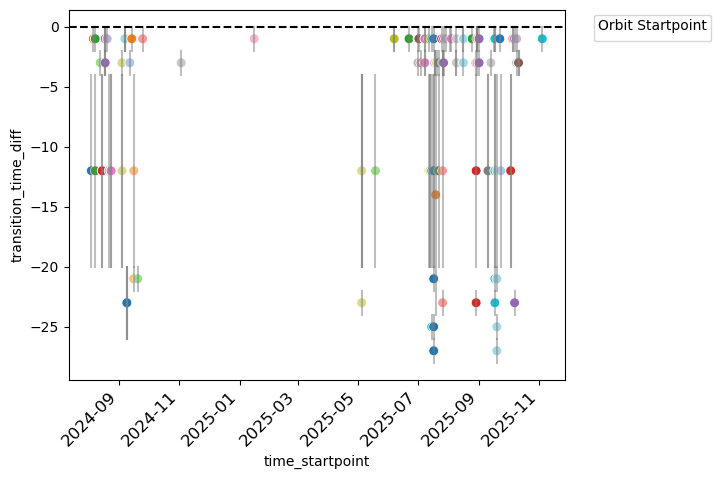

In [15]:
# O -> C transitions
bt_oc_forward_from_o = get_transition_properties(bt_O, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=False)

# Check results
print("Transition statistics:")
print(f"Trajectories with transitions: {(~pd.isna(bt_oc_forward_from_o.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_oc_forward_from_o.time_startpoint)}")


sns.scatterplot(data = bt_oc_forward_from_o, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=False, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_oc_forward_from_o.time_startpoint)):
    if not pd.isna(bt_oc_forward_from_o.transition_time_diff.values[i]):
        plt.plot([bt_oc_forward_from_o.time_startpoint.values[i], bt_oc_forward_from_o.time_startpoint.values[i]], 
                 [bt_oc_forward_from_o.transition_time_diff.values[i] - bt_oc_forward_from_o.transition_uncertainty.values[i],
                  bt_oc_forward_from_o.transition_time_diff.values[i] + bt_oc_forward_from_o.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit Startpoint', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

In [16]:
bt_oc_forward_from_o['time_startpoint'] = bt_oc_forward_from_o.time_startpoint.dt.round('0.1s')

# Align datasets along common dimensions first
bt_aligned, acmcap_aligned = xr.align(bt_oc_forward_from_o, ds_acmcap, join='left')

# Then merge
bt_oc_forward_from_o = bt_aligned.merge(acmcap_aligned)

In [20]:
tmp = bt_oc_forward_from_o.where(bt_oc_forward_from_o.transition_flag==1,drop=True)[['orbit','transition_time_diff','rwp','lwp','lat_mid','lon_mid']]
for i in range(len(tmp.orbit)):
    print(f"Orbit: {tmp.orbit.values[i]}, Transition Time Diff: {tmp.transition_time_diff.values[i]:.2f} h, Lat: {tmp.lat_mid.values[i]:.2f}, Lon: {tmp.lon_mid.values[i]:.2f}")

Orbit: 01040E, Transition Time Diff: -12.00 h, Lat: -11.92, Lon: -85.23
Orbit: 01071E, Transition Time Diff: -1.00 h, Lat: -9.32, Lon: -82.58
Orbit: 01102E, Transition Time Diff: -12.00 h, Lat: -14.53, Lon: -81.37
Orbit: 01102E, Transition Time Diff: -1.00 h, Lat: -19.74, Lon: -82.39
Orbit: 01180E, Transition Time Diff: -3.00 h, Lat: -17.66, Lon: -87.83
Orbit: 01211E, Transition Time Diff: -12.00 h, Lat: -15.06, Lon: -84.92
Orbit: 01211E, Transition Time Diff: -12.00 h, Lat: -15.58, Lon: -85.02
Orbit: 01258E, Transition Time Diff: -1.00 h, Lat: -6.19, Lon: -91.09
Orbit: 01258E, Transition Time Diff: -1.00 h, Lat: -6.72, Lon: -91.19
Orbit: 01258E, Transition Time Diff: -1.00 h, Lat: -7.24, Lon: -91.29
Orbit: 01258E, Transition Time Diff: -3.00 h, Lat: -7.76, Lon: -91.39
Orbit: 01258E, Transition Time Diff: -3.00 h, Lat: -8.28, Lon: -91.48
Orbit: 01258E, Transition Time Diff: -3.00 h, Lat: -9.85, Lon: -91.78
Orbit: 01289E, Transition Time Diff: -1.00 h, Lat: -7.76, Lon: -88.84
Orbit: 013

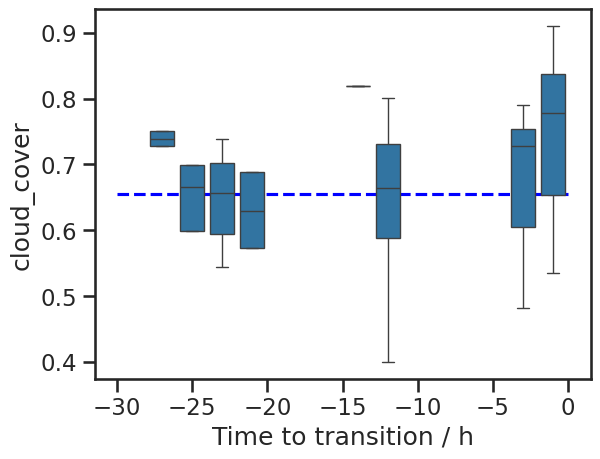

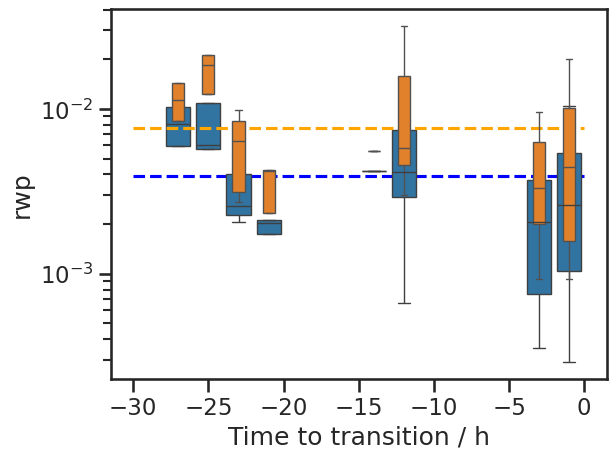

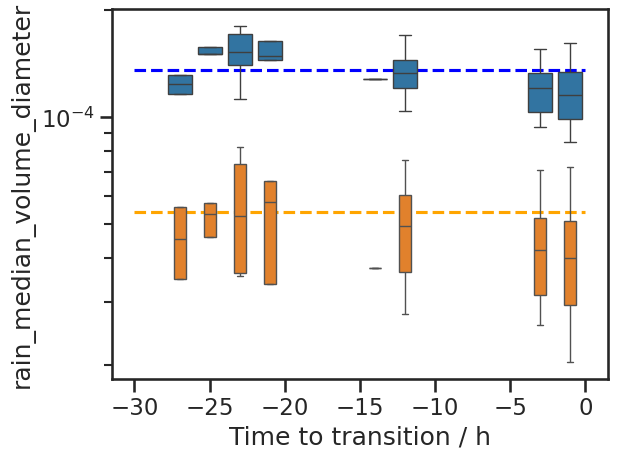

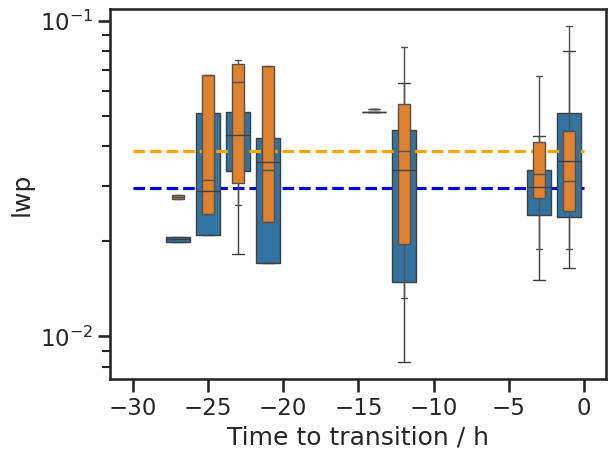

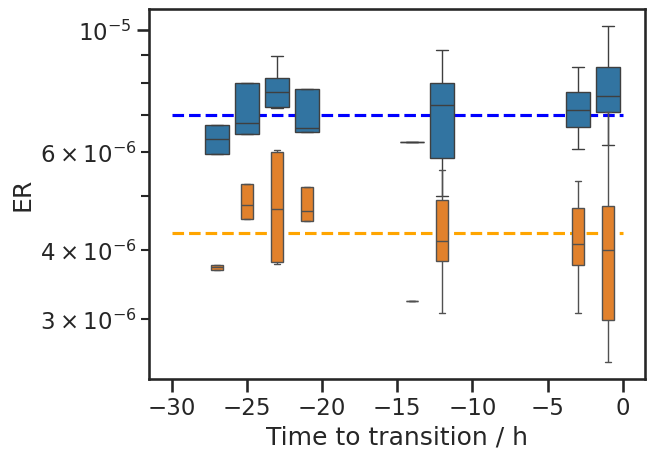

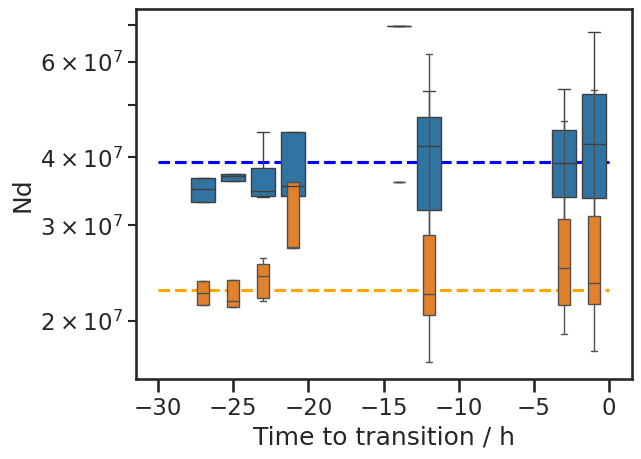

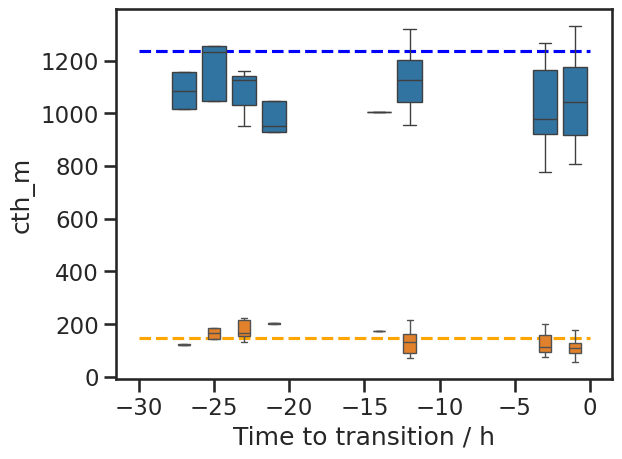

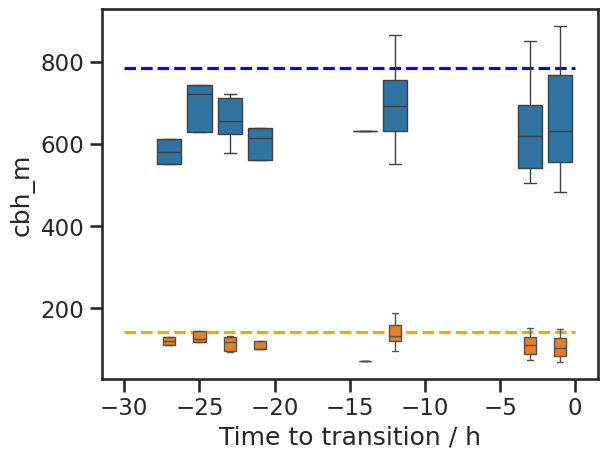

In [125]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False


for var, ylim, yscale in [('cloud_cover', (0, 1), 'linear'),
                          ('rwp', (9e-2, 5e1), 'log'), 
                          ('rain_median_volume_diameter', (1e-5, 1e-3), 'log'),
                          ('lwp', (1e-2, 2e-1), 'log'), 
                          ('ER', (5e-6, 2e-5), 'log'),
                          ('Nd', (1e7, 1e9), 'log'),
                          ('cth_m', (0, 3000), 'linear'),
                          ('cbh_m', (0, 3000), 'linear')
                          ]:
    plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=-30, xmax=0, color='blue', linestyle='--')
    sns.boxplot(data = bt_oc_forward_from_o, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=2, showfliers=False)
    try:
        plt.hlines(acmcap_climatology_median[var+'_std'].sel(cats=2), xmin=-30, xmax=0, color='orange', linestyle='--')
        sns.boxplot(data = bt_oc_forward_from_o, x='transition_time_diff', y=var+'_std', whis=(5, 95), native_scale=True, gap=1.5, showfliers=False)
    except KeyError:
        pass
    plt.yscale(yscale)
    #plt.ylim(ylim)
    plt.xlabel('Time to transition / h')
    plt.show()